# Ordinary Co-Kriging - Lagunazo Mine Waste (ICP geochemistry)

## 1 · Imports & Configuration

In [1]:
import os, re, io, json, time, math, zipfile, hashlib, platform, warnings
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from pathlib import Path
from IPython.display import display, HTML
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import scipy
import openpyxl
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy import stats
from scipy.optimize import nnls, minimize_scalar

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patheffects as mpe
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch, Rectangle, PathPatch
from matplotlib.lines import Line2D
from matplotlib.path import Path as MPath

try:
    import contextily as ctx
    CTX_OK = True
except ImportError:
    ctx, CTX_OK = None, False
    print("warning: contextily not found - basemap disabled (pip install contextily).")
try:
    import pyproj
    from pyproj import Transformer
except ImportError:
    raise ImportError("pyproj is required for the WGS 84 -> UTM 29N projection (pip install pyproj).")
try:
    import shapely
    from shapely.geometry import Polygon as ShapelyPolygon, MultiPolygon, MultiPoint, Point
    from shapely.ops import unary_union
    SHAPELY_OK = True
except ImportError:
    shapely, SHAPELY_OK = None, False
    print("warning: shapely not found - polygon handling falls back to matplotlib (pip install shapely).")
# pandas' Styler (.style) needs a recent jinja2; test it through pandas itself (an old jinja2 imports fine
# but pandas still refuses .style). Without it, tables are shown as plain HTML.
try:
    pd.DataFrame({"a": [1]}).style.to_html()
    JINJA_OK = True
except Exception:
    JINJA_OK = False
    print("note: pandas table styling unavailable (jinja2 missing or too old) - tables are shown as plain HTML.")

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 400, "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "font.family": "DejaVu Sans", "font.size": 10, "axes.axisbelow": True,
    "axes.linewidth": 1.0, "xtick.direction": "in", "ytick.direction": "in"})

# Input files
ICP_XLSX   = "ICP-DATA_2026.xlsx"          # laboratory Final Report workbook
SHEET_DATA = "Analytical Data"
SHEET_QC   = "QC Data"
SHEET_LOC  = "Locations"
KMZ_FILE   = "Lagunazo_waste_area.kmz"     # mine-waste boundary polygon (same file as the pXRF notebooks)
OUT_DIR    = "results_CoK_ICP"

# Elements
ELEMENTS   = None     # primaries: None = every CRM analyte eligible in Section 5 | "Bi" | ["Bi", "Sb"]
VAR_NAME   = "Bi"     # primary whose figures and audit are shown in full (the r1 primary)
SECONDARY_POOL     = "crm"   # "crm" = the other eligible CRM analytes | "all" = every eligible AQ251 analyte | list
SECONDARY_OVERRIDE = {}      # force a pair, e.g. {"Bi": "Sb"}; empty = automatic selection
EPSG_UTM   = "EPSG:32629"

# Sample-ID reconciliation
LAB_TO_FIELD_PREFIX = {"LA": "LG"}
LOCATION_ID_FIXES = [
    dict(no=13, recorded="LG-35-31", corrected="LG-25-31", kind="typo",
         reason="year field '35' is a typo; point lies in the LG-25-33 -> 31 -> 29 field sequence"),
    dict(no=23, recorded="LH-25-06", corrected="LG-25-06", kind="typo",
         reason="prefix 'LH' is a typo; point lies in the LG-25-07 -> 06 -> 05 field sequence"),
    dict(no=29, recorded="LG-25-34", corrected="LG-25-24", kind="inferred",
         reason="LG-25-34 is recorded twice (No. 29 and No. 44) and LG-25-24 is otherwise missing; "
                "No. 29 lies between LG-25-25 and LG-25-23 in the field sequence"),
]
APPLY_INFERRED_FIXES = True

# Censored assays and eligibility
BDL_FACTOR     = 0.5    # "<MDL" -> BDL_FACTOR x MDL
ODL_FACTOR     = 1.0    # ">UDL" -> the upper limit (a LOWER BOUND - flagged everywhere)
MIN_QUANT_FRAC = 0.70   # min. fraction of located samples quantified (not <MDL, not >UDL)
MIN_N_MAP      = 15     # min. number of located samples

# Stage 1 screening
STATION_TOL_M     = 5.0
MIN_STATIONS      = 10
MIN_PAIRS_TOTAL   = 45
MIN_DISTINCT_VALS = 5
ADVISORY_STATIONS = 30

# Stage 2 pair selection
PAIR_SELECT_ON    = "spearman"   # "spearman" | "pearson"
PAIR_N_BOOTSTRAP  = 2000
PAIR_N_PERM       = 999          # permutations for the p-value of the MAXIMUM |rho| over the pool
PAIR_SEED         = 42
WEAK_PAIR_ABS_RHO = 0.50         # below this the covariate cannot materially change the estimate (flag only)

# Stage 3 transforms, variograms, LMC
TRANSFORM_CANDIDATES   = ["none", "log", "nscore"]
TRANSFORM_MIN_GAIN_PCT = 2.0         # a transform must beat "none" (co-kriging mapping RMSE, grade units) by this much
LOG_BACKTRANSFORM      = "journel"   # "journel": exp(y+s2/2-mu)-c with the CO-KRIGING multiplier | "naive" | "median"
NSCORE_BACKTRANSFORM   = "expectation"   # "expectation" (Gauss-Hermite over N(y*, s2)) | "median" (table look-up)
NSCORE_UPPER_OMEGA     = 1.5    # GSLIB hyperbolic upper tail beyond the largest datum
NSCORE_ZMAX_FACTOR     = 2.0    # ... capped at this multiple of the largest datum (lower tail: linear to 0)
GH_NODES               = 24
N_LAGS_MAX     = 15
MIN_PAIRS_LAG  = 30
CUTOFF_FACTOR  = 0.50                # x the largest station separation (ICP OK notebook; r1 used 0.55)
VGM_WEIGHTING  = "pair_count"        # "pair_count" | "cressie" | "none"
RANGE_GRID_N   = 60                  # grid search over the common range before refinement
BOUND_TOL_FRAC = 0.01                # a range within 1 % of the search interval from a bound is 'on bound'

# Solver
STANDARDISE_VARIABLES = True   # both variables divided by sqrt(LMC sill) before assembly
JITTER_REL            = 1e-10  # relative to C(0) = 1 after standardisation
COND_WARN             = 1e10
K_SENSITIVITY         = [8, 16, 24, None]   # audit only: LOOCV with the K nearest stations (None = global, adopted)

# Validation
N_BOOT          = 2000   # bootstrap resamples for the uncertainty of the nested R2
MARGINAL_P      = 0.25   # 'marginal' if bootstrap P(R2 < MIN_R2_SURFACE) >= this
MIN_R2_SURFACE  = 0.10   # surface only if the NESTED-CV R2 of co-kriging (grade units) >= this
CK_GAIN_MIN_PCT = 2.0    # co-kriging 'adds nothing' if it changes the nested RMSE of kriging by less than this
N_MC_JOURNEL    = 100000 # Monte Carlo realisations for the lognormal-correction audit

# Grid & display
GRID_DENSITY_M = 3.0    # identical grid to the ICP IDW / OK notebooks -> co-registered rasters
PAD_FRAC       = 0.06
USE_BASEMAP    = True
BASEMAP_ALPHA  = 0.70   # r1
SURFACE_ALPHA  = 0.88   # r1
CLASS_SCHEME       = "equal"     # VAR_NAME maps: rounded equal intervals over CK and OK together (r1) | "quantile"
ATLAS_CLASS_SCHEME = "quantile"  # other elements and the atlas: station percentiles P0-10-25-50-75-90-95-100
N_GRADE_CLASSES, N_SE_CLASSES = 7, 6
GRADE_CMAP, SE_CMAP, DIFF_CMAP, SERED_CMAP = "turbo", "cividis", "RdBu_r", "PuOr_r"
HATCH_EXTRAP   = True   # hatch ground farther from any station than the largest nearest-neighbour distance
SHOW_SAMPLES   = True
SAVE_ELEMENT_FIGURES = True
FIG_DPI        = 300

if not Path(ICP_XLSX).exists():
    raise FileNotFoundError(f"'{ICP_XLSX}' not found in {Path.cwd()} - place the laboratory workbook next to this notebook.")
os.makedirs(OUT_DIR, exist_ok=True)
RUN_STARTED = datetime.now(timezone.utc).isoformat(timespec="seconds")

def outpath(*parts):
    p = os.path.join(OUT_DIR, *parts)
    os.makedirs(os.path.dirname(p), exist_ok=True)
    return p

print("Configuration loaded.")
print(f"  Workbook  : {ICP_XLSX}   |   outputs -> {OUT_DIR}/")
print(f"  Primaries : {'all eligible CRM analytes' if ELEMENTS is None else ELEMENTS}   |   detail primary: {VAR_NAME}")
print(f"  Secondary : pool '{SECONDARY_POOL}', selected on {PAIR_SELECT_ON}"
      + (f", overrides {SECONDARY_OVERRIDE}" if SECONDARY_OVERRIDE else ""))
print(f"  LMC       : nugget + spherical, common range, cutoff {CUTOFF_FACTOR} x max separation, "
      f"lags >= {MIN_PAIRS_LAG} pairs")
print(f"  Transforms {TRANSFORM_CANDIDATES}; log back-transform '{LOG_BACKTRANSFORM}', nscore '{NSCORE_BACKTRANSFORM}'")

note: pandas table styling unavailable (jinja2 missing or too old) - tables are shown as plain HTML.
Configuration loaded.
  Workbook  : ICP-DATA_2026.xlsx   |   outputs -> results_CoK_ICP/
  Primaries : all eligible CRM analytes   |   detail primary: Bi
  Secondary : pool 'crm', selected on spearman
  LMC       : nugget + spherical, common range, cutoff 0.5 x max separation, lags >= 30 pairs
  Transforms ['none', 'log', 'nscore']; log back-transform 'journel', nscore 'expectation'


## 2 · Core Routines

Quality log, tables, stations, declustering and metrics (as in the ICP OK notebook, plus r1's quality log), then the
LMC, the co-kriging engine and the transforms.

In [2]:
# quality log
QC_LOG = []

def qc(level, stage, message):
    """Record a quality event (INFO / WARN / DROP); printed in the summary and exported."""
    QC_LOG.append({"level": level, "stage": stage, "message": message})

def qc_report():
    if not QC_LOG:
        print("No quality events recorded.")
        return
    order = {"DROP": 0, "WARN": 1, "INFO": 2}
    for lvl in sorted({e["level"] for e in QC_LOG}, key=lambda l: order.get(l, 9)):
        items = [e for e in QC_LOG if e["level"] == lvl]
        print(f"\n{lvl} ({len(items)})")
        for e in items:
            print(f"  [{e['stage']}] {e['message']}")


# tables
_STATUS_CSS = {"PASS": "background-color:#eafaf1;color:#1e8449;font-weight:bold",
               "WARN": "background-color:#fef9e7;color:#b7950b;font-weight:bold",
               "FAIL": "background-color:#fdedec;color:#922b21;font-weight:bold",
               "INFO": "background-color:#eaf2f8;color:#1a5276;font-weight:bold"}

def show_table(df, precision=None, status_col=None):
    """Display a DataFrame without its index; Styler when available, plain HTML otherwise."""
    if JINJA_OK:
        try:
            sty = df.style
            if precision is not None:
                sty = sty.format(precision=precision, thousands=",")
            if status_col is not None:
                colour = sty.map if hasattr(sty, "map") else sty.applymap
                sty = colour(lambda v: _STATUS_CSS.get(v, ""), subset=[status_col])
            display(sty.hide(axis="index"))
            return
        except Exception:
            pass
    d = df.copy()
    if precision is not None:
        num = d.select_dtypes("number").columns
        d[num] = d[num].round(precision)
    html = d.to_html(index=False, na_rep="", escape=True)
    if status_col is not None:
        for key, css in _STATUS_CSS.items():
            html = html.replace(f"<td>{key}</td>", f'<td style="{css}">{key}</td>')
    display(HTML(html))


# stations
def collapse_stations(df, x_col, y_col, value_cols, tol_m=5.0, id_col=None):
    """Merge samples within tol_m (single linkage) into one station; every value column is averaged over the
    station's samples (NaN-aware). Returns (stations, report)."""
    d = df.reset_index(drop=True).copy()
    xy = d[[x_col, y_col]].to_numpy(float)
    parent = np.arange(len(d))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for a, b in cKDTree(xy).query_pairs(r=max(tol_m, 1e-9)):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[max(ra, rb)] = min(ra, rb)
    d["_station"] = [find(i) for i in range(len(d))]
    g = d.groupby("_station", sort=True)
    out = g[[x_col, y_col] + list(value_cols)].mean()
    out["n_reps"] = g.size()
    if id_col:
        out[id_col] = g[id_col].agg(lambda s: "+".join(map(str, s)))
    out = out.reset_index(drop=True)
    rep = dict(n_samples=int(len(d)), n_stations=int(len(out)), n_stations_with_reps=int((out["n_reps"] > 1).sum()))
    return out, rep


# declustering
def declustering_weights(coords, values, cell_sizes=None, n_origins=12, target="min_mean", seed=0):
    """Cell declustering (GSLIB declus): origin-averaged weights (mean 1) at the cell size that minimises
    (or maximises) the declustered mean. Returns (weights, cell_size_m, table)."""
    coords, v = np.asarray(coords, float), np.asarray(values, float)
    n = len(v)
    if n < 3:
        return np.ones(n), np.nan, pd.DataFrame()
    if cell_sizes is None:
        nn = float(np.median(cKDTree(coords).query(coords, k=2)[0][:, 1]))
        ext = float(max(np.ptp(coords[:, 0]), np.ptp(coords[:, 1])))
        cell_sizes = np.unique(np.round(np.linspace(max(nn, 1.0), max(ext / 2.0, nn * 1.01), 24), 1))
    rng = np.random.default_rng(seed)
    x0, y0 = coords[:, 0].min(), coords[:, 1].min()
    rows, W = [], {}
    for cs in cell_sizes:
        acc = np.zeros(n)
        for o in range(n_origins):
            ox, oy = (0.0, 0.0) if o == 0 else (rng.uniform(0, cs), rng.uniform(0, cs))
            ix = np.floor((coords[:, 0] - x0 + ox) / cs).astype(np.int64)
            iy = np.floor((coords[:, 1] - y0 + oy) / cs).astype(np.int64)
            _, inv, cnt = np.unique(np.column_stack([ix, iy]), axis=0, return_inverse=True, return_counts=True)
            w = 1.0 / cnt[np.asarray(inv).ravel()]
            acc += w * n / w.sum()
        w = acc / n_origins
        w *= n / w.sum()
        W[float(cs)] = w
        rows.append((float(cs), float(np.sum(w * v) / n)))
    tab = pd.DataFrame(rows, columns=["cell_size_m", "declustered_mean"])
    i = tab["declustered_mean"].idxmin() if target == "min_mean" else tab["declustered_mean"].idxmax()
    cs = float(tab.loc[i, "cell_size_m"])
    return W[cs], cs, tab


# metrics
def metrics(y_true, y_pred, label=""):
    """Cross-validation statistics in grade units."""
    yt, yp = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[ok], yp[ok]
    if yt.size < 2:
        return {}
    res = yp - yt
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    rmse = float(np.sqrt(np.mean(res ** 2)))
    good = np.std(yt) > 0 and np.std(yp) > 0
    return dict(
        Label=label, n=int(yt.size), RMSE=rmse, MAE=float(np.mean(np.abs(res))), ME_bias=float(res.mean()),
        Rel_bias_pct=float(100 * res.mean() / yt.mean()) if yt.mean() else np.nan,
        R2_pred=float(1 - np.sum(res ** 2) / ss_tot) if ss_tot > 0 else np.nan,
        Pearson_r=float(np.corrcoef(yt, yp)[0, 1]) if good else np.nan,
        Spearman_r=float(stats.spearmanr(yt, yp)[0]) if good else np.nan,
        Slope_obs_on_pred=float(stats.linregress(yp, yt)[0]) if good else np.nan,   # conditional bias, ideal 1
        Var_ratio=float(np.var(yp, ddof=1) / np.var(yt, ddof=1)) if np.var(yt) > 0 else np.nan)

def boot_r2(obs, pred, n_boot=N_BOOT, seed=11):
    """Bootstrap of (observed, predicted) pairs -> (5th, 95th percentile of R2, P(R2 < MIN_R2_SURFACE))."""
    o, p = np.asarray(obs, float), np.asarray(pred, float)
    ok = np.isfinite(o) & np.isfinite(p)
    o, p = o[ok], p[ok]
    rng = np.random.default_rng(seed)
    b = []
    for _ in range(n_boot):
        j = rng.integers(0, len(o), len(o))
        sst = np.sum((o[j] - o[j].mean()) ** 2)
        if sst > 0:
            b.append(1 - np.sum((p[j] - o[j]) ** 2) / sst)
    b = np.asarray(b)
    return (float(np.percentile(b, 5)), float(np.percentile(b, 95))), float(np.mean(b < MIN_R2_SURFACE))

print("Quality log, tables, stations, declustering and metrics loaded.")

Quality log, tables, stations, declustering and metrics loaded.


### 2.1 · Linear Model of Coregionalization

Every structure is **nugget + spherical on one common range `a`**:
`γ_kl(h) = b⁰_kl·g₀(h) + b¹_kl·Sph(h; a)`, with `C_kl(h) = b⁰_kl + b¹_kl − γ_kl(h)`. The LMC is valid (positive
semi-definite) if and only if each 2 × 2 coregionalisation matrix `B⁰`, `B¹` is PSD; for two variables that is
`b_kk ≥ 0` and `b₁₂² ≤ b₁₁·b₂₂` per structure (Cauchy–Schwarz). Isotopic sampling means γ₁₁, γ₂₂ and γ₁₂ are computed
on the same pairs, so one set of equal-count lags serves all three.

In [3]:
def g_sph(h, a):
    t = np.clip(np.asarray(h, float) / max(a, 1e-9), 0.0, 1.0)
    return 1.5 * t - 0.5 * t ** 3

def gamma_lmc(h, b0, b1, a):
    h = np.asarray(h, float)
    return np.where(h > 1e-9, b0 + b1 * g_sph(h, a), 0.0)

def cov_lmc(h, b0, b1, a):
    """C(h) = C(0) - gamma(h), C(0) = b0 + b1."""
    return (b0 + b1) - gamma_lmc(h, b0, b1, a)


def lmc_variograms(coords, y1, y2, cutoff, min_pairs=MIN_PAIRS_LAG, n_lags_max=N_LAGS_MAX):
    """Experimental direct (11, 22) and cross (12) semivariograms on EQUAL-COUNT lags (every lag >= min_pairs
    pairs by construction); the lag centre is the mean pair distance (r1 fix K10)."""
    coords, y1, y2 = np.asarray(coords, float), np.asarray(y1, float), np.asarray(y2, float)
    iu, ju = np.triu_indices(len(y1), k=1)
    h = np.hypot(coords[iu, 0] - coords[ju, 0], coords[iu, 1] - coords[ju, 1])
    d1, d2 = y1[iu] - y1[ju], y2[iu] - y2[ju]
    keep = (h > 0) & (h <= cutoff)
    h, d1, d2 = h[keep], d1[keep], d2[keep]
    n_lags = int(min(n_lags_max, h.size // max(min_pairs, 1)))
    cols = ["lag", "h_mean", "h_min", "h_max", "n_pairs", "g11", "g22", "g12"]
    if n_lags < 1:
        return pd.DataFrame(columns=cols)
    order = np.argsort(h, kind="mergesort")
    rows = []
    for i, s in enumerate(np.array_split(order, n_lags)):
        rows.append((i + 1, h[s].mean(), h[s].min(), h[s].max(), s.size, 0.5 * np.mean(d1[s] ** 2),
                     0.5 * np.mean(d2[s] ** 2), 0.5 * np.mean(d1[s] * d2[s])))
    return pd.DataFrame(rows, columns=cols)


def _vw(g, cnt, scheme=VGM_WEIGHTING):
    cnt = np.asarray(cnt, float)
    if scheme == "none":
        return np.ones_like(cnt)
    if scheme == "cressie":
        return cnt / np.maximum(np.abs(np.asarray(g, float)), 1e-12) ** 2
    return cnt

def fit_sills(h, g, cnt, a, allow_negative):
    """Weighted least-squares (nugget, spherical sill) at a fixed range; NNLS for direct structures (r1 K9)."""
    M = np.column_stack([np.ones_like(h), g_sph(h, a)])      # every lag has h > 0, so g0(h) = 1
    w = np.sqrt(_vw(g, cnt))
    Mw, gw = M * w[:, None], np.asarray(g, float) * w
    b = np.linalg.lstsq(Mw, gw, rcond=None)[0] if allow_negative else nnls(Mw, gw)[0]
    return float(b[0]), float(b[1])

def weighted_r2(h, g, cnt, b0, b1, a):
    w = _vw(g, cnt)
    pred = gamma_lmc(h, b0, b1, a)
    sst = np.sum(w * (g - np.average(g, weights=w)) ** 2)
    return float(1 - np.sum(w * (g - pred) ** 2) / sst) if sst > 0 else np.nan


def fit_lmc(vgm, cutoff):
    """Common range fitted JOINTLY over gamma_11, gamma_22 and gamma_12 (r1 fix K8): the pair-count-weighted SSE of
    each structure is normalised by its own scale and summed. Grid search over RANGE_GRID_N ranges, then bounded
    refinement around the best grid point (guards against a local minimum). Cross sills are clipped to satisfy
    b12^2 <= b11*b22 per structure, which is necessary and sufficient for a valid 2-variable LMC: set to 0 where a
    direct structure is absent (cross_zeroed), clipped to |rho| = 0.999 where it overshoots (psd_clipped)."""
    h, cnt = vgm["h_mean"].to_numpy(float), vgm["n_pairs"].to_numpy(float)
    G = {k: vgm[f"g{k}"].to_numpy(float) for k in ("11", "22", "12")}
    scale = {k: max(np.average(np.abs(G[k]), weights=_vw(G[k], cnt)), 1e-300) for k in G}
    r_lo = float(max(0.5 * h.min(), 1.0))
    r_hi = float(max(1.5 * cutoff, 4 * r_lo))

    def obj(a):
        tot = 0.0
        for k in ("11", "22", "12"):
            b0, b1 = fit_sills(h, G[k], cnt, a, allow_negative=(k == "12"))
            w = _vw(G[k], cnt)
            tot += np.sum(w * (G[k] - gamma_lmc(h, b0, b1, a)) ** 2) / (scale[k] ** 2 * w.sum())
        return tot

    grid = np.geomspace(r_lo, r_hi, RANGE_GRID_N)
    vals = np.array([obj(a) for a in grid])
    i = int(np.argmin(vals))
    lo_, hi_ = grid[max(i - 1, 0)], grid[min(i + 1, len(grid) - 1)]
    res = minimize_scalar(obj, bounds=(lo_, hi_), method="bounded", options={"xatol": max(0.05, 1e-4 * r_hi)})
    a = float(res.x) if res.fun <= vals[i] else float(grid[i])
    tol = BOUND_TOL_FRAC * (r_hi - r_lo)
    on_bound = "lower" if a - r_lo <= tol else "upper" if r_hi - a <= tol else ""

    coef = {k: fit_sills(h, G[k], cnt, a, allow_negative=(k == "12")) for k in ("11", "22", "12")}
    clipped, absent = [], []
    b12 = list(coef["12"])
    for j, nm in enumerate(("nugget", "spherical")):
        lim = np.sqrt(max(coef["11"][j] * coef["22"][j], 0.0))
        if lim <= 1e-9 * np.sqrt(scale["11"] * scale["22"]):
            if b12[j] != 0.0:                         # a direct structure is absent -> no cross structure possible
                absent.append((nm, b12[j], 0.0))
            b12[j] = 0.0
        elif abs(b12[j]) > 0.999 * lim:
            clipped.append((nm, b12[j], float(np.sign(b12[j]) * 0.999 * lim)))
            b12[j] = float(np.sign(b12[j]) * 0.999 * lim)
    coef["12"] = tuple(b12)
    lim0 = np.sqrt(max(coef["11"][0] * coef["22"][0], 0.0))
    lim1 = np.sqrt(max(coef["11"][1] * coef["22"][1], 0.0))
    return dict(range_m=a, coef=coef, r_lo=r_lo, r_hi=r_hi, on_bound=on_bound, psd_clipped=clipped, cross_zeroed=absent,
                fit_r2={k: weighted_r2(h, G[k], cnt, *coef[k], a) for k in ("11", "22", "12")},
                rho_struct={"nugget": coef["12"][0] / lim0 if lim0 > 0 else np.nan,
                            "spherical": coef["12"][1] / lim1 if lim1 > 0 else np.nan},
                profile=(grid, vals))


def autokrigeable(coef, tol=1e-6):
    """True if the cross-covariance is proportional to the primary covariance (b12 / b11 equal in every structure,
    including a structure absent from both). With isotopic data co-kriging then reduces EXACTLY to kriging
    (autokrigeability; Wackernagel, Multivariate Geostatistics, ch. 25): the secondary carries no extra information."""
    (a0, a1), (c0, c1) = coef["11"], coef["12"]
    scale = max(abs(c0) + abs(c1), 1e-300) * max(abs(a0) + abs(a1), 1e-300)
    return bool(abs(c0 * a1 - c1 * a0) <= tol * scale)


def make_model(fit):
    """Solver model: LMC coefficients, common range and the standardisation scales (sqrt of each LMC sill)."""
    c = fit["coef"]
    sill1, sill2 = c["11"][0] + c["11"][1], c["22"][0] + c["22"][1]
    s1 = float(np.sqrt(sill1)) if STANDARDISE_VARIABLES else 1.0
    s2 = float(np.sqrt(sill2)) if STANDARDISE_VARIABLES else 1.0
    return dict(coef=c, a=fit["range_m"], s1=s1, s2=s2, sill1=float(sill1), sill2=float(sill2))

print("LMC routines loaded.")

LMC routines loaded.


### 2.2 · Ordinary co-kriging engine

**System** (standardised covariance form; `ỹ₁ = y₁/s₁`, `ỹ₂ = y₂/s₂`, `s_k = √(b⁰_kk + b¹_kk)`):

```
[ C̃11  C̃12  1  0 ] [ w1 ]   [ c̃11(x0) ]        Σ w1 = 1   (primary weights)
[ C̃21  C̃22  0  1 ] [ w2 ] = [ c̃21(x0) ]        Σ w2 = 0   (secondary weights)
[ 1ᵀ   0ᵀ   0  0 ] [ ν1 ]   [    1     ]
[ 0ᵀ   1ᵀ   0  0 ] [ ν2 ]   [    0     ]
```

`y₁* = s₁·(w₁ᵀỹ₁ + w₂ᵀỹ₂)` (so the secondary weights in data units are `w₂·s₁/s₂`, still summing to 0);
`σ²_CK = s₁²·(C̃₁₁(0) − rhsᵀ·sol)`. The multiplier `ν₁` is in the **plus** convention and in standardised units; in
y₁ variance units it is `ν₁·s₁²`, and the semivariogram-form multiplier is `μ₁ = −ν₁·s₁²`.

**Lognormal correction.** With `Y* = Σλ₁Y₁ + Σλ₂Y₂`, `Σλ₁ = 1`, `Σλ₂ = 0`: `E[exp Y*] = exp(m₁ + wᵀKw/2)` while
`E[Z₀] = exp(m₁ + C₁₁(0)/2)`. Unbiasedness needs `exp(Y* + (C₁₁(0) − wᵀKw)/2)`, and from the system
`wᵀKw = wᵀk₀ − ν₁` so `(C₁₁(0) − wᵀKw)/2 = σ²/2 + ν₁ = σ²/2 − μ₁` — Journel's form with the co-kriging multiplier.

With an empty secondary set the same routine is ordinary kriging of the primary under γ₁₁ (the paired comparison
that isolates the covariate's contribution).

In [4]:
_EMPTY = np.empty((0, 2))

def ck_solve(model, P1, y1, P2, y2, T, return_weights=False, cond=False):
    """Ordinary co-kriging of the primary at targets T from primary data (P1, y1) and secondary data (P2, y2).
    One left-hand side, all targets as right-hand sides. P2 empty -> ordinary kriging of the primary.
    Returns dict(est, var, mu, nu, cond (if requested)[, W]); est and var in y1 (fit-space) units, mu = -nu*s1^2 (semivariogram
    convention, y1 variance units), nu = plus-convention multiplier of the primary constraint in y1 variance units."""
    c, a, s1, s2 = model["coef"], model["a"], model["s1"], model["s2"]
    P1, T = np.atleast_2d(np.asarray(P1, float)), np.atleast_2d(np.asarray(T, float))
    P2 = np.asarray(P2, float).reshape(-1, 2)
    y1, y2 = np.asarray(y1, float), np.asarray(y2, float)
    n1, n2 = len(P1), len(P2)
    m = n1 + n2
    size = m + 1 + (1 if n2 else 0)
    A = np.zeros((size, size))
    A[:n1, :n1] = cov_lmc(cdist(P1, P1), *c["11"], a) / s1 ** 2
    if n2:
        C12 = cov_lmc(cdist(P1, P2), *c["12"], a) / (s1 * s2)
        A[:n1, n1:m] = C12
        A[n1:m, :n1] = C12.T
        A[n1:m, n1:m] = cov_lmc(cdist(P2, P2), *c["22"], a) / s2 ** 2
        A[n1:m, m + 1] = 1.0
        A[m + 1, n1:m] = 1.0
    A[:n1, m] = 1.0
    A[m, :n1] = 1.0
    A[np.arange(m), np.arange(m)] += JITTER_REL
    R = np.zeros((size, len(T)))
    R[:n1] = cov_lmc(cdist(P1, T), *c["11"], a) / s1 ** 2
    if n2:
        R[n1:m] = cov_lmc(cdist(P2, T), *c["12"], a) / (s1 * s2)
    R[m] = 1.0
    try:
        W = np.linalg.solve(A, R)
    except np.linalg.LinAlgError:
        W = np.linalg.lstsq(A, R, rcond=None)[0]
    est = s1 * ((y1 / s1) @ W[:n1] + ((y2 / s2) @ W[n1:m] if n2 else 0.0))
    c0 = (c["11"][0] + c["11"][1]) / s1 ** 2
    var = s1 ** 2 * (c0 - np.einsum("ig,ig->g", R, W))
    nu = W[m] * s1 ** 2
    out = dict(est=est, var=var, mu=-nu, nu=nu, cond=float(np.linalg.cond(A)) if cond else np.nan)
    if return_weights:
        out.update(W=W, w1=W[:n1], w2_data=W[n1:m] * s1 / s2 if n2 else np.empty(0))
    return out


def ck_point_gamma(model, P1, y1, P2, y2, t):
    """INDEPENDENT reference: co-kriging at ONE target in the SEMIVARIOGRAM form, raw (unstandardised) units, no
    jitter:  [G11 G12 1 0; G21 G22 0 1; 1' 0' 0 0; 0' 1' 0 0][l1; l2; mu1; mu2] = [g11(x0); g21(x0); 1; 0],
    sigma2 = l1.g11(x0) + l2.g21(x0) + mu1. Used only in the audit."""
    c, a = model["coef"], model["a"]
    P1, P2, t = np.asarray(P1, float), np.asarray(P2, float).reshape(-1, 2), np.asarray(t, float).reshape(1, 2)
    n1, n2 = len(P1), len(P2)
    m = n1 + n2
    size = m + 1 + (1 if n2 else 0)
    A = np.zeros((size, size))
    A[:n1, :n1] = gamma_lmc(cdist(P1, P1), *c["11"], a)
    rhs = np.zeros(size)
    rhs[:n1] = gamma_lmc(cdist(P1, t)[:, 0], *c["11"], a)
    if n2:
        G12 = gamma_lmc(cdist(P1, P2), *c["12"], a)
        A[:n1, n1:m] = G12; A[n1:m, :n1] = G12.T
        A[n1:m, n1:m] = gamma_lmc(cdist(P2, P2), *c["22"], a)
        A[n1:m, m + 1] = 1; A[m + 1, n1:m] = 1
        rhs[n1:m] = gamma_lmc(cdist(P2, t)[:, 0], *c["12"], a)
    A[:n1, m] = 1; A[m, :n1] = 1
    rhs[m] = 1.0
    sol = np.linalg.solve(A, rhs)
    l1, l2, mu1 = sol[:n1], sol[n1:m], sol[m]
    est = l1 @ y1 + (l2 @ y2 if n2 else 0.0)
    var = l1 @ rhs[:n1] + (l2 @ rhs[n1:m] if n2 else 0.0) + mu1
    return float(est), float(var), float(mu1), l1, l2


def joint_cov(model, P1, P2):
    """Full covariance matrix K of [Y1(P1); Y2(P2)] under the LMC (raw units)."""
    c, a = model["coef"], model["a"]
    C11 = cov_lmc(cdist(P1, P1), *c["11"], a)
    C12 = cov_lmc(cdist(P1, P2), *c["12"], a)
    C22 = cov_lmc(cdist(P2, P2), *c["22"], a)
    return np.block([[C11, C12], [C12.T, C22]])

print("Co-kriging engine loaded.")

Co-kriging engine loaded.


In [5]:
# transforms
class Transform:
    """none | log | nscore with explicit, documented back-transforms of a (co-)kriged value.

    log    : y = ln(z + c). Back: 'journel' exp(y + s2/2 - mu) - c, with mu the semivariogram-form Lagrange
             multiplier of the PRIMARY constraint (for co-kriging mu = -nu1*s1^2, Section 2.2); 'naive'
             exp(y + s2/2) - c (simple-kriging form; biased high under ordinary (co-)kriging); 'median' exp(y) - c.
             Approximate prediction SD in grade units: (z* + c) sqrt(exp(s2) - 1).
    nscore : y = Phi^-1(F_w(z)) with F_w the DECLUSTERED cdf, ties sharing one score. Back: 'expectation' =
             E[F^-1(Phi(Y))], Y ~ N(y*, s2), by Gauss-Hermite quadrature (the (co-)kriging variance stands in for the
             simple-kriging variance of the multiGaussian model); 'median' = table look-up. Tails (GSLIB backtr):
             linear in the cdf from 0 to the smallest datum, hyperbolic (omega) above the largest datum, capped at
             NSCORE_ZMAX_FACTOR x the largest datum."""

    def __init__(self, kind="none", log_mode=LOG_BACKTRANSFORM, ns_mode=NSCORE_BACKTRANSFORM, gh=GH_NODES):
        self.kind, self.log_mode, self.ns_mode = kind, log_mode, ns_mode
        t, w = np.polynomial.hermite_e.hermegauss(gh)
        self._t, self._w = t, w / w.sum()
        self.c = 0.0

    def fit(self, z, w=None):
        z = np.asarray(z, float)
        if self.kind == "log":
            self.c = 0.0 if z.min() > 0 else abs(z.min()) + 1e-6 * (np.ptp(z) or 1.0)
        elif self.kind == "nscore":
            w = np.ones_like(z) if w is None else np.asarray(w, float)
            zs, inv = np.unique(z, return_inverse=True)
            wsum = np.bincount(np.asarray(inv).ravel(), weights=w)
            cw = np.cumsum(wsum)
            p = (cw - 0.5 * wsum) / cw[-1]
            self._zs, self._ys = zs, stats.norm.ppf(p)
        return self

    def forward(self, z):
        z = np.asarray(z, float)
        if self.kind == "log":
            return np.log(z + self.c)
        if self.kind == "nscore":
            return np.interp(z, self._zs, self._ys)
        return z

    def _ns_back(self, y):
        y = np.asarray(y, float)
        z = np.interp(y, self._ys, self._zs)
        lo, hi = y < self._ys[0], y > self._ys[-1]
        if lo.any():                                      # linear in the cdf down to z = 0
            z[lo] = self._zs[0] * stats.norm.cdf(y[lo]) / stats.norm.cdf(self._ys[0])
        if hi.any():                                      # hyperbolic upper tail, capped
            ratio = stats.norm.sf(self._ys[-1]) / np.maximum(stats.norm.sf(y[hi]), 1e-300)
            z[hi] = np.minimum(self._zs[-1] * ratio ** (1.0 / NSCORE_UPPER_OMEGA),
                               NSCORE_ZMAX_FACTOR * self._zs[-1])
        return z

    def back(self, y, var=None, mu=None):
        y = np.asarray(y, float)
        if self.kind == "log":
            if self.log_mode == "median" or var is None:
                return np.exp(y) - self.c
            var = np.maximum(np.asarray(var, float), 0.0)
            corr = var / 2.0 - (np.asarray(mu, float) if (self.log_mode == "journel" and mu is not None) else 0.0)
            return np.exp(y + corr) - self.c
        if self.kind == "nscore":
            if self.ns_mode == "median" or var is None:
                return self._ns_back(y)
            s = np.sqrt(np.maximum(np.asarray(var, float), 0.0))
            vals = self._ns_back(y[..., None] + s[..., None] * self._t)
            return np.sum(vals * self._w, axis=-1)
        return y

    def back_sd(self, y, var, est):
        """Approximate prediction standard deviation in GRADE units."""
        y, var = np.asarray(y, float), np.maximum(np.asarray(var, float), 0.0)
        if self.kind == "log":
            return (np.asarray(est, float) + self.c) * np.sqrt(np.expm1(var))
        if self.kind == "nscore":
            s = np.sqrt(var)
            vals = self._ns_back(y[..., None] + s[..., None] * self._t)
            m1 = np.sum(vals * self._w, axis=-1)
            return np.sqrt(np.maximum(np.sum(vals ** 2 * self._w, axis=-1) - m1 ** 2, 0.0))
        return np.sqrt(var)

    def note(self):
        return {"none": "no transform",
                "log": f"log, c = {self.c:.3g}, back-transform '{self.log_mode}'",
                "nscore": f"normal score (declustered cdf), back-transform '{self.ns_mode}'"}[self.kind]

print("Transforms loaded.")

Transforms loaded.


## 3 · ICP Workbook, Censored Values and Sample Locations

Each assay cell is parsed into a numeric value and a flag: `ok` (quantified), `bdl` (`<MDL`; the number is the
detection limit), `odl` (`>UDL`; the number is the upper reporting limit), `is` (insufficient sample) or `na`
(not analysed). Column names are the analyte for AQ251 and `<analyte>_LF725` for the fusion-XRF package, so that
Ba, Cu, Pb and Zn from the two methods are never mixed.

In [6]:
def parse_cell(v):
    """Laboratory cell -> (number, flag)."""
    if v is None:
        return np.nan, "na"
    s = str(v).strip().replace(",", "")
    if s == "":
        return np.nan, "na"
    if s.upper() == "IS":
        return np.nan, "is"
    try:
        if s.startswith("<"):
            return float(s[1:]), "bdl"
        if s.startswith(">"):
            return float(s[1:]), "odl"
        return float(s), "ok"
    except ValueError:
        return np.nan, "other"


def canon_id(s):
    """'LA - 25 - 03' / 'Lg-25-7' -> ('LA', 25, 3); None if not parseable."""
    m = re.match(r"^\s*([A-Za-z]+)\s*-\s*(\d+)\s*-\s*(\d+)\s*$", str(s))
    return (m.group(1).upper(), int(m.group(2)), int(m.group(3))) if m else None


def read_lab_sheet(path, sheet):
    """Read a laboratory report sheet -> (VAL, FLAG, META, info) with one row per sample."""
    ws = openpyxl.load_workbook(path, data_only=True, read_only=True)[sheet]
    rows = [list(r) for r in ws.iter_rows(values_only=True)]

    def find_row(label):
        for i, r in enumerate(rows):
            if len(r) > 1 and isinstance(r[1], str) and r[1].strip().lower() == label:
                return i
        raise ValueError(f"'{label}' header row not found in sheet '{sheet}'")

    i_meth, i_an, i_unit, i_mdl = (find_row(x) for x in ("method", "analyte", "unit", "mdl"))
    i_hdr = next(i for i, r in enumerate(rows)
                 if r and isinstance(r[0], str) and r[0].strip().lower() == "sample")
    meta = []
    for j in range(2, len(rows[i_an])):
        an, me = rows[i_an][j], rows[i_meth][j]
        if an is None or me in (None, "WGHT"):
            continue
        key = str(an).strip() if me == "AQ251" else f"{str(an).strip()}_{me}"
        meta.append(dict(col=j, key=key, analyte=str(an).strip(), method=me,
                         unit=str(rows[i_unit][j]).strip(), mdl=float(rows[i_mdl][j])))
    meta = pd.DataFrame(meta).set_index("key")
    recs, ids, types = [], [], []
    for r in rows[i_hdr + 1:]:
        if not r or r[0] is None or str(r[0]).strip() == "" or r[1] is None:
            continue                                   # section captions / empty rows
        ids.append(str(r[0]).strip())
        types.append(str(r[1]).strip())
        recs.append([parse_cell(r[j]) for j in meta["col"]])
    val = pd.DataFrame([[c[0] for c in rec] for rec in recs], columns=meta.index)
    flg = pd.DataFrame([[c[1] for c in rec] for rec in recs], columns=meta.index)
    val.insert(0, "Lab_ID", ids); flg.insert(0, "Lab_ID", ids)
    val.insert(1, "Type", types); flg.insert(1, "Type", types)
    info = {str(r[0]).strip(":"): r[1] for r in rows[:i_meth] if r and isinstance(r[0], str)}
    return val, flg, meta.drop(columns="col"), info


RAW_VAL, RAW_FLAG, META, LAB_INFO = read_lab_sheet(ICP_XLSX, SHEET_DATA)
AQ_COLS = [c for c in META.index if META.loc[c, "method"] == "AQ251"]
LF_COLS = [c for c in META.index if META.loc[c, "method"] == "LF725"]

keys = RAW_VAL["Lab_ID"].map(canon_id)
if keys.isna().any():
    raise ValueError(f"Unparseable laboratory IDs: {list(RAW_VAL.loc[keys.isna(), 'Lab_ID'])}")
RAW_VAL["Sample"] = [f"{p}-{y:02d}-{n:02d}" for p, y, n in keys]
RAW_FLAG["Sample"] = RAW_VAL["Sample"]
RAW_VAL["_key"] = [(LAB_TO_FIELD_PREFIX.get(p, p), y, n) for p, y, n in keys]
has_aq = RAW_FLAG[AQ_COLS].isin(["ok", "bdl", "odl"]).any(axis=1)
has_lf = RAW_FLAG[LF_COLS].isin(["ok", "bdl", "odl"]).any(axis=1)
is_is  = RAW_FLAG[AQ_COLS].eq("is").all(axis=1)

print(f"Laboratory      : {LAB_INFO.get('Client', '')} | job {LAB_INFO.get('Job Number', '')} | "
      f"report {LAB_INFO.get('File Created', '')} | project '{LAB_INFO.get('Project', '')}'")
print(f"Analytes        : {len(AQ_COLS)} by AQ251 (aqua regia ICP-ES/MS), {len(LF_COLS)} by LF725 (fusion XRF)")
print(f"Sample rows     : {len(RAW_VAL)}  (header states {LAB_INFO.get('Number of Samples', '?')} - "
      f"this workbook holds a subset of the job)")
print(f"  with AQ251 data          : {int(has_aq.sum())}")
print(f"  with LF725 data          : {int(has_lf.sum())}  -> {list(RAW_VAL.loc[has_lf, 'Sample'])}")
print(f"  insufficient sample (IS) : {int(is_is.sum())}  -> {list(RAW_VAL.loc[is_is, 'Sample'])}")
print(f"  LF725 only (no AQ251)    : {list(RAW_VAL.loc[has_lf & ~has_aq, 'Sample'])}")

census = (RAW_FLAG[AQ_COLS + LF_COLS].apply(lambda c: c.value_counts()).T
          .reindex(columns=["ok", "bdl", "odl", "is", "na"]).fillna(0).astype(int))
census.index.name = "analyte"

Laboratory      : Delft University of Technology | job PLKRK2600014 | report 29-Apr-2026 | project 'Tailings analysis'
Analytes        : 53 by AQ251 (aqua regia ICP-ES/MS), 16 by LF725 (fusion XRF)
Sample rows     : 55  (header states 146 - this workbook holds a subset of the job)
  with AQ251 data          : 46
  with LF725 data          : 8  -> ['LA-25-03', 'LA-25-06', 'LA-25-13', 'LA-25-16', 'LA-25-19', 'LA-25-23', 'LA-25-25', 'LA-25-45']
  insufficient sample (IS) : 5  -> ['LA-24-22', 'LA-24-29', 'LA-25-14', 'LA-25-15', 'LA-25-18']
  LF725 only (no AQ251)    : ['LA-25-16', 'LA-25-23', 'LA-25-25', 'LA-25-45']


In [7]:
# Locations sheet: DMS -> decimal degrees -> UTM 29N; ID reconciliation
DMS_RE = re.compile(r"(\d+(?:\.\d+)?)\s*[°º]\s*(\d+(?:\.\d+)?)\s*['′’]\s*(\d+(?:\.\d+)?)\s*(?:\"|″|'')?\s*([NSEW])")

def dms_pair(s):
    out = {}
    for d, m_, s_, h in DMS_RE.findall(str(s)):
        v = float(d) + float(m_) / 60 + float(s_) / 3600
        out["lat" if h in "NS" else "lon"] = -v if h in "SW" else v
    if set(out) != {"lat", "lon"}:
        raise ValueError(f"Cannot parse coordinate string: {s!r}")
    return out["lat"], out["lon"]

def lonlat_to_utm(lon, lat, epsg=EPSG_UTM):
    tf = Transformer.from_crs("EPSG:4326", epsg, always_xy=True)
    x, y = tf.transform(np.asarray(lon, float), np.asarray(lat, float))
    return np.asarray(x, float), np.asarray(y, float)

ws_loc = openpyxl.load_workbook(ICP_XLSX, data_only=True, read_only=True)[SHEET_LOC]
LOC = pd.DataFrame([r[:3] for r in ws_loc.iter_rows(min_row=2, values_only=True)],
                   columns=["No", "Field_ID_recorded", "Location"]).dropna(subset=["Field_ID_recorded"])
LOC["No"] = LOC["No"].astype(int)
LOC[["Lat", "Lon"]] = LOC["Location"].apply(lambda s: pd.Series(dms_pair(s)))
LOC["X_utm"], LOC["Y_utm"] = lonlat_to_utm(LOC["Lon"], LOC["Lat"])

LOC["Field_ID"] = LOC["Field_ID_recorded"].str.strip()
LOC["ID_fix"] = ""
fix_rows = []
for f in LOCATION_ID_FIXES:
    hit = (LOC["No"] == f["no"]) & (LOC["Field_ID_recorded"].str.upper().str.replace(" ", "")
                                    == f["recorded"].upper())
    applied = bool(hit.any()) and (f["kind"] != "inferred" or APPLY_INFERRED_FIXES)
    if applied:
        LOC.loc[hit, "Field_ID"] = f["corrected"]
        LOC.loc[hit, "ID_fix"] = f["kind"]
    fix_rows.append({**f, "found": bool(hit.any()), "applied": applied})
ID_FIX_TABLE = pd.DataFrame(fix_rows)

k_loc = LOC["Field_ID"].map(canon_id)
LOC["Field_ID"] = [f"{p_}-{y:02d}-{n:02d}" for p_, y, n in k_loc]   # canonical spelling, e.g. LG-25-7 -> LG-25-07
LOC["_key"] = k_loc
dup = LOC["_key"].duplicated(keep=False)
AMBIGUOUS = LOC.loc[dup, ["No", "Field_ID_recorded", "Field_ID"]]
loc_ok = LOC.loc[~dup].set_index("_key")

# join: analytical rows with assay data
has_any = has_aq | has_lf
SAMP = RAW_VAL.loc[has_any, ["Sample", "_key"]].copy()
SAMP = SAMP.join(loc_ok[["No", "Field_ID", "Field_ID_recorded", "ID_fix", "Lon", "Lat", "X_utm", "Y_utm"]],
                 on="_key")
SAMP["Located"] = SAMP["X_utm"].notna()
SAMP["Series"] = SAMP["Sample"].str[:5]
LOCATED = SAMP["Located"].to_numpy()

print("ID reconciliation (Locations sheet):")
display(ID_FIX_TABLE[["no", "recorded", "corrected", "kind", "found", "applied", "reason"]])
if len(AMBIGUOUS):
    print(f"  AMBIGUOUS field IDs (dropped): {AMBIGUOUS.to_dict('records')}")
print(f"\nSamples with assay data : {len(SAMP)}")
_aq_loc = int((SAMP["Located"] & has_aq[has_any].to_numpy()).sum())
print(f"  located               : {int(SAMP['Located'].sum())}  ({_aq_loc} with AQ251 data, "
      f"{int(SAMP['Located'].sum()) - _aq_loc} with LF725 fusion data only)")
print(f"  not located           : {int((~SAMP['Located']).sum())} -> "
      f"{', '.join(SAMP.loc[~SAMP['Located'], 'Sample'])}")
unused = loc_ok.loc[~loc_ok.index.isin(SAMP["_key"]), "Field_ID"].tolist()
print(f"  field points without assay data in this workbook: {', '.join(sorted(unused))}")
_xy = LOC[["X_utm", "Y_utm"]].round(3)
_dups = LOC[_xy.duplicated(keep=False)]
if len(_dups):
    print(f"  WARNING: identical coordinates recorded for {', '.join(_dups['Field_ID'])} - the position of any "
          "assayed sample among them is uncertain (only one can have been taken exactly there).")
print(f"  UTM extent of located samples: E {SAMP['X_utm'].min():.0f}-{SAMP['X_utm'].max():.0f}  "
      f"N {SAMP['Y_utm'].min():.0f}-{SAMP['Y_utm'].max():.0f}")
_d, _ = cKDTree(SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy()).query(
    SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(), k=2)
print(f"  nearest-neighbour spacing: median {np.median(_d[:, 1]):.1f} m, min {_d[:, 1].min():.1f} m "
      f"(DMS given to 0.1\" = ~3 m, comparable with handheld GPS error)")

ID reconciliation (Locations sheet):


,no,recorded,corrected,kind,found,applied,reason
0,13,LG-35-31,LG-25-31,typo,True,True,year field '35' is a typo; point lies in the L...
1,23,LH-25-06,LG-25-06,typo,True,True,prefix 'LH' is a typo; point lies in the LG-25...
2,29,LG-25-34,LG-25-24,inferred,True,True,LG-25-34 is recorded twice (No. 29 and No. 44)...



Samples with assay data : 50
  located               : 40  (36 with AQ251 data, 4 with LF725 fusion data only)
  not located           : 10 -> LA-24-19, LA-24-20, LA-24-21, LA-24-24, LA-24-25, LA-24-26, LA-24-27, LA-24-28, LA-24-30, LA-24-31
  field points without assay data in this workbook: LG-25-07, LG-25-09, LG-25-14, LG-25-15, LG-25-17, LG-25-18, LG-25-32, LG-25-44, LG-25-46, LG-25-50
  UTM extent of located samples: E 661439-661976  N 4165391-4165792
  nearest-neighbour spacing: median 22.4 m, min 9.8 m (DMS given to 0.1" = ~3 m, comparable with handheld GPS error)


## 4 · Laboratory QC (precision, blanks, reference materials)

The `QC Data` sheet holds one usable pulp duplicate (LA-25-03), repeated reference materials (OREAS 262, BVGEO01)
and method blanks. Certified values are not in the workbook, so **accuracy cannot be assessed here** — only
repeatability (CV %) and contamination. Duplicate RPD is reported only where both results exceed 10 × MDL.

In [8]:
QC_VAL, QC_FLAG, _, _ = read_lab_sheet(ICP_XLSX, SHEET_QC)
QC_CHECK = ["Cu", "Co", "Ni", "Mn", "As", "Sb", "Bi", "V", "Ti", "Al", "Ba", "Sr", "La", "Ce", "Y", "Sc",
            "Ga", "Ge", "Hf", "Nb", "Ta", "W", "Li", "Be", "B", "Mg", "P", "Pd", "Pt"]

# pulp duplicates
dup_rows = []
for i, lid in enumerate(QC_VAL["Lab_ID"]):
    if lid.endswith("Rpt"):
        orig = lid[:-3].strip()
        j = QC_VAL.index[QC_VAL["Lab_ID"] == orig]
        if len(j) == 0:
            continue
        j = j[0]
        for el in QC_CHECK:
            a, b = QC_VAL.loc[j, el], QC_VAL.loc[i, el]
            fa, fb = QC_FLAG.loc[j, el], QC_FLAG.loc[i, el]
            if fa == "ok" and fb == "ok" and min(a, b) >= 10 * META.loc[el, "mdl"]:
                dup_rows.append(dict(Sample=re.sub(r"\s*-\s*", "-", orig), Element=el, Original=a, Duplicate=b,
                                     RPD_pct=200 * abs(a - b) / (a + b)))
QC_DUP = pd.DataFrame(dup_rows)

# reference materials
std = QC_VAL[QC_VAL["Type"] == "STD"].copy()
std["Standard"] = std["Lab_ID"].str.split().str[1].str.split("_").str[0]
std_rows = []
for name, g in std.groupby("Standard"):
    for el in QC_CHECK:
        f = QC_FLAG.loc[g.index, el]
        v = g.loc[f == "ok", el]
        if len(v) >= 2:
            std_rows.append(dict(Standard=name, Element=el, n=len(v), Mean=v.mean(), SD=v.std(ddof=1),
                                 CV_pct=100 * v.std(ddof=1) / v.mean() if v.mean() else np.nan))
QC_STD = pd.DataFrame(std_rows)

# blanks
blk = QC_VAL[QC_VAL["Type"] == "BLK"].index
blk_rows = []
for el in QC_CHECK:
    f = QC_FLAG.loc[blk, el]
    v = QC_VAL.loc[blk, el]
    det = v[f == "ok"]
    if (f != "na").any():
        blk_rows.append(dict(Element=el, n_blanks=int((f != "na").sum()), n_above_MDL=int(len(det)),
                             max_blank=float(det.max()) if len(det) else np.nan,
                             max_over_MDL=float(det.max() / META.loc[el, "mdl"]) if len(det) else 0.0))
QC_BLK = pd.DataFrame(blk_rows)

print("Pulp duplicate (both results >= 10 x MDL):")
display(QC_DUP.round(3))
print(f"  median RPD = {QC_DUP['RPD_pct'].median():.1f} %  |  max = {QC_DUP['RPD_pct'].max():.1f} % "
      f"({QC_DUP.loc[QC_DUP['RPD_pct'].idxmax(), 'Element']})")
print("\nReference-material repeatability (CV %), CRM analytes quantified in >= 2 runs:")
display(QC_STD.pivot(index="Element", columns="Standard", values="CV_pct").round(1))
hot = QC_BLK[QC_BLK["max_over_MDL"] > 5]
print("\nMethod blanks: " + ("no CRM analyte exceeds 5 x MDL." if hot.empty else
      f"exceed 5 x MDL for {', '.join(hot['Element'])}"))

Pulp duplicate (both results >= 10 x MDL):


,Sample,Element,Original,Duplicate,RPD_pct
0,LA-25-03,Cu,158.660,154.780,2.476
1,LA-25-03,Ni,1.000,1.000,0.000
2,LA-25-03,Mn,30.000,30.000,0.000
3,LA-25-03,As,6377.000,6155.700,3.532
4,LA-25-03,Sb,432.230,421.250,2.573
5,LA-25-03,Bi,80.770,81.350,0.716
6,LA-25-03,V,39.000,37.000,5.263
7,LA-25-03,Al,0.180,0.180,0.000
8,LA-25-03,Ba,129.300,127.200,1.637
9,LA-25-03,Sr,9.500,9.500,0.000


  median RPD = 1.2 %  |  max = 9.0 % (P)

Reference-material repeatability (CV %), CRM analytes quantified in >= 2 runs:


Standard,BVGEO01,OREAS262
Element,,
Al,1.0,3.4
As,1.7,1.9
B,16.5,10.6
Ba,7.4,1.5
Be,0.0,5.7
Bi,3.4,2.9
Ce,2.3,3.9
Co,2.2,1.7
Cu,2.3,1.2



Method blanks: no CRM analyte exceeds 5 x MDL.


## 5 · Critical Raw Materials in the ICP Data (EU CRMA 2024)

The reference is **Annex II, Section 1 of Regulation (EU) 2024/1252** (34 critical raw materials, of which the 17
in Annex I, Section 1 are also *strategic*). Following the EU criticality assessment, the HREE group comprises Y,
Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb and Lu, and the LREE group La, Ce, Pr, Nd and Sm; scandium is listed separately.
The AQ251 package contains **Y** (HREE), **La and Ce** (LREE) only. Materials that are minerals or commodities
rather than elements (baryte, phosphate rock, silicon metal) are matched to their chemical proxy and marked
*proxy*; coking coal, feldspar, fluorspar (F), helium and natural graphite (C) are not determinable from this
analytical suite.

An analyte counts as **identified** when it is quantified above its MDL in at least one sample. Statistics use
every sample with assay data (including the unlocated LA-24 series); mapping eligibility uses located samples only.

In [9]:
# (CRMA 2024 entry, strategic?, ICP analytes, note)
CRMA_2024 = [
    ("Aluminium / bauxite",  "yes",  ["Al", "Al2O3_LF725"], ""),
    ("Antimony",             "no",   ["Sb"], ""),
    ("Arsenic",              "no",   ["As"], ""),
    ("Baryte",               "no",   ["Ba", "Ba_LF725"], "proxy: Ba (baryte = BaSO4)"),
    ("Beryllium",            "no",   ["Be"], ""),
    ("Bismuth",              "yes",  ["Bi"], ""),
    ("Boron / borate",       "yes (metallurgy grade)", ["B"], ""),
    ("Cobalt",               "yes",  ["Co"], ""),
    ("Coking coal",          "no",   [], "not determinable (fuel, not an element assay)"),
    ("Copper",               "yes",  ["Cu", "Cu_LF725"], ""),
    ("Feldspar",             "no",   [], "not determinable (mineral; needs mineralogy)"),
    ("Fluorspar",            "no",   [], "not analysed (F not in AQ251/LF725)"),
    ("Gallium",              "yes",  ["Ga"], ""),
    ("Germanium",            "yes",  ["Ge"], ""),
    ("Hafnium",              "no",   ["Hf"], ""),
    ("Helium",               "no",   [], "not determinable"),
    ("Heavy rare earth elements", "partly (magnet REE Tb, Dy, Gd not analysed)", ["Y"],
     "only Y analysed; Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb, Lu not in AQ251"),
    ("Light rare earth elements", "partly (Ce is a magnet REE)", ["La", "Ce"],
     "Pr, Nd, Sm not in AQ251"),
    ("Lithium",              "yes (battery grade)", ["Li"], ""),
    ("Magnesium",            "yes (metal)", ["Mg", "MgO_LF725"], ""),
    ("Manganese",            "yes (battery grade)", ["Mn", "MnO_LF725"], ""),
    ("Natural graphite",     "yes (battery grade)", [], "not analysed (C not in AQ251/LF725)"),
    ("Nickel – battery grade", "yes", ["Ni"], ""),
    ("Niobium",              "no",   ["Nb"], ""),
    ("Phosphate rock",       "no",   ["P2O5_LF725"], "proxy: P2O5"),
    ("Phosphorus",           "no",   ["P", "P2O5_LF725"], ""),
    ("Platinum group metals", "yes", ["Pd", "Pt"], "only Pd, Pt analysed"),
    ("Scandium",             "no",   ["Sc"], ""),
    ("Silicon metal",        "yes",  ["SiO2_LF725"], "proxy only: SiO2 in tailings is not a Si-metal feedstock"),
    ("Strontium",            "no",   ["Sr"], ""),
    ("Tantalum",             "no",   ["Ta"], ""),
    ("Titanium metal",       "yes",  ["Ti", "TiO2_LF725"], ""),
    ("Tungsten",             "yes",  ["W"], ""),
    ("Vanadium",             "no",   ["V"], ""),
]
assert len(CRMA_2024) == 34, "CRMA 2024 Annex II lists 34 critical raw materials"

# Behaviour of aqua regia (AQ251) by host phase. Fusion (LF725) is a total method.
AR_NEAR_TOTAL = {"Cu", "Co", "Ni", "Bi", "Sb", "As"}                       # sulphide / sulphosalt / oxide-hosted
AR_PARTIAL    = {"Al", "Ba", "Be", "Ga", "Hf", "Li", "Nb", "Sc", "Sr", "Ta", "Ti", "V", "W",
                 "La", "Ce", "Y", "B", "Mg"}                                # silicate / resistate-hosted
AR_VARIABLE   = {"Mn": "Mn-oxide/carbonate soluble, silicate Mn not",
                 "P": "apatite soluble, monazite/xenotime not",
                 "Ge": "sphalerite-hosted Ge soluble; volatile GeCl4 losses possible in HCl media",
                 "Pd": "native/sulphide-hosted PGM largely soluble", "Pt": "native/sulphide-hosted PGM largely soluble"}

def digestion_class(key):
    if key.endswith("_LF725"):
        return "total (fusion XRF)"
    if key in AR_NEAR_TOTAL:
        return "near-total (aqua regia)"
    if key in AR_PARTIAL:
        return "partial (aqua regia) †"
    if key in AR_VARIABLE:
        return "variable (aqua regia)"
    return "aqua regia"

def fmt_num(v):
    if not np.isfinite(v):
        return ""
    return f"{v:,.4g}" if abs(v) < 1e4 else f"{v:,.0f}"

rows = []
for crm, srm, analytes, note in CRMA_2024:
    for a in analytes:
        f_all = RAW_FLAG.loc[has_any, a]
        v_all = RAW_VAL.loc[has_any, a]
        analysed = f_all.isin(["ok", "bdl", "odl"])
        det = f_all.isin(["ok", "odl"])
        q = v_all[f_all == "ok"]
        sub = np.where(f_all == "bdl", BDL_FACTOR * v_all, v_all)[analysed.to_numpy()]   # >UDL kept at the limit
        min_s = (f"<{META.loc[a, 'mdl']:g}" if (f_all == "bdl").any() else fmt_num(q.min())) if analysed.any() else ""
        max_s = (f">{v_all[f_all == 'odl'].max():g}" if (f_all == "odl").any()
                 else fmt_num(q.max()) if len(q) else f"<{META.loc[a, 'mdl']:g}") if analysed.any() else ""
        hi = v_all[det]
        quality = ("" if not det.any() else "marginal (all detections < 3 x MDL)"
                   if (hi < 3 * META.loc[a, "mdl"]).all() else "")
        f_loc = RAW_FLAG.loc[has_any, a][LOCATED]
        n_loc = int(f_loc.isin(["ok", "bdl", "odl"]).sum())
        q_loc = int((f_loc == "ok").sum())
        frac = q_loc / n_loc if n_loc else 0.0
        reason = ("n/a" if n_loc == 0 else
                  f"n = {n_loc} < {MIN_N_MAP}" if n_loc < MIN_N_MAP else
                  f"{100*frac:.0f} % quantified < {100*MIN_QUANT_FRAC:.0f} %" if frac < MIN_QUANT_FRAC else "")
        rows.append({
            "CRMA 2024 raw material": crm, "Strategic (Annex I)": srm, "Analyte": a,
            "Method": META.loc[a, "method"], "Unit": META.loc[a, "unit"], "MDL": META.loc[a, "mdl"],
            "n analysed": int(analysed.sum()), "n > MDL": int(det.sum()),
            "% > MDL": round(100 * det.sum() / analysed.sum(), 1) if analysed.sum() else np.nan,
            "n > upper limit": int((f_all == "odl").sum()),
            "Min": min_s, "Median (subst.)": float(np.median(sub)) if sub.size else np.nan, "Max": max_s,
            "Identified": "yes" if det.any() else ("not detected" if analysed.any() else "not analysed"),
            "Detection quality": quality,
            "Digestion": digestion_class(a),
            "Located n": n_loc, "Located % quantified": round(100 * frac, 1),
            "Mappable": "yes" if reason == "" else "no", "Reason not mapped": reason, "Note": note})
# Min / Max are strings so that censoring stays visible ("<0.1", ">2000"); the median uses 1/2 MDL for <MDL and the
# upper limit for >UDL, which leaves it unaffected while fewer than half the values are censored on one side.
CRM_TABLE = pd.DataFrame(rows)
# element-level strategic status inside the REE groups (Annex I lists Nd, Pr, Tb, Dy, Gd, Sm and Ce for magnets)
SRM_OVERRIDE = {"Y": "no (Y is not a magnet REE)", "La": "no (La is not a magnet REE)", "Ce": "yes (magnet REE)"}
CRM_TABLE["Strategic (Annex I)"] = [SRM_OVERRIDE.get(a, s) for a, s in
                                    zip(CRM_TABLE["Analyte"], CRM_TABLE["Strategic (Annex I)"])]
CRM_NOT_COVERED = pd.DataFrame([dict(**{"CRMA 2024 raw material": c, "Strategic (Annex I)": s, "Note": n})
                                for c, s, a, n in CRMA_2024 if not a])

MAPPABLE = list(dict.fromkeys(CRM_TABLE.loc[CRM_TABLE["Mappable"] == "yes", "Analyte"]))
IDENTIFIED = CRM_TABLE.loc[CRM_TABLE["Identified"] == "yes", "Analyte"].tolist()

show = CRM_TABLE.copy()
show["Median (subst.)"] = show["Median (subst.)"].map(fmt_num)
pd.set_option("display.max_colwidth", 60)
show_table(show.drop(columns=["Note"]))
print("\nCRMA 2024 raw materials not determinable from this analytical suite:")
show_table(CRM_NOT_COVERED)

CRMA 2024 raw material,Strategic (Annex I),Analyte,Method,Unit,MDL,n analysed,n > MDL,% > MDL,n > upper limit,Min,Median (subst.),Max,Identified,Detection quality,Digestion,Located n,Located % quantified,Mappable,Reason not mapped
Aluminium / bauxite,yes,Al,AQ251,%,0.010,46,43,93.5,0,<0.01,0.07,0.65,yes,,partial (aqua regia) †,36,91.7,yes,
Aluminium / bauxite,yes,Al2O3_LF725,LF725,%,0.020,8,8,100.0,0,0.12,0.985,2.35,yes,,total (fusion XRF),8,100.0,no,n = 8 < 15
Antimony,no,Sb,AQ251,ppm,0.020,46,46,100.0,2,38.87,297.1,>2000,yes,,near-total (aqua regia),36,94.4,yes,
Arsenic,no,As,AQ251,ppm,0.100,46,46,100.0,1,190.4,926.6,>10000,yes,,near-total (aqua regia),36,100.0,yes,
Baryte,no,Ba,AQ251,ppm,0.500,46,46,100.0,0,1.8,30.9,191.2,yes,,partial (aqua regia) †,36,100.0,yes,
Baryte,no,Ba_LF725,LF725,%,0.010,8,6,75.0,0,<0.01,0.015,0.05,yes,,total (fusion XRF),8,75.0,no,n = 8 < 15
Beryllium,no,Be,AQ251,ppm,0.100,46,1,2.2,0,<0.1,0.05,0.2,yes,marginal (all detections < 3 x MDL),partial (aqua regia) †,36,2.8,no,3 % quantified < 70 %
Bismuth,yes,Bi,AQ251,ppm,0.020,46,46,100.0,0,5.34,75.19,672.7,yes,,near-total (aqua regia),36,100.0,yes,
Boron / borate,yes (metallurgy grade),B,AQ251,ppm,1.000,46,12,26.1,0,<1,0.5,5,yes,,partial (aqua regia) †,36,22.2,no,22 % quantified < 70 %
Cobalt,yes,Co,AQ251,ppm,0.100,46,46,100.0,0,0.2,3.1,32.5,yes,,near-total (aqua regia),36,100.0,yes,



CRMA 2024 raw materials not determinable from this analytical suite:


CRMA 2024 raw material,Strategic (Annex I),Note
Coking coal,no,"not determinable (fuel, not an element assay)"
Feldspar,no,not determinable (mineral; needs mineralogy)
Fluorspar,no,not analysed (F not in AQ251/LF725)
Helium,no,not determinable
Natural graphite,yes (battery grade),not analysed (C not in AQ251/LF725)


In [10]:
# Summary list of CRM elements identified in the ICP data
OXIDE_TO_EL = {"Al2O3": "Al", "MgO": "Mg", "MnO": "Mn", "P2O5": "P", "SiO2": "Si", "TiO2": "Ti"}
CRM_TABLE["Element"] = CRM_TABLE["Analyte"].str.split("_").str[0].replace(OXIDE_TO_EL)
ident_el = []
for el, sub in CRM_TABLE.groupby("Element", sort=False):
    crms = list(dict.fromkeys(sub["CRMA 2024 raw material"]))
    srm = list(dict.fromkeys(sub["Strategic (Annex I)"]))
    proxy = sub["Note"].str.startswith("proxy").all()
    ident_el.append(dict(Element=el, CRM=" / ".join(crms), Strategic=" / ".join(srm),
                         Basis="proxy" if proxy else "element",
                         Status="identified" if (sub["Identified"] == "yes").any() else "analysed, not detected",
                         Analytes=", ".join(dict.fromkeys(sub["Analyte"])),
                         Mappable="yes" if (sub["Mappable"] == "yes").any() else "no"))
CRM_ELEMENTS = pd.DataFrame(ident_el)
show_table(CRM_ELEMENTS)
n_id = int((CRM_ELEMENTS["Status"] == "identified").sum())
print(f"CRM elements identified in the ICP data: {n_id} of {len(CRM_ELEMENTS)} analysed CRM elements\n")
print("  identified   : " + ", ".join(
    r.Element + (" (proxy)" if r.Basis == "proxy" else "")
    for r in CRM_ELEMENTS[CRM_ELEMENTS["Status"] == "identified"].itertuples()))
_marg = CRM_TABLE.loc[CRM_TABLE["Detection quality"] != "", "Analyte"].tolist()
if _marg:
    print("  marginal     : " + ", ".join(_marg) + "  (every detection < 3 x MDL - presence not firmly established)")
print("  not detected : " + ", ".join(CRM_ELEMENTS.loc[CRM_ELEMENTS['Status'] != 'identified', 'Element']))
print("  strategic (Annex I) among identified: " + ", ".join(
    CRM_ELEMENTS.loc[(CRM_ELEMENTS['Status'] == 'identified') &
                     CRM_ELEMENTS['Strategic'].str.startswith('yes'), 'Element']))
print(f"\nEligible for co-kriging, as primary or secondary (>= {MIN_N_MAP} located, >= {100*MIN_QUANT_FRAC:.0f} % quantified): "
      + ", ".join(MAPPABLE))

Element,CRM,Strategic,Basis,Status,Analytes,Mappable
Al,Aluminium / bauxite,yes,element,identified,"Al, Al2O3_LF725",yes
Sb,Antimony,no,element,identified,Sb,yes
As,Arsenic,no,element,identified,As,yes
Ba,Baryte,no,proxy,identified,"Ba, Ba_LF725",yes
Be,Beryllium,no,element,identified,Be,no
Bi,Bismuth,yes,element,identified,Bi,yes
B,Boron / borate,yes (metallurgy grade),element,identified,B,no
Co,Cobalt,yes,element,identified,Co,yes
Cu,Copper,yes,element,identified,"Cu, Cu_LF725",yes
Ga,Gallium,yes,element,identified,Ga,yes


CRM elements identified in the ICP data: 29 of 30 analysed CRM elements

  identified   : Al, Sb, As, Ba (proxy), Be, Bi, B, Co, Cu, Ga, Ge, Hf, Y, La, Ce, Li, Mg, Mn, Ni, Nb, P, Pd, Pt, Sc, Si (proxy), Sr, Ti, W, V
  marginal     : Be, Pd, Pt  (every detection < 3 x MDL - presence not firmly established)
  not detected : Ta
  strategic (Annex I) among identified: Al, Bi, B, Co, Cu, Ga, Ge, Ce, Li, Mg, Mn, Ni, Pd, Pt, Si, Ti, W

Eligible for co-kriging, as primary or secondary (>= 15 located, >= 70 % quantified): Al, Sb, As, Ba, Bi, Co, Cu, Ga, Hf, Y, La, Ce, Mn, Ni, P, Sr, Ti, W, V


### 5.1 · Digestion check - aqua regia vs fusion XRF

Four samples (LA-25-03, -06, -13, -19) were analysed by both methods. Converting the fusion oxides to elements
gives the fraction of each element that aqua regia actually recovered (only where the fusion result is at least
10 × its MDL, so that the reference value is itself reliable). A low recovery means the ICP-AR value is an
*extractable* concentration, not a total one, and cannot be compared with pXRF (a total, surface method).

In [11]:
_AW = dict(Ti=47.867, Al=26.982, Fe=55.845, Mn=54.938, Mg=24.305, P=30.974, Ca=40.078, K=39.098,
           Si=28.086, O=15.999, Ba=137.327, Cu=63.546)
OXIDE_FACTOR = {  # element fraction of the oxide
    "TiO2_LF725": ("Ti", _AW["Ti"] / (_AW["Ti"] + 2 * _AW["O"])),
    "Al2O3_LF725": ("Al", 2 * _AW["Al"] / (2 * _AW["Al"] + 3 * _AW["O"])),
    "Fe2O3_LF725": ("Fe", 2 * _AW["Fe"] / (2 * _AW["Fe"] + 3 * _AW["O"])),
    "MnO_LF725": ("Mn", _AW["Mn"] / (_AW["Mn"] + _AW["O"])),
    "MgO_LF725": ("Mg", _AW["Mg"] / (_AW["Mg"] + _AW["O"])),
    "P2O5_LF725": ("P", 2 * _AW["P"] / (2 * _AW["P"] + 5 * _AW["O"])),
    "Ba_LF725": ("Ba", 1.0), "Cu_LF725": ("Cu", 1.0)}
TO_PPM = {"%": 1e4, "ppm": 1.0, "ppb": 1e-3}

both = has_aq & has_lf
dig_rows = []
for lf, (el, fac) in OXIDE_FACTOR.items():
    for i in RAW_VAL.index[both]:
        if RAW_FLAG.loc[i, lf] != "ok" or RAW_FLAG.loc[i, el] != "ok":
            continue
        if RAW_VAL.loc[i, lf] < 10 * META.loc[lf, "mdl"]:      # fusion total too close to its MDL to be a reference
            continue
        tot = RAW_VAL.loc[i, lf] * fac * TO_PPM[META.loc[lf, "unit"]]
        ar = RAW_VAL.loc[i, el] * TO_PPM[META.loc[el, "unit"]]
        dig_rows.append(dict(Sample=RAW_VAL.loc[i, "Sample"], Element=el, AR_ppm=ar, Fusion_total_ppm=tot,
                             Recovery_pct=100 * ar / tot))
DIGESTION_CHECK = pd.DataFrame(dig_rows)
rec = (DIGESTION_CHECK.groupby("Element")["Recovery_pct"]
       .agg(["count", "min", "median", "max"]).round(1).sort_values("median"))
display(rec)
for el, r in rec.iterrows():
    if r["median"] < 60:
        print(f"  {el}: aqua regia recovers ~{r['median']:.0f} % of the fusion total -> ICP-AR {el} is a "
              f"partial (extractable) concentration.")

,count,min,median,max
Element,,,,
Ti,4,0.7,1.7,29.5
Al,3,15.5,24.4,32.2
P,1,80.2,80.2,80.2
Fe,4,84.8,90.6,96.0
Cu,1,97.6,97.6,97.6


  Ti: aqua regia recovers ~2 % of the fusion total -> ICP-AR Ti is a partial (extractable) concentration.
  Al: aqua regia recovers ~24 % of the fusion total -> ICP-AR Al is a partial (extractable) concentration.


## 6 · Mapping Domain and Sample Location Map

The waste-area polygon is read from the same KMZ as the pXRF notebooks, **every `Polygon` placemark with its interior
rings** (r1 fix K6: a pond or road inside the waste is excluded from estimation, mapping and export). Without the KMZ,
a 60 m buffer around the convex hull of **all located ICP samples** is used, the same fallback domain as the ICP IDW
and OK notebooks.

In [12]:
def read_polygon_from_kmz(path, epsg_out=EPSG_UTM):
    """Every Polygon placemark WITH its interior rings, reprojected ring by ring and unioned (r1).
    Returns (geometry, n_polygons, n_holes) or (None, 0, 0) if the file is absent or unusable."""
    if not Path(path).exists():
        return None, 0, 0
    try:
        with zipfile.ZipFile(path) as z:
            kml_name = next((n for n in z.namelist() if n.lower().endswith(".kml")), None)
            root = ET.fromstring(z.read(kml_name).decode("utf-8", errors="replace"))
    except Exception as e:
        qc("WARN", "kmz", f"cannot read {path}: {e}")
        return None, 0, 0
    tf = Transformer.from_crs("EPSG:4326", epsg_out, always_xy=True)

    def ring(elem):
        pts = [t.split(",") for t in (elem.text or "").split()]
        pts = [(float(p[0]), float(p[1])) for p in pts if len(p) >= 2]
        if len(pts) < 4:
            return None
        x, y = tf.transform(np.array([p[0] for p in pts]), np.array([p[1] for p in pts]))
        return np.column_stack([x, y])

    polys, n_holes = [], 0
    for pg in [e for e in root.iter() if e.tag.endswith("Polygon")]:
        outer, inners = None, []
        for ob in [e for e in pg if e.tag.endswith("outerBoundaryIs")]:
            for c in ob.iter():
                if c.tag.endswith("coordinates"):
                    outer = ring(c)
        for ib in [e for e in pg if e.tag.endswith("innerBoundaryIs")]:
            for c in ib.iter():
                if c.tag.endswith("coordinates"):
                    r = ring(c)
                    if r is not None:
                        inners.append(r)
        if outer is not None:
            p = ShapelyPolygon(outer, inners)
            p = p if p.is_valid else p.buffer(0)
            if not p.is_empty:
                polys.append(p); n_holes += len(inners)
    if not polys:
        qc("WARN", "kmz", f"no usable <Polygon> in {path}")
        return None, 0, 0
    return unary_union(polys), len(polys), n_holes


def polygon_rings(geom):
    parts = geom.geoms if isinstance(geom, MultiPolygon) else [geom]
    ext, holes = [], []
    for p in parts:
        ext.append(np.asarray(p.exterior.coords))
        holes += [np.asarray(r.coords) for r in p.interiors]
    return ext, holes


def clip_path_from(ext_rings, hole_rings):
    """Compound matplotlib path: exteriors CCW, holes CW, so set_clip_path punches the holes out (r1)."""
    verts, codes = [], []
    for r, hole in [(r, False) for r in ext_rings] + [(r, True) for r in hole_rings]:
        r = np.asarray(r, float)
        if len(r) < 3:
            continue
        if not np.allclose(r[0], r[-1]):
            r = np.vstack([r, r[0]])
        ccw = np.sum(r[:-1, 0] * r[1:, 1] - r[1:, 0] * r[:-1, 1]) > 0
        if hole == ccw:
            r = r[::-1]
        verts.append(r)
        codes.append([MPath.MOVETO] + [MPath.LINETO] * (len(r) - 2) + [MPath.CLOSEPOLY])
    return MPath(np.vstack(verts), np.concatenate(codes))


XY_ALL = SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(float)
DOMAIN, N_POLY, N_HOLES = (read_polygon_from_kmz(KMZ_FILE) if SHAPELY_OK else (None, 0, 0))
KMZ_LOADED = DOMAIN is not None
if KMZ_LOADED:
    EXT_RINGS, HOLE_RINGS = polygon_rings(DOMAIN)
    print(f"KMZ boundary loaded: {N_POLY} polygon(s), {N_HOLES} interior ring(s), {DOMAIN.area / 1e4:.2f} ha")
    if N_HOLES:
        qc("INFO", "kmz", f"{N_HOLES} interior ring(s) excluded from estimation, maps and rasters.")
elif SHAPELY_OK:
    DOMAIN = MultiPoint([tuple(p) for p in XY_ALL]).convex_hull.buffer(60)
    EXT_RINGS, HOLE_RINGS = polygon_rings(DOMAIN)
    print(f"'{KMZ_FILE}' not found - using the convex hull of the located ICP samples buffered by 60 m "
          f"({DOMAIN.area / 1e4:.2f} ha).")
    qc("WARN", "kmz", f"'{KMZ_FILE}' not found: the mapping domain is a 60 m buffer of the sample hull.")
else:
    from scipy.spatial import ConvexHull
    h = ConvexHull(XY_ALL)
    EXT_RINGS, HOLE_RINGS = [XY_ALL[np.append(h.vertices, h.vertices[0])]], []
    print(f"'{KMZ_FILE}' not found - using the plain convex hull of the located samples.")

CLIP_PATH = clip_path_from(EXT_RINGS, HOLE_RINGS)
px_utm, py_utm = EXT_RINGS[0][:, 0], EXT_RINGS[0][:, 1]     # largest / first exterior (legend fills only)

def inside_domain(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if SHAPELY_OK and DOMAIN is not None and hasattr(shapely, "contains_xy"):
        return shapely.contains_xy(DOMAIN, x, y)
    return CLIP_PATH.contains_points(np.column_stack([x, y]))

SAMP["In_domain"] = False
SAMP.loc[LOCATED, "In_domain"] = inside_domain(XY_ALL[:, 0], XY_ALL[:, 1])
_allr = np.vstack(EXT_RINGS)
xmin_u, xmax_u = float(_allr[:, 0].min()), float(_allr[:, 0].max())
ymin_u, ymax_u = float(_allr[:, 1].min()), float(_allr[:, 1].max())
pad_x, pad_y = (xmax_u - xmin_u) * PAD_FRAC, (ymax_u - ymin_u) * PAD_FRAC
BND_LABEL = "Waste area polygon" if KMZ_LOADED else "60 m buffered hull"
BND_LEGEND = "Waste boundary" if KMZ_LOADED else "Mapping domain (60 m hull)"
n_out = int((SAMP.loc[LOCATED, "In_domain"] == False).sum())
print(f"  Located samples outside the domain: {n_out}"
      + (f" -> {', '.join(SAMP.loc[LOCATED & ~SAMP['In_domain'], 'Sample'])}" if n_out else ""))

KMZ boundary loaded: 1 polygon(s), 0 interior ring(s), 16.25 ha
  Located samples outside the domain: 1 -> LA-25-03


In [13]:
# Cartographic helpers
_BASEMAP_WARNED = [False]
_BASEMAP_CACHE = {}


def _esri_imagery_utm(x0, x1, y0, y1, zoom="auto"):
    """Esri WorldImagery resampled onto a UTM extent with pyproj only (no rasterio).

    ctx.add_basemap(..., crs=EPSG_UTM) reprojects the tiles through rasterio, whose bundled PROJ can clash with the
    PROJ database of the conda install ("CRSError: The EPSG code is unknown. PROJ: proj_create_from_database ..."),
    so every map fell back to the plain background. Here the tiles are fetched in Web Mercator with ctx.bounds2img
    (no CRS handling) and resampled bilinearly onto the UTM extent with a pyproj Transformer - the same library
    that projects the samples. Cached, because every map shares the same extent.
    """
    key = (round(x0, 1), round(x1, 1), round(y0, 1), round(y1, 1), zoom)
    if key in _BASEMAP_CACHE:
        return _BASEMAP_CACHE[key]
    from scipy.ndimage import map_coordinates
    to_wm = Transformer.from_crs(EPSG_UTM, "EPSG:3857", always_xy=True)
    # Web Mercator bounds of the map extent (edges densified so the tile request covers the whole frame)
    t = np.linspace(0.0, 1.0, 25)
    ex = np.concatenate([x0 + (x1 - x0) * t, np.full(t.size, x1), x0 + (x1 - x0) * t, np.full(t.size, x0)])
    ey = np.concatenate([np.full(t.size, y0), y0 + (y1 - y0) * t, np.full(t.size, y1), y0 + (y1 - y0) * t])
    mx, my = (np.asarray(v, dtype=float) for v in to_wm.transform(ex, ey))
    img, (wl, wr, wb, wt) = ctx.bounds2img(float(mx.min()), float(my.min()), float(mx.max()), float(my.max()),
                                           zoom=zoom, source=ctx.providers.Esri.WorldImagery, ll=False)
    img = np.asarray(img)
    if img.ndim == 2:
        img = img[:, :, None]
    h, w = img.shape[:2]
    rx, ry = (wr - wl) / w, (wt - wb) / h                    # Web Mercator metres per tile pixel
    # output raster: ~2 pixels per tile pixel on the ground, at most 3000 px along the longer side
    px = max(rx * (x1 - x0) / (mx.max() - mx.min()) / 2.0, max(x1 - x0, y1 - y0) / 3000.0)
    ncol, nrow = max(int(np.ceil((x1 - x0) / px)), 2), max(int(np.ceil((y1 - y0) / px)), 2)
    cx = x0 + (np.arange(ncol) + 0.5) * (x1 - x0) / ncol
    cy = y1 - (np.arange(nrow) + 0.5) * (y1 - y0) / nrow    # row 0 = north edge (imshow origin "upper")
    CX, CY = np.meshgrid(cx, cy)
    MX, MY = (np.asarray(v, dtype=float) for v in to_wm.transform(CX.ravel(), CY.ravel()))
    rows, cols = (wt - MY) / ry - 0.5, (MX - wl) / rx - 0.5  # fractional tile-mosaic pixel of each UTM pixel
    out = np.empty((nrow, ncol, img.shape[2]), dtype=np.uint8)
    for b in range(img.shape[2]):
        v = map_coordinates(img[:, :, b].astype(np.float32), [rows, cols], order=1, mode="nearest")
        out[:, :, b] = np.clip(np.rint(v), 0, 255).astype(np.uint8).reshape(nrow, ncol)
    if out.shape[2] == 1:
        out = out[:, :, 0]
    _BASEMAP_CACHE[key] = out
    return out


def add_basemap(ax, alpha=BASEMAP_ALPHA, zorder=0):
    """Esri WorldImagery below the UTM layers; neutral fill if tiles are unavailable (the reason is logged once)."""
    x0, x1, y0, y1 = xmin_u - pad_x, xmax_u + pad_x, ymin_u - pad_y, ymax_u + pad_y
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    if USE_BASEMAP and CTX_OK:
        try:
            img = _esri_imagery_utm(x0, x1, y0, y1)
            ax.imshow(img, extent=(x0, x1, y0, y1), origin="upper", interpolation="bilinear",
                      alpha=alpha, zorder=zorder)
            ax.set_xlim(x0, x1)
            ax.set_ylim(y0, y1)
            ctx.add_attribution(ax, ctx.providers.Esri.WorldImagery.get("attribution", "Esri WorldImagery"),
                                font_size=5)
            return True
        except Exception as e:
            if not _BASEMAP_WARNED[0]:
                print(f"  Satellite basemap unavailable -> neutral fill ({type(e).__name__}: {str(e)[:120]})")
                qc("WARN", "basemap", f"tile fetch failed ({type(e).__name__}); a plain background is used.")
                _BASEMAP_WARNED[0] = True
    ax.set_facecolor("#d9e1e8")
    return False


def add_furniture(ax, label_axes=True, fs=1.0):
    """r1 furniture: neatline, Easting/Northing (m) axis labels, vertical northing tick labels, boundary (holes
    dotted), 4-segment scale bar, north arrow."""
    for s in ax.spines.values():
        s.set_linewidth(1.4); s.set_color("black"); s.set_zorder(30)
    ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x)
    ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(6))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(direction="in", length=6 * fs, width=1.0, labelsize=9 * fs, top=True, right=True)
    for lab in ax.get_yticklabels():
        lab.set_rotation(90); lab.set_va("center"); lab.set_ha("center"); lab.set_rotation_mode("anchor")
    if label_axes:
        ax.set_xlabel("Easting (m)", fontsize=9.5 * fs, fontweight="bold")
        ax.set_ylabel("Northing (m)", fontsize=9.5 * fs, fontweight="bold")
    for r in EXT_RINGS:
        ax.plot(r[:, 0], r[:, 1], color="white", lw=3.0 * fs, zorder=9, solid_capstyle="round")
        ax.plot(r[:, 0], r[:, 1], color="black", lw=1.3 * fs, ls="--", zorder=10)
    for r in HOLE_RINGS:
        ax.plot(r[:, 0], r[:, 1], color="white", lw=2.4 * fs, zorder=9)
        ax.plot(r[:, 0], r[:, 1], color="black", lw=1.1 * fs, ls=":", zorder=10)
    xext, yext = (xmax_u - xmin_u) + 2 * pad_x, (ymax_u - ymin_u) + 2 * pad_y
    raw = (xmax_u - xmin_u) * 0.22
    mag = 10 ** int(np.floor(np.log10(raw))) if raw > 0 else 1
    bar = max(round(raw / mag) * mag, mag); seg = bar / 4
    sx = xmin_u - pad_x + 0.045 * xext; sy = ymin_u - pad_y + 0.05 * yext; th = 0.012 * yext
    halo = [mpe.withStroke(linewidth=2, foreground="white")]
    for i in range(4):
        ax.add_patch(Rectangle((sx + i * seg, sy), seg, th, fc=("black" if i % 2 == 0 else "white"),
                               ec="black", lw=1.0, zorder=15))
    for i in range(5):
        ax.text(sx + i * seg, sy - th * 0.5, f"{i * seg:g}", ha="center", va="top", fontsize=7 * fs,
                fontweight="bold", zorder=16, path_effects=halo)
    ax.text(sx + bar + seg * 0.25, sy + th * 0.5, "m", ha="left", va="center", fontsize=8 * fs,
            fontweight="bold", zorder=16, path_effects=halo)
    nx_, ny_ = xmax_u + pad_x - 0.075 * xext, ymax_u + pad_y - 0.10 * yext
    al = 0.07 * yext
    for col, lw, z in (("white", 4.5, 16), ("black", 1.8, 17)):
        ax.annotate("", xy=(nx_, ny_), xytext=(nx_, ny_ - al), zorder=z,
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=lw * fs, mutation_scale=22 * fs))
    ax.text(nx_, ny_ + al * 0.18, "N", ha="center", va="bottom", fontsize=15 * fs, fontweight="bold",
            zorder=18, color="white", path_effects=[mpe.withStroke(linewidth=3.5 * fs, foreground="black")])


def clip_to_domain(ax, *artists):
    patch = PathPatch(CLIP_PATH, transform=ax.transData, fc="none", ec="none", zorder=4)
    ax.add_patch(patch)
    for a in artists:
        if a is not None:
            a.set_clip_path(patch)
    return patch


def info_box(ax, lines, fs=7.0):
    """Monospace metadata box, bottom-right (r1)."""
    ax.text(0.985, 0.018, "\n".join(lines), transform=ax.transAxes, ha="right", va="bottom",
            multialignment="left", fontsize=fs, family="monospace", linespacing=1.5, zorder=20,
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="0.4", lw=0.8, alpha=0.93))

print("Cartographic helpers loaded.")

Cartographic helpers loaded.


### Figure 0 · ICP sample locations

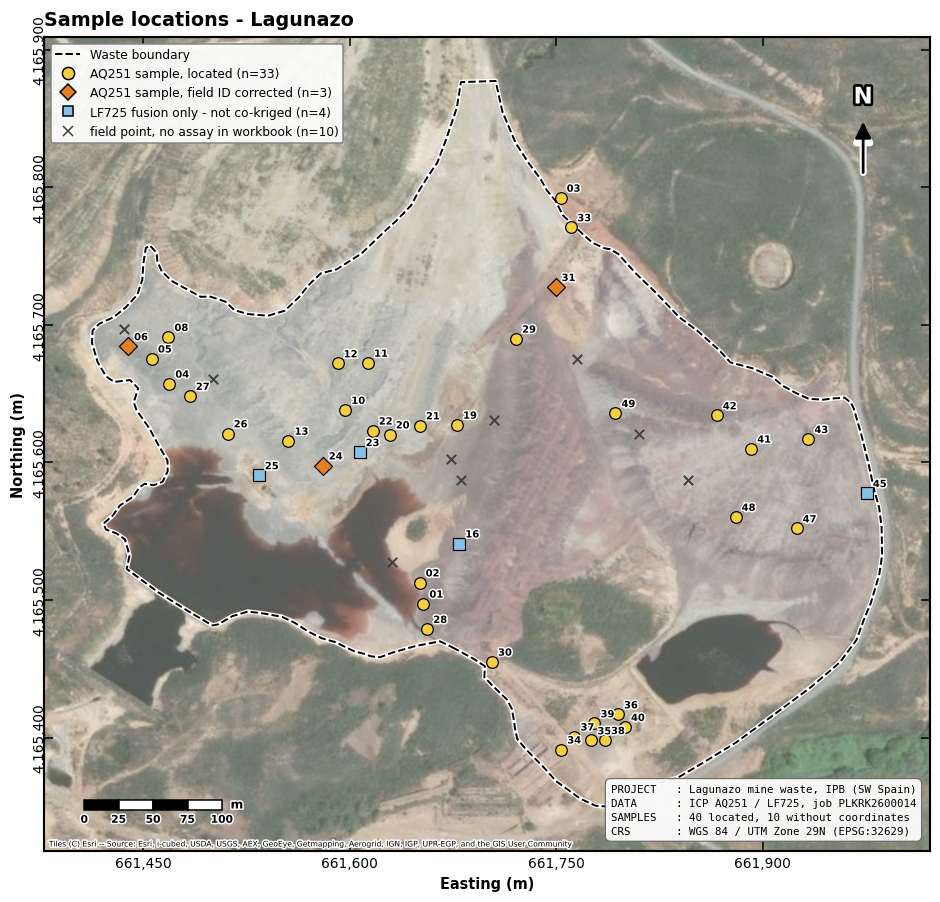

Figure 0 saved -> results_CoK_ICP\ICP_sample_locations_UTM29N.png


In [14]:
fig, ax = plt.subplots(figsize=(11, 9.6))
add_basemap(ax)
loc_only = loc_ok.loc[~loc_ok.index.isin(SAMP["_key"])]
ax.scatter(loc_only["X_utm"], loc_only["Y_utm"], marker="x", s=38, c="0.25", lw=1.3, zorder=11)
_aq = has_aq[has_any].to_numpy()
s_ok = SAMP[LOCATED & _aq & (SAMP["ID_fix"] == "")]
s_fx = SAMP[LOCATED & _aq & (SAMP["ID_fix"] != "")]
s_lf = SAMP[LOCATED & ~_aq]
ax.scatter(s_lf["X_utm"], s_lf["Y_utm"], s=52, c="#85c1e9", marker="s", edgecolors="black", lw=0.8, zorder=12)
ax.scatter(s_ok["X_utm"], s_ok["Y_utm"], s=58, c="#f4d03f", edgecolors="black", lw=0.8, zorder=12)
ax.scatter(s_fx["X_utm"], s_fx["Y_utm"], s=70, c="#e67e22", marker="D", edgecolors="black", lw=0.8, zorder=12)
for _, r in SAMP[LOCATED].iterrows():
    ax.annotate(r["Sample"][-2:], (r["X_utm"], r["Y_utm"]), xytext=(4, 4), textcoords="offset points",
                fontsize=6.5, fontweight="bold", zorder=13,
                path_effects=[mpe.withStroke(linewidth=2, foreground="white")])
add_furniture(ax)
ax.set_title("Sample locations - Lagunazo",
             fontsize=12.5, fontweight="bold", loc="left", pad=8)
ax.legend(handles=[
    Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND),
    Line2D([0], [0], marker="o", color="w", mfc="#f4d03f", mec="black", ms=8,
           label=f"AQ251 sample, located (n={len(s_ok)})"),
    Line2D([0], [0], marker="D", color="w", mfc="#e67e22", mec="black", ms=7,
           label=f"AQ251 sample, field ID corrected (n={len(s_fx)})"),
    Line2D([0], [0], marker="s", color="w", mfc="#85c1e9", mec="black", ms=7,
           label=f"LF725 fusion only - not co-kriged (n={len(s_lf)})"),
    Line2D([0], [0], marker="x", color="0.25", lw=0, ms=7,
           label=f"field point, no assay in workbook (n={len(loc_only)})")],
    loc="upper left", fontsize=8, framealpha=0.92, edgecolor="0.5")
info_box(ax, [
    "PROJECT   : Lagunazo mine waste, IPB (SW Spain)",
    f"DATA      : ICP AQ251 / LF725, job {LAB_INFO.get('Job Number', '')}",
    f"SAMPLES   : {int(LOCATED.sum())} located, {int((~LOCATED).sum())} without coordinates",
    "CRS       : WGS 84 / UTM Zone 29N (EPSG:32629)"])
fig.savefig(outpath("ICP_sample_locations_UTM29N.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print(f"Figure 0 saved -> {outpath('ICP_sample_locations_UTM29N.png')}")

## 7 · Stage 1 - Station Set and Screening

Co-kriging needs the primary and the secondary at known locations. Every AQ251 analyte comes from the same digest of
the same sample, so the located AQ251 samples form **one station set shared by all analytes** (isotopic sampling).
Censored values are substituted as in the IDW / OK notebooks, samples within 5 m are merged into one station, and
every analyte that can serve as a primary or a secondary goes through the ICP OK notebook's admission test.

In [15]:
AQ_LOCATED = LOCATED & has_aq[has_any].to_numpy()

def substituted(col):
    """Located-sample values of one analyte with censoring substitution (<MDL -> BDL_FACTOR x MDL, >UDL -> limit)."""
    f = RAW_FLAG.loc[has_any, col].to_numpy()
    v = RAW_VAL.loc[has_any, col].to_numpy(float)
    return np.where(f == "ok", v, np.where(f == "bdl", BDL_FACTOR * v, np.where(f == "odl", ODL_FACTOR * v, np.nan)))

def flag_counts(col):
    f = RAW_FLAG.loc[has_any, col].to_numpy()[AQ_LOCATED]
    return dict(n=int(np.isin(f, ["ok", "bdl", "odl"]).sum()), n_ok=int((f == "ok").sum()),
                n_bdl=int((f == "bdl").sum()), n_odl=int((f == "odl").sum()))

def unit_of(el):
    return META.loc[el, "unit"]

def is_partial(el):
    return digestion_class(el).startswith("partial")

WIDE = SAMP.loc[:, ["Sample", "X_utm", "Y_utm"]].copy()
for col in AQ_COLS:
    WIDE[col] = substituted(col)
WIDE = WIDE[AQ_LOCATED].reset_index(drop=True)

# eligibility of EVERY AQ251 analyte 
ELIG_ALL = []
for col in AQ_COLS:
    fc = flag_counts(col)
    if fc["n"] >= MIN_N_MAP and fc["n_ok"] / max(fc["n"], 1) >= MIN_QUANT_FRAC:
        ELIG_ALL.append(col)
assert set(a for a in MAPPABLE if a in AQ_COLS) <= set(ELIG_ALL), "CRM eligibility must match Section 5"

ST, ST_REP = collapse_stations(WIDE, "X_utm", "Y_utm", AQ_COLS, tol_m=STATION_TOL_M, id_col="Sample")
COORDS_ALL = ST[["X_utm", "Y_utm"]].to_numpy(float)
print(f"Located AQ251 samples : {ST_REP['n_samples']}  ->  {ST_REP['n_stations']} stations at {STATION_TOL_M:g} m "
      f"({ST_REP['n_stations_with_reps']} with merged replicates)")
_nn = cKDTree(COORDS_ALL).query(COORDS_ALL, k=2)[0][:, 1]
print(f"Station spacing       : nearest neighbour median {np.median(_nn):.1f} m (min {_nn.min():.1f}, max {_nn.max():.1f})")


def resolve(spec, universe):
    if spec is None:
        return list(universe), []
    spec = [spec] if isinstance(spec, str) else list(spec)
    lut = {k.lower(): k for k in META.index}
    chosen, unknown = [], []
    for s in spec:
        k = lut.get(str(s).strip().lower())
        (chosen if k else unknown).append(k if k else str(s))
    return list(dict.fromkeys(chosen)), unknown

CRM_ELIG = [a for a in MAPPABLE if a in AQ_COLS]
PRIMARY_LIST, _unk = resolve(ELEMENTS, CRM_ELIG)
if _unk:
    raise ValueError(f"Unknown analyte(s) in ELEMENTS: {_unk}")
if VAR_NAME not in PRIMARY_LIST:
    PRIMARY_LIST.append(VAR_NAME)
if isinstance(SECONDARY_POOL, str) and SECONDARY_POOL == "crm":
    POOL = list(CRM_ELIG)
elif isinstance(SECONDARY_POOL, str) and SECONDARY_POOL == "all":
    POOL = list(ELIG_ALL)
else:
    POOL, _unk = resolve(SECONDARY_POOL, ELIG_ALL)
    if _unk:
        raise ValueError(f"Unknown analyte(s) in SECONDARY_POOL: {_unk}")

def _max_sep(c):
    return float(np.max(cdist(c, c)))

def _spacing(c):
    return float(np.median(cKDTree(c).query(c, k=2)[0][:, 1]))

SCREEN, ZST = [], {}
for el in list(dict.fromkeys(PRIMARY_LIST + POOL)):
    v_all = ST[el].to_numpy(float)
    ok_ = np.isfinite(v_all)
    v, c = v_all[ok_], COORDS_ALL[ok_]
    fc = flag_counts(el)
    rep = dict(element=el, unit=unit_of(el), role=("primary" if el in PRIMARY_LIST else "")
               + ("+pool" if el in POOL and el in PRIMARY_LIST else "pool" if el in POOL else ""),
               n_stations=int(ok_.sum()), n_below_MDL=fc["n_bdl"], n_above_UDL=fc["n_odl"])
    n = len(v)
    if n < MIN_STATIONS:
        rep["status"] = f"only {n} stations"
    elif n * (n - 1) // 2 < MIN_PAIRS_TOTAL:
        rep["status"] = f"{n * (n - 1) // 2} pairs < {MIN_PAIRS_TOTAL}"
    elif len(np.unique(v)) < MIN_DISTINCT_VALS:
        rep["status"] = f"only {len(np.unique(v))} distinct values"
    elif not np.std(v) > 0:
        rep["status"] = "zero variance"
    else:
        rep["status"] = "ok"
        sd = float(np.std(v, ddof=1))
        imax = int(np.argmax(np.abs(v - v.mean())))
        w, cell, _ = declustering_weights(c, v)
        dmean = float(np.sum(w * v) / w.sum())
        rep.update(mean=float(v.mean()), median=float(np.median(v)), sd=sd, cv=sd / v.mean() if v.mean() else np.nan,
                   skew=float(stats.skew(v)), vmin=float(v.min()), vmax=float(v.max()),
                   top1_variance_share=float(((v[imax] - v.mean()) ** 2 / (n - 1)) / sd ** 2),
                   declustered_mean=dmean, declus_effect_pct=100 * (dmean - v.mean()) / v.mean())
        ZST[el] = v_all
    SCREEN.append(rep)
SCREEN_DF = pd.DataFrame(SCREEN)
show_table(SCREEN_DF, precision=3)
PRIMARIES = [e for e in PRIMARY_LIST if e in ZST]
POOL = [e for e in POOL if e in ZST]
for r in SCREEN:
    if r["status"] != "ok":
        qc("DROP", "screening", f"{r['element']} not admitted: {r['status']}")
print(f"Primaries admitted : {len(PRIMARIES)}  ({', '.join(PRIMARIES)})")
print(f"Secondary pool     : {len(POOL)} analytes, '{SECONDARY_POOL}'  ({', '.join(POOL)})")
if len(ST) < ADVISORY_STATIONS:
    print(f"Only {len(ST)} stations (< {ADVISORY_STATIONS}): every variogram is dominated by sampling noise.")
qc("INFO", "design", f"isotopic sampling: primary and secondary share all {len(ST)} stations, so the secondary is "
                     f"absent at every grid node and co-kriged and kriged maps must nearly coincide (r1).")

Located AQ251 samples : 36  ->  36 stations at 5 m (0 with merged replicates)
Station spacing       : nearest neighbour median 22.1 m (min 9.8, max 73.6)


element,unit,role,n_stations,n_below_MDL,n_above_UDL,status,mean,median,sd,cv,skew,vmin,vmax,top1_variance_share,declustered_mean,declus_effect_pct
Al,%,primary+pool,36,3,0,ok,0.107,0.075,0.125,1.174,2.740,0.005,0.650,0.540,0.092,-14.045
Sb,ppm,primary+pool,36,0,2,ok,532.430,336.775,511.507,0.961,1.797,38.870,2000.000,0.235,485.075,-8.894
As,ppm,primary+pool,36,0,0,ok,1361.525,898.750,1250.401,0.918,2.286,314.700,6377.000,0.460,1386.875,1.862
Ba,ppm,primary+pool,36,0,0,ok,45.608,30.900,46.865,1.028,1.494,1.800,191.200,0.276,44.807,-1.757
Bi,ppm,primary+pool,36,0,0,ok,139.724,80.675,149.135,1.067,2.257,5.340,672.680,0.365,128.190,-8.255
Co,ppm,primary+pool,36,0,0,ok,4.636,3.100,7.146,1.541,3.392,0.200,32.500,0.434,3.732,-19.512
Cu,ppm,primary+pool,36,0,0,ok,511.453,239.950,877.228,1.715,3.094,64.210,4159.290,0.494,413.487,-19.154
Ga,ppm,primary+pool,36,1,0,ok,0.779,0.550,0.762,0.978,2.665,0.050,4.100,0.543,0.759,-2.617
Hf,ppm,primary+pool,36,2,0,ok,0.052,0.050,0.033,0.623,1.057,0.010,0.140,0.208,0.053,1.755
Y,ppm,primary+pool,36,0,0,ok,0.467,0.345,0.493,1.056,3.169,0.100,2.720,0.596,0.396,-15.269


Primaries admitted : 19  (Al, Sb, As, Ba, Bi, Co, Cu, Ga, Hf, Y, La, Ce, Mn, Ni, P, Sr, Ti, W, V)
Secondary pool     : 19 analytes, 'crm'  (Al, Sb, As, Ba, Bi, Co, Cu, Ga, Hf, Y, La, Ce, Mn, Ni, P, Sr, Ti, W, V)


## 8 · Stage 2 - Pair Selection

For each primary the secondary is the pool analyte with the **largest |Spearman ρ|** over the shared stations (r1).
Reported beside it: Pearson (does the coefficient change the choice?), a bootstrap 95 % CI, and a **permutation
p-value of the maximum |ρ| over the whole pool** - the primary is shuffled across stations 999 times and the best
|ρ| against every candidate recorded, so the p-value tests the correlation *as selected*, not as if it had been
chosen in advance. Stations are spatially autocorrelated, so even this p-value is optimistic; it is a screen, not a
proof. A negative correlation is as usable as a positive one (the cross-covariance is negative).

In [16]:
_prng = np.random.default_rng(PAIR_SEED)

def _rank_cols(M):
    R = np.apply_along_axis(stats.rankdata, 0, M)
    R = R - R.mean(axis=0)
    return R / np.sqrt((R ** 2).sum(axis=0))

def boot_ci(x, y, kind="spearman", n_boot=PAIR_N_BOOTSTRAP, alpha=0.05):
    if n_boot <= 0 or len(x) < 6:
        return np.nan, np.nan
    ii = _prng.integers(0, len(x), size=(n_boot, len(x)))
    xs, ys = x[ii], y[ii]
    if kind == "spearman":
        xs = stats.rankdata(xs, axis=1); ys = stats.rankdata(ys, axis=1)
    xs = xs - xs.mean(axis=1, keepdims=True); ys = ys - ys.mean(axis=1, keepdims=True)
    den = np.sqrt((xs ** 2).sum(axis=1) * (ys ** 2).sum(axis=1))
    with np.errstate(invalid="ignore", divide="ignore"):
        r = np.where(den > 0, (xs * ys).sum(axis=1) / den, np.nan)
    r = r[np.isfinite(r)]
    return (float(np.percentile(r, 100 * alpha / 2)), float(np.percentile(r, 100 * (1 - alpha / 2)))) if r.size >= 50 \
        else (np.nan, np.nan)


def rank_partners(Z, primary, pool, full=True):
    """Z: dict analyte -> values on the primary's stations. Returns the candidate table sorted by |selector|,
    plus the permutation p-value of the maximum |rho| (full=True only)."""
    cands = [a for a in pool if a != primary and np.all(np.isfinite(Z[a]))]
    z1 = Z[primary]
    M = np.column_stack([Z[a] for a in cands])
    Rm, r1 = _rank_cols(M), _rank_cols(z1[:, None])[:, 0]
    rho_s = Rm.T @ r1
    Mc = (M - M.mean(axis=0)) / np.sqrt(((M - M.mean(axis=0)) ** 2).sum(axis=0))
    z1c = (z1 - z1.mean()) / np.sqrt(((z1 - z1.mean()) ** 2).sum())
    rho_p = Mc.T @ z1c
    tab = pd.DataFrame({"candidate": cands, "n": len(z1), "spearman": rho_s, "pearson": rho_p})
    tab["selector"] = tab[PAIR_SELECT_ON]
    tab = tab.reindex(tab["selector"].abs().sort_values(ascending=False).index).reset_index(drop=True)
    p_max = np.nan
    if full:
        base = Rm if PAIR_SELECT_ON == "spearman" else Mc
        rv = r1 if PAIR_SELECT_ON == "spearman" else z1c
        obs = np.abs(tab["selector"]).max()
        perm = np.array([np.abs(base.T @ rv[_prng.permutation(len(rv))]).max() for _ in range(PAIR_N_PERM)])
        p_max = float((1 + np.sum(perm >= obs - 1e-12)) / (1 + PAIR_N_PERM))
        tab["ci_low"], tab["ci_high"] = zip(*[boot_ci(z1, Z[a], PAIR_SELECT_ON) for a in tab["candidate"]])
        tab.attrs["perm_q95"] = float(np.percentile(perm, 95))
    tab.attrs["p_max"] = p_max
    return tab


def choose_secondary(tab, primary):
    forced = SECONDARY_OVERRIDE.get(primary)
    if forced:
        if forced not in set(tab["candidate"]):
            raise ValueError(f"SECONDARY_OVERRIDE[{primary}] = {forced} is not an admitted pool analyte")
        return forced
    return tab.loc[0, "candidate"]


PAIR_TABLES, PAIR_ROWS = {}, []
for el in PRIMARIES:
    okst = np.isfinite(ZST[el])
    Z = {a: ZST[a][okst] for a in set(POOL) | {el}}
    tab = rank_partners(Z, el, POOL, full=True)
    sec = choose_secondary(tab, el)
    r = tab.set_index("candidate").loc[sec]
    by_other = tab.loc[tab[("pearson" if PAIR_SELECT_ON == "spearman" else "spearman")].abs().idxmax(), "candidate"]
    PAIR_TABLES[el] = tab
    PAIR_ROWS.append(dict(primary=el, secondary=sec, n=int(r["n"]), spearman=r["spearman"], pearson=r["pearson"],
                          ci95_low=r["ci_low"], ci95_high=r["ci_high"], p_max_over_pool=tab.attrs["p_max"],
                          null_q95_max_abs_rho=tab.attrs["perm_q95"], n_candidates=len(tab),
                          runner_up=tab.loc[1, "candidate"] if len(tab) > 1 else "",
                          runner_up_rho=tab.loc[1, "selector"] if len(tab) > 1 else np.nan,
                          other_coefficient_choice=by_other, forced=el in SECONDARY_OVERRIDE,
                          weak=abs(r["selector"]) < WEAK_PAIR_ABS_RHO))
    if by_other != sec and el not in SECONDARY_OVERRIDE:
        qc("WARN", "pair", f"{el}: {PAIR_SELECT_ON} selects {sec} but the other coefficient would select {by_other}; "
                           f"the choice is outlier-sensitive.")
    if tab.attrs["p_max"] >= 0.05:
        qc("WARN", "pair", f"{el}-{sec}: |rho| {abs(r['selector']):.2f} is not distinguishable from the best of "
                           f"{len(tab)} random partners (permutation p = {tab.attrs['p_max']:.3f}).")
PAIRS_DF = pd.DataFrame(PAIR_ROWS)
show_table(PAIRS_DF, precision=3)
print("Selected pairs (primary <- secondary, Spearman):")
for r in PAIR_ROWS:
    print(f"  {r['primary']:3s} <- {r['secondary']:3s}  rho_s {r['spearman']:+.2f} [{r['ci95_low']:+.2f}, {r['ci95_high']:+.2f}]"
          f"  Pearson {r['pearson']:+.2f}  p(max over {r['n_candidates']}) = {r['p_max_over_pool']:.3f}"
          + ("   WEAK" if r["weak"] else "") + ("   (forced)" if r["forced"] else ""))

primary,secondary,n,spearman,pearson,ci95_low,ci95_high,p_max_over_pool,null_q95_max_abs_rho,n_candidates,runner_up,runner_up_rho,other_coefficient_choice,forced,weak
Al,Ga,36,0.871,0.532,0.731,0.935,0.001,0.479,18,V,0.784,Y,False,False
Sb,Bi,36,0.902,0.925,0.764,0.970,0.001,0.478,18,Ni,-0.690,Bi,False,False
As,P,36,0.495,0.743,0.175,0.748,0.030,0.469,18,Ba,0.361,P,False,True
Ba,V,36,0.544,0.378,0.267,0.741,0.017,0.477,18,Ga,0.515,Ga,False,False
Bi,Sb,36,0.902,0.925,0.757,0.966,0.001,0.473,18,Cu,-0.776,Sb,False,False
Co,Cu,36,0.865,0.948,0.704,0.940,0.001,0.482,18,Ni,0.859,Ni,False,False
Cu,Co,36,0.865,0.948,0.703,0.940,0.001,0.469,18,Ni,0.863,Co,False,False
Ga,V,36,0.898,0.852,0.788,0.954,0.001,0.476,18,Al,0.871,P,False,False
Hf,Sb,36,0.585,0.415,0.269,0.808,0.004,0.471,18,Bi,0.521,P,False,False
Y,Al,36,0.644,0.905,0.328,0.842,0.002,0.477,18,Mn,0.522,Mn,False,False


Selected pairs (primary <- secondary, Spearman):
  Al  <- Ga   rho_s +0.87 [+0.73, +0.93]  Pearson +0.53  p(max over 18) = 0.001
  Sb  <- Bi   rho_s +0.90 [+0.76, +0.97]  Pearson +0.93  p(max over 18) = 0.001
  As  <- P    rho_s +0.50 [+0.17, +0.75]  Pearson +0.74  p(max over 18) = 0.030   WEAK
  Ba  <- V    rho_s +0.54 [+0.27, +0.74]  Pearson +0.38  p(max over 18) = 0.017
  Bi  <- Sb   rho_s +0.90 [+0.76, +0.97]  Pearson +0.93  p(max over 18) = 0.001
  Co  <- Cu   rho_s +0.86 [+0.70, +0.94]  Pearson +0.95  p(max over 18) = 0.001
  Cu  <- Co   rho_s +0.86 [+0.70, +0.94]  Pearson +0.95  p(max over 18) = 0.001
  Ga  <- V    rho_s +0.90 [+0.79, +0.95]  Pearson +0.85  p(max over 18) = 0.001
  Hf  <- Sb   rho_s +0.59 [+0.27, +0.81]  Pearson +0.42  p(max over 18) = 0.004
  Y   <- Al   rho_s +0.64 [+0.33, +0.84]  Pearson +0.90  p(max over 18) = 0.002
  La  <- Ce   rho_s +0.97 [+0.93, +0.99]  Pearson +0.99  p(max over 18) = 0.001
  Ce  <- La   rho_s +0.97 [+0.93, +0.99]  Pearson +0.99  p(max o

## 9 · Stage 3 - LMC, Co-kriging Cross-Validation and Transform Selection

For each primary and each transform: both variables are transformed (log offsets and declustered normal-score tables
fitted per variable), the three experimental variograms computed on the same equal-count lags, the LMC fitted, and
four leave-one-out predictors computed **with the LMC fixed** (standard practice; Section 9b removes that optimism):

| Predictor | At the held-out station | Describes |
|---|---|---|
| **kriging** | primary removed, secondary not used | ordinary kriging with γ₁₁ of the same LMC — the paired benchmark |
| **co-kriging MAPPING** | primary **and** secondary removed | **every grid node** — the only row that describes the maps |
| co-kriging COLLOCATED | primary removed, secondary **kept** | a diagnostic: *if the secondary were known here* |
| regression on secondary | OLS of y₁ on y₂ (fit space), residual-variance back-transform | what the collocated figure should be compared with |

The transform with the lowest MAPPING RMSE in grade units is adopted if it beats `none` by at least 2 %.

**Two situations in which the secondary cannot help, whatever its correlation.** (1) *Autokrigeability*: when the
fitted cross-covariance is proportional to the primary's own covariance (`b⁰₁₂/b⁰₁₁ = b¹₁₂/b¹₁₁`, e.g. a single
structure, or a pure-nugget primary with a pure-nugget cross structure), isotopic co-kriging is **identical** to
kriging. (2) A cross sill **clipped to the PSD limit** (|ρ_structure| = 0.999) asserts a near-perfect structural
correlation that the cross-variogram did not show; co-kriging then uses the secondary to "filter" the primary's
nugget, and any variance reduction it reports is model-driven. Both are flagged per primary.

In [17]:
PREDICTORS = ("kriging", "mapping", "collocated", "regression")

def back_pred(tf, est, var, mu):
    return est if tf.kind == "none" else tf.back(est, var=var, mu=mu)

def loocv_ck(model, coords, y1, y2, tf1, z1, predictors=PREDICTORS, K=None):
    """Leave-one-out predictions of the primary. K = None: all other stations (global, adopted); K = int: the K
    nearest other stations (neighbourhood sensitivity; kriging and mapping only)."""
    n = len(y1)
    idx = np.arange(n)
    out = {p: dict(est=np.full(n, np.nan), var=np.full(n, np.nan), mu=np.full(n, np.nan)) for p in predictors}
    D = cdist(coords, coords)
    for k in range(n):
        keep = idx[idx != k]
        nb = keep if (K is None or K >= len(keep)) else keep[np.argsort(D[k, keep], kind="mergesort")[:K]]
        T = coords[k:k + 1]
        for p in predictors:
            if p == "kriging":
                r = ck_solve(model, coords[nb], y1[nb], _EMPTY, np.empty(0), T)
            elif p == "mapping":
                r = ck_solve(model, coords[nb], y1[nb], coords[nb], y2[nb], T)
            elif p == "collocated":
                nb2 = np.append(keep, k)
                r = ck_solve(model, coords[keep], y1[keep], coords[nb2], y2[nb2], T)
            else:                                            # regression on the secondary, fit space
                b, a0 = np.polyfit(y2[keep], y1[keep], 1)
                s2 = float(np.sum((y1[keep] - (a0 + b * y2[keep])) ** 2) / max(len(keep) - 2, 1))
                r = dict(est=np.array([a0 + b * y2[k]]), var=np.array([s2]), mu=np.array([0.0]))
            out[p]["est"][k], out[p]["var"][k], out[p]["mu"][k] = r["est"][0], r["var"][0], r["mu"][0]
    res = {}
    for p in predictors:
        e, v, mu = out[p]["est"], np.maximum(out[p]["var"], 0.0), out[p]["mu"]
        pred = back_pred(tf1, e, v, mu)
        n_clip = int(np.sum(pred < 0))
        pred = np.clip(pred, 0.0, None)
        m = metrics(z1, pred)
        zerr = (e - y1) / np.sqrt(np.maximum(v, 1e-300))
        has_var = p != "regression"
        res[p] = dict(est=e, var=v, mu=mu, pred=pred, m=m, rmse=m["RMSE"], r2=m["R2_pred"], n_clip=n_clip,
                      rmse_fit=float(np.sqrt(np.mean((e - y1) ** 2))),
                      rmsse=float(np.sqrt(np.mean(zerr ** 2))) if has_var else np.nan,
                      cov95=float(100 * np.mean(np.abs(zerr) <= 1.959964)) if has_var else np.nan,
                      zerr=zerr if has_var else None)
    return res


def fit_transform_pair(coords, z1, z2, w1, w2, transform, full=True):
    tf1 = Transform(transform).fit(z1, w=w1)
    tf2 = Transform(transform).fit(z2, w=w2)
    y1, y2 = tf1.forward(z1), tf2.forward(z2)
    cutoff = CUTOFF_FACTOR * _max_sep(coords)
    vgm = lmc_variograms(coords, y1, y2, cutoff)
    out = dict(transform=transform, tf1=tf1, tf2=tf2, y1=y1, y2=y2, vgm=vgm, cutoff=cutoff,
               svar={"11": float(np.var(y1, ddof=1)), "22": float(np.var(y2, ddof=1)),
                     "12": float(np.cov(y1, y2, ddof=1)[0, 1])})
    if len(vgm) < 3:
        out["status"] = f"only {len(vgm)} lag(s) with >= {MIN_PAIRS_LAG} pairs"
        return out
    fit = fit_lmc(vgm, cutoff)
    model = make_model(fit)
    if not (model["sill1"] > 0 and model["sill2"] > 0):
        out["status"] = "zero fitted sill"
        return out
    cv = loocv_ck(model, coords, y1, y2, tf1, z1, predictors=PREDICTORS if full else ("mapping",))
    out.update(status="ok", fit=fit, model=model, cv=cv, rmse_ppm=cv["mapping"]["rmse"], r2_ppm=cv["mapping"]["r2"])
    return out


def select_transform(cands):
    """Lowest co-kriging MAPPING LOOCV RMSE in grade units; a transform must beat 'none' by TRANSFORM_MIN_GAIN_PCT."""
    ok_ = {t: a for t, a in cands.items() if a["status"] == "ok"}
    if not ok_:
        return None
    pick = min(ok_.values(), key=lambda a: a["rmse_ppm"])
    g = np.nan
    if "none" in ok_ and pick["transform"] != "none":
        g = 100.0 * (ok_["none"]["rmse_ppm"] - pick["rmse_ppm"]) / max(ok_["none"]["rmse_ppm"], 1e-12)
        if g < TRANSFORM_MIN_GAIN_PCT:
            pick = ok_["none"]
    pick["transform_gain_pct"] = g
    return pick


def run_procedure(coords, Z, primary, pool, full=True, table=None):
    """The complete selection for one primary: secondary, declustering, transforms, LMC, transform choice.
    full=False (nested folds): no bootstrap / permutation, and only the MAPPING predictor is cross-validated."""
    tab = table if table is not None else rank_partners(Z, primary, pool, full=False)
    sec = choose_secondary(tab, primary)
    z1, z2 = Z[primary], Z[sec]
    w1 = declustering_weights(coords, z1)[0]
    w2 = declustering_weights(coords, z2)[0]
    cands = {t: fit_transform_pair(coords, z1, z2, w1, w2, t, full=full) for t in TRANSFORM_CANDIDATES}
    return dict(primary=primary, secondary=sec, table=tab, z1=z1, z2=z2, w1=w1, w2=w2, coords=coords,
                cands=cands, pick=select_transform(cands))


RES, TRIALS = {}, []
_t0 = time.time()
for el in PRIMARIES:
    okst = np.isfinite(ZST[el])
    coords = COORDS_ALL[okst]
    Z = {a: ZST[a][okst] for a in set(POOL) | {el}}
    P = run_procedure(coords, Z, el, POOL, full=True, table=PAIR_TABLES[el])
    RES[el] = P
    for t, a in P["cands"].items():
        if a["status"] != "ok":
            TRIALS.append(dict(primary=el, secondary=P["secondary"], transform=t, status=a["status"]))
            continue
        f, cv = a["fit"], a["cv"]
        cond = ck_solve(a["model"], coords, a["y1"], coords, a["y2"], coords[:1], cond=True)["cond"]
        TRIALS.append(dict(primary=el, secondary=P["secondary"], transform=t, status="ok", lags=len(a["vgm"]),
                           range_m=f["range_m"], on_bound=f["on_bound"] or "-",
                           ns11=f["coef"]["11"][0] / a["model"]["sill1"],
                           fit_r2_11=f["fit_r2"]["11"], fit_r2_22=f["fit_r2"]["22"], fit_r2_12=f["fit_r2"]["12"],
                           psd_clipped=", ".join(c[0] for c in f["psd_clipped"]) or "-", cond=cond,
                           rmse_ck=cv["mapping"]["rmse"], r2_ck=cv["mapping"]["r2"],
                           rmse_ok=cv["kriging"]["rmse"], r2_ok=cv["kriging"]["r2"],
                           r2_collocated=cv["collocated"]["r2"], r2_regression=cv["regression"]["r2"],
                           rmsse_ck=cv["mapping"]["rmsse"], cov95_ck=cv["mapping"]["cov95"],
                           adopted=(P["pick"] is a)))
    pk = P["pick"]
    if pk is None:
        print(f"  {el:3s} <- {P['secondary']:3s}: no transform produced a usable LMC")
        continue
    cv = pk["cv"]
    print(f"  {el:3s} <- {P['secondary']:3s} {pk['transform']:6s} a={pk['fit']['range_m']:6.1f} m"
          f"{' [on bound]' if pk['fit']['on_bound'] else '           '}"
          f"  R2 OK {cv['kriging']['r2']:+.3f}  CK map {cv['mapping']['r2']:+.3f}  "
          f"colloc {cv['collocated']['r2']:+.3f}  regr {cv['regression']['r2']:+.3f}  RMSSE {cv['mapping']['rmsse']:.2f}")
TRIALS_DF = pd.DataFrame(TRIALS)
print(f"\n{len(TRIALS)} primary x transform analyses in {time.time() - _t0:.1f} s")
show_table(TRIALS_DF, precision=3)
FAILED = {el: "; ".join(a["status"] for a in RES[el]["cands"].values()) for el in PRIMARIES if RES[el]["pick"] is None}
FITTED = [el for el in PRIMARIES if RES[el]["pick"] is not None]
if FAILED:
    print("No usable LMC:", FAILED)

  Al  <- Ga  nscore a= 377.6 m [on bound]  R2 OK +0.016  CK map -0.007  colloc +0.338  regr +0.065  RMSSE 1.08
  Sb  <- Bi  log    a=  48.8 m             R2 OK +0.341  CK map +0.341  colloc +0.880  regr +0.852  RMSSE 1.14
  As  <- P   nscore a= 377.6 m [on bound]  R2 OK +0.122  CK map +0.264  colloc +0.362  regr +0.249  RMSSE 0.96
  Ba  <- V   log    a= 244.5 m             R2 OK +0.214  CK map +0.407  colloc -0.338  regr -2.122  RMSSE 1.03
  Bi  <- Sb  none   a=  44.1 m             R2 OK +0.415  CK map +0.421  colloc +0.905  regr +0.766  RMSSE 0.99
  Co  <- Cu  log    a= 377.6 m [on bound]  R2 OK +0.043  CK map +0.037  colloc +0.802  regr +0.794  RMSSE 1.07
  Cu  <- Co  nscore a= 377.6 m [on bound]  R2 OK +0.085  CK map +0.090  colloc +0.754  regr +0.763  RMSSE 1.05
  Ga  <- V   none   a= 377.6 m [on bound]  R2 OK +0.345  CK map +0.313  colloc +0.735  regr -0.555  RMSSE 1.42
  Hf  <- Sb  none   a=  45.5 m             R2 OK +0.171  CK map +0.239  colloc +0.256  regr +0.076  RMSSE 1.01
 

primary,secondary,transform,status,lags,range_m,on_bound,ns11,fit_r2_11,fit_r2_22,fit_r2_12,psd_clipped,cond,rmse_ck,r2_ck,rmse_ok,r2_ok,r2_collocated,r2_regression,rmsse_ck,cov95_ck,adopted
Al,Ga,none,ok,11,377.575,upper,0.960,0.001,0.428,0.116,spherical,551.225,0.126,-0.051,0.124,-0.016,0.473,-0.174,1.044,94.444,False
Al,Ga,log,ok,11,377.575,upper,0.537,0.310,0.661,0.573,-,155.886,0.125,-0.021,0.124,-0.012,0.010,-1.020,1.050,91.667,False
Al,Ga,nscore,ok,11,377.575,upper,0.552,0.287,0.727,0.552,-,178.160,0.124,-0.007,0.122,0.016,0.338,0.065,1.085,88.889,True
Sb,Bi,none,ok,11,44.051,-,0.348,0.070,0.129,0.018,nugget,197.737,433.167,0.262,433.936,0.260,0.873,0.826,1.008,91.667,False
Sb,Bi,log,ok,11,48.829,-,0.000,0.165,0.183,0.154,-,488.446,409.522,0.341,409.522,0.341,0.880,0.852,1.136,91.667,True
Sb,Bi,nscore,ok,11,51.976,-,0.000,0.220,0.362,0.132,spherical,44892.202,430.128,0.273,430.128,0.273,0.890,0.834,1.198,88.889,False
As,P,none,ok,11,377.575,upper,0.189,0.478,0.327,0.267,-,963.896,1229.410,0.006,1225.482,0.012,0.476,0.516,1.390,86.111,False
As,P,log,ok,11,377.575,upper,0.404,0.505,0.594,0.593,-,138.366,1135.770,0.151,1135.250,0.152,0.358,0.430,0.996,97.222,False
As,P,nscore,ok,11,377.575,upper,0.588,0.193,0.568,0.620,spherical,59.065,1057.493,0.264,1155.157,0.122,0.362,0.249,0.958,97.222,True
Ba,V,none,ok,11,266.796,-,0.180,0.552,0.257,-0.074,-,442.859,37.577,0.339,41.321,0.200,-0.400,-0.687,1.153,91.667,False


## 9b · Nested Cross-Validation

Stage 3's leave-one-out errors are computed with an LMC fitted to every station, the transform chosen on those same
errors, and the secondary chosen on correlations that include the held-out station. Here the **entire procedure** -
pair selection, declustering, transforms, the three variograms, the LMC fit and the transform choice - is repeated
without each station, and that station is then predicted by co-kriging (MAPPING) **and** by kriging with the fold's
own LMC. The nested co-kriging R² decides surface vs posted values; the nested kriging R² measures what the
covariate actually adds.

In [18]:
def nested_loocv(el):
    P = RES[el]
    coords, n = P["coords"], len(P["z1"])
    okst = np.isfinite(ZST[el])
    pred_ck, pred_ok, picks = np.full(n, np.nan), np.full(n, np.nan), []
    for i in range(n):
        keep = np.arange(n) != i
        Zf = {a: ZST[a][okst][keep] for a in set(POOL) | {el}}
        F = run_procedure(coords[keep], Zf, el, POOL, full=False)
        pk = F["pick"]
        if pk is None:
            picks.append(("-", "-"))
            continue
        T = coords[i:i + 1]
        rc = ck_solve(pk["model"], coords[keep], pk["y1"], coords[keep], pk["y2"], T)
        rk = ck_solve(pk["model"], coords[keep], pk["y1"], _EMPTY, np.empty(0), T)
        pred_ck[i] = max(float(back_pred(pk["tf1"], rc["est"], np.maximum(rc["var"], 0), rc["mu"])[0]), 0.0)
        pred_ok[i] = max(float(back_pred(pk["tf1"], rk["est"], np.maximum(rk["var"], 0), rk["mu"])[0]), 0.0)
        picks.append((F["secondary"], pk["transform"]))
    return pred_ck, pred_ok, picks

NESTED = {}
_t0 = time.time()
for el in FITTED:
    pck, pok, picks = nested_loocv(el)
    z1 = RES[el]["z1"]
    mck, mok = metrics(z1, pck), metrics(z1, pok)
    ci, pbelow = boot_r2(z1, pck)
    sel = (RES[el]["secondary"], RES[el]["pick"]["transform"])
    NESTED[el] = dict(pred_ck=pck, pred_ok=pok, m_ck=mck, m_ok=mok, picks=picks, r2_ck=mck["R2_pred"],
                      r2_ok=mok["R2_pred"], rmse_ck=mck["RMSE"], rmse_ok=mok["RMSE"], ci90=ci, p_below=pbelow,
                      gain_pct=100 * (mok["RMSE"] - mck["RMSE"]) / max(mok["RMSE"], 1e-12),
                      same_secondary_pct=100 * np.mean([p[0] == sel[0] for p in picks]),
                      same_transform_pct=100 * np.mean([p[1] == sel[1] for p in picks]))
    N = NESTED[el]
    print(f"  {el:3s} <- {sel[0]:3s}  R2 CK: LOOCV {RES[el]['pick']['r2_ppm']:+.3f} -> nested {N['r2_ck']:+.3f} "
          f"[90 % CI {ci[0]:+.2f}, {ci[1]:+.2f}]  | nested OK {N['r2_ok']:+.3f}  CK vs OK {N['gain_pct']:+5.1f} % RMSE"
          f"  | secondary kept in {N['same_secondary_pct']:3.0f} %, transform in {N['same_transform_pct']:3.0f} % of folds")
print(f"\nNested cross-validation: {len(FITTED)} primaries x {len(COORDS_ALL)} folds in {time.time() - _t0:.0f} s")

  Al  <- Ga   R2 CK: LOOCV -0.007 -> nested -0.064 [90 % CI -0.50, +0.01]  | nested OK -0.024  CK vs OK  -1.9 % RMSE  | secondary kept in 100 %, transform in  53 % of folds
  Sb  <- Bi   R2 CK: LOOCV +0.341 -> nested +0.278 [90 % CI -0.14, +0.48]  | nested OK +0.319  CK vs OK  -3.0 % RMSE  | secondary kept in 100 %, transform in  50 % of folds
  As  <- P    R2 CK: LOOCV +0.264 -> nested +0.186 [90 % CI -0.40, +0.32]  | nested OK +0.085  CK vs OK  +5.7 % RMSE  | secondary kept in 100 %, transform in  97 % of folds
  Ba  <- V    R2 CK: LOOCV +0.407 -> nested +0.330 [90 % CI -0.13, +0.59]  | nested OK +0.141  CK vs OK +11.7 % RMSE  | secondary kept in  97 %, transform in  78 % of folds
  Bi  <- Sb   R2 CK: LOOCV +0.421 -> nested +0.484 [90 % CI -0.02, +0.68]  | nested OK +0.504  CK vs OK  -1.9 % RMSE  | secondary kept in 100 %, transform in  14 % of folds
  Co  <- Cu   R2 CK: LOOCV +0.037 -> nested +0.000 [90 % CI -1.15, +0.02]  | nested OK +0.011  CK vs OK  -0.6 % RMSE  | secondary kept 

## 10 · Stage 4 - Co-kriging and Kriging the Grid

The 3 m grid of the ICP IDW / OK notebooks over the domain's bounding box, masked to the domain. Each primary is
co-kriged (global neighbourhood) and, for the paired comparison, kriged with γ₁₁ of the same LMC. Estimates are
back-transformed to grade units; the uncertainty is kept as the fit-space standard error **and** as an approximate
prediction SD in grade units; the covariate's contribution is `100·(1 − SE_CK / SE_OK)` %.

In [19]:
xi = np.arange(xmin_u, xmax_u + GRID_DENSITY_M, GRID_DENSITY_M)
yi = np.arange(ymin_u, ymax_u + GRID_DENSITY_M, GRID_DENSITY_M)
XG, YG = np.meshgrid(xi, yi)
NROW, NCOL = XG.shape
GRID_PTS = np.column_stack([XG.ravel(), YG.ravel()])
INSIDE = inside_domain(XG.ravel(), YG.ravel())
GIN = GRID_PTS[INSIDE]
print(f"Grid: {NCOL} x {NROW} = {NROW * NCOL:,} nodes at {GRID_DENSITY_M:g} m (square cells); "
      f"{int(INSIDE.sum()):,} inside the {BND_LABEL}")

def to_grid(vals_inside, fill=np.nan):
    g = np.full(NROW * NCOL, fill, dtype=float)
    g[INSIDE] = vals_inside
    return g.reshape(NROW, NCOL)

GRIDS = {}
_t0 = time.time()
for el in FITTED:
    P, pk = RES[el], RES[el]["pick"]
    m, tf, coords = pk["model"], pk["tf1"], P["coords"]
    rc = ck_solve(m, coords, pk["y1"], coords, pk["y2"], GIN, cond=True)
    rk = ck_solve(m, coords, pk["y1"], _EMPTY, np.empty(0), GIN, cond=True)
    tol = 1e-9 * max(m["sill1"], 1e-300)
    n_neg = (int(np.sum(rc["var"] < -tol)), int(np.sum(rk["var"] < -tol)))
    if any(n_neg):
        qc("WARN", "solver", f"{el}: negative variance at {n_neg[0]} co-kriging / {n_neg[1]} kriging node(s) (clipped).")
    vck, vok = np.maximum(rc["var"], 0.0), np.maximum(rk["var"], 0.0)
    zck, zok = back_pred(tf, rc["est"], vck, rc["mu"]), back_pred(tf, rk["est"], vok, rk["mu"])
    n_clip = (int(np.sum(zck < 0)), int(np.sum(zok < 0)))
    zck, zok = np.clip(zck, 0, None), np.clip(zok, 0, None)
    se_ck, se_ok = np.sqrt(vck), np.sqrt(vok)
    with np.errstate(invalid="ignore", divide="ignore"):
        sered = np.where(se_ok > 0, 100 * (1 - se_ck / se_ok), np.nan)
    ex_d = float(cKDTree(coords).query(coords, k=2)[0][:, 1].max())
    D = cKDTree(coords).query(GIN, k=1)[0]
    GRIDS[el] = dict(CK=to_grid(zck), OK=to_grid(zok), SD_CK=to_grid(tf.back_sd(rc["est"], vck, zck)),
                     SD_OK=to_grid(tf.back_sd(rk["est"], vok, zok)), SE_CK=to_grid(se_ck), SE_OK=to_grid(se_ok),
                     SERED=to_grid(sered), DIFF=to_grid(zck - zok), MU_CK=to_grid(rc["mu"]), D=to_grid(D),
                     EX=to_grid((D > ex_d).astype(float)), ex_d=ex_d, n_neg=n_neg, n_clip=n_clip,
                     cond_ck=rc["cond"], cond_ok=rk["cond"])
    if n_clip[0] or n_clip[1]:
        qc("INFO", "solver", f"{el}: {n_clip[0]} co-kriged / {n_clip[1]} kriged node(s) below zero clipped to 0.")
    if rc["cond"] > COND_WARN:
        qc("WARN", "solver", f"{el}: co-kriging condition number {rc['cond']:.1e} > {COND_WARN:.0e}.")
    u = unit_of(el)
    print(f"  {el:3s} CK {np.nanmin(zck):>9,.4g} - {np.nanmax(zck):>9,.4g} {u:3s} | OK {np.nanmin(zok):>9,.4g} - "
          f"{np.nanmax(zok):>9,.4g} | mean |CK-OK| {np.nanmean(np.abs(zck - zok)):,.3g} {u} | SE reduction mean "
          f"{np.nanmean(sered):4.1f} %, max {np.nanmax(sered):4.1f} % | cond {rc['cond']:.1e}")
print(f"\n{len(GRIDS)} primaries co-kriged and kriged in {time.time() - _t0:.1f} s")

Grid: 193 x 177 = 34,161 nodes at 3 m (square cells); 18,041 inside the Waste area polygon
  Al  CK   0.03426 -    0.3103 %   | OK   0.03921 -    0.1968 | mean |CK-OK| 0.0277 % | SE reduction mean  2.0 %, max  4.4 % | cond 1.8e+02
  Sb  CK     46.26 -     2,096 ppm | OK     46.26 -     2,096 | mean |CK-OK| 1.74e-08 ppm | SE reduction mean -0.0 %, max  0.0 % | cond 4.9e+02
  As  CK     640.5 -     4,189 ppm | OK     832.4 -     3,194 | mean |CK-OK| 222 ppm | SE reduction mean  3.0 %, max  6.5 % | cond 5.9e+01
  Ba  CK     13.14 -       262 ppm | OK     12.62 -     148.4 | mean |CK-OK| 11.2 ppm | SE reduction mean  2.4 %, max  5.9 % | cond 6.0e+01
  Bi  CK     43.08 -     566.8 ppm | OK     37.38 -     556.8 | mean |CK-OK| 1.87 ppm | SE reduction mean  0.2 %, max  3.1 % | cond 2.0e+02
  Co  CK     2.418 -     5.613 ppm | OK     2.443 -     5.831 | mean |CK-OK| 0.0887 ppm | SE reduction mean  0.0 %, max  0.1 % | cond 1.0e+02
  Cu  CK     192.8 -     1,059 ppm | OK     151.8 -     1,187 | 

## 11 · Stage 5 - Cross-Element Summary

**The nested co-kriging `R2` (grade units) decides whether a map means anything**; the Stage-3 LOOCV R² is shown beside
it to expose the optimism. Benchmarks by leave-one-out: the **leave-one-out mean** and a fixed **IDW** (p = 2, 16
nearest). The covariate's contribution is read from the nested RMSE of co-kriging against kriging with the same
fold-wise LMC. The collocated R² is printed next to the regression R² because the two coincide when the collocated
number is merely the pair's correlation (r1 fix K5).

In [20]:
def loo_mean(v):
    v = np.asarray(v, float)
    return (v.sum() - v) / (len(v) - 1)

def loo_idw(coords, v, p=2.0, k=16):
    n = len(v); k = min(k, n - 1)
    d, ix = cKDTree(coords).query(coords, k=k + 1)
    d, ix = d[:, 1:], ix[:, 1:]
    w = 1.0 / np.maximum(d, 1e-9) ** p
    return np.sum(w * v[ix], axis=1) / w.sum(axis=1)

rows = []
for el in FITTED:
    P, pk, N, g = RES[el], RES[el]["pick"], NESTED[el], GRIDS[el]
    f, cv, z1 = pk["fit"], pk["cv"], P["z1"]
    sc = next(r for r in SCREEN if r["element"] == el)
    pr = PAIRS_DF.set_index("primary").loc[el]
    m_idw = metrics(z1, loo_idw(P["coords"], z1))
    rm_mean = metrics(z1, loo_mean(z1))["RMSE"]
    if N["r2_ck"] >= MIN_R2_SURFACE:
        verdict = "surface - co-kriged"
        if N["p_below"] >= MARGINAL_P:
            verdict += f"; marginal (bootstrap P(R2 < {MIN_R2_SURFACE:g}) = {100 * N['p_below']:.0f} %)"
        if N["rmse_ck"] > m_idw["RMSE"]:
            verdict += "; fixed IDW more accurate"
    else:
        verdict = "posted values (no skill in nested CV)"
    if abs(N["gain_pct"]) < CK_GAIN_MIN_PCT:
        verdict += "; covariate adds nothing (CK = OK within 2 %)"
    elif N["gain_pct"] < 0:
        verdict += "; co-kriging WORSE than kriging"
    ak = autokrigeable(f["coef"])
    if ak:
        verdict += "; autokrigeable LMC (CK identical to OK)"
    r16 = loocv_ck(pk["model"], P["coords"], pk["y1"], pk["y2"], pk["tf1"], z1, predictors=("mapping",), K=16)["mapping"]
    loc_gain = 100 * (cv["mapping"]["rmse"] - r16["rmse"]) / max(cv["mapping"]["rmse"], 1e-12)
    if loc_gain > 5:
        qc("INFO", "neighbourhood", f"{el}: a 16-station neighbourhood predicts {loc_gain:.1f} % better (LOOCV RMSE) than "
                                    f"the global one - the mean may drift across the heap; global (r1) retained.")
    if f["psd_clipped"]:
        qc("WARN", "lmc", f"{el} <- {P['secondary']}: cross sill clipped to the PSD limit ({', '.join(c[0] for c in f['psd_clipped'])}); "
                          f"the model asserts |rho| = 0.999 in that structure and any variance reduction is model-driven.")
    if f["cross_zeroed"]:
        qc("INFO", "lmc", f"{el} <- {P['secondary']}: cross {', '.join(c[0] for c in f['cross_zeroed'])} sill set to 0 "
                          f"because a direct structure is absent (fitted {', '.join(f'{c[1]:.3g}' for c in f['cross_zeroed'])}).")
    if np.nanmax(g["CK"]) > 1.10 * z1.max():
        qc("INFO", "surface", f"{el}: co-kriged maximum {np.nanmax(g['CK']):,.4g} exceeds the data maximum {z1.max():,.4g} "
                              f"{unit_of(el)} by {100 * (np.nanmax(g['CK']) / z1.max() - 1):.0f} % (back-transform / secondary weights).")
    rows.append({
        "Element": el, "Unit": unit_of(el), "Digestion": digestion_class(el), "n": len(z1),
        "n above UDL": sc["n_above_UDL"], "Secondary": P["secondary"], "Spearman": pr["spearman"],
        "Spearman CI95 lo": pr["ci95_low"], "Spearman CI95 hi": pr["ci95_high"], "p max over pool": pr["p_max_over_pool"],
        "Transform": pk["transform"], "Range (m)": f["range_m"], "On bound": f["on_bound"] or "-",
        "N:S (11)": f["coef"]["11"][0] / pk["model"]["sill1"], "Fit R2 11": f["fit_r2"]["11"],
        "Fit R2 22": f["fit_r2"]["22"], "Fit R2 12": f["fit_r2"]["12"], "Struct rho sph": f["rho_struct"]["spherical"],
        "PSD clipped": ", ".join(c[0] for c in f["psd_clipped"]) or "-",
        "Cross zeroed": ", ".join(c[0] for c in f["cross_zeroed"]) or "-", "Autokrigeable": "yes" if ak else "no",
        "Cond": g["cond_ck"],
        "R2 OK": cv["kriging"]["r2"], "R2 CK": cv["mapping"]["r2"], "R2 collocated": cv["collocated"]["r2"],
        "R2 regression": cv["regression"]["r2"], "RMSE CK": cv["mapping"]["rmse"],
        "RMSSE CK": cv["mapping"]["rmsse"], "Coverage95 CK %": cv["mapping"]["cov95"],
        "Slope obs~pred": cv["mapping"]["m"]["Slope_obs_on_pred"],
        "R2 CK nested": N["r2_ck"], "R2 CK nested CI90 lo": N["ci90"][0], "R2 CK nested CI90 hi": N["ci90"][1],
        "P(R2<0.10) %": 100 * N["p_below"], "R2 OK nested": N["r2_ok"], "RMSE CK nested": N["rmse_ck"],
        "RMSE OK nested": N["rmse_ok"], "CK gain vs OK (nested) %": N["gain_pct"],
        "Secondary reproduced %": N["same_secondary_pct"], "Transform reproduced %": N["same_transform_pct"],
        "RMSE LOO-mean": rm_mean, "RMSE IDW p2 k16": m_idw["RMSE"], "R2 IDW": m_idw["R2_pred"],
        "RMSE CK K=16": r16["rmse"], "Local K=16 gain %": loc_gain,
        "Mean |CK-OK|": float(np.nanmean(np.abs(g["DIFF"]))), "Mean SE reduction %": float(np.nanmean(g["SERED"])),
        "Max SE reduction %": float(np.nanmax(g["SERED"])),
        "CK min": float(np.nanmin(g["CK"])), "CK max": float(np.nanmax(g["CK"])),
        "CK max / data max": float(np.nanmax(g["CK"]) / z1.max()),
        "Data min": float(z1.min()), "Data max": float(z1.max()), "Verdict": verdict})
SUMMARY = pd.DataFrame(rows).sort_values("R2 CK nested", ascending=False).reset_index(drop=True)
show_table(SUMMARY, precision=3)

SURF_ELS = SUMMARY.loc[SUMMARY["Verdict"].str.startswith("surface"), "Element"].tolist()
POST_ELS = SUMMARY.loc[~SUMMARY["Verdict"].str.startswith("surface"), "Element"].tolist()
print(f"\nCo-kriged surfaces (nested R2 >= {MIN_R2_SURFACE:g}): " + (", ".join(
    f"{r['Element']} <- {r['Secondary']} (nested R2 {r['R2 CK nested']:+.2f})" for _, r in SUMMARY.iterrows()
    if r["Element"] in SURF_ELS) or "none"))
print("Posted values only: " + (", ".join(POST_ELS) or "none"))
_g = SUMMARY["CK gain vs OK (nested) %"]
print(f"Co-kriging vs kriging, nested RMSE change: median {_g.median():+.1f} %, range {_g.min():+.1f} to {_g.max():+.1f} %"
      f"  (positive = co-kriging more accurate)")
_c = SUMMARY[(SUMMARY["R2 collocated"] - SUMMARY["R2 regression"]).abs() < 0.10]["Element"].tolist()
if _c:
    print(f"Collocated R2 within 0.10 of plain regression (collocated figure = pair correlation, not spatial): {', '.join(_c)}")
_ak = SUMMARY.loc[SUMMARY["Autokrigeable"] == "yes", "Element"].tolist()
if _ak:
    print(f"Autokrigeable LMC (cross-covariance proportional to the primary's; CK identical to OK): {', '.join(_ak)}")
_pc = SUMMARY.loc[SUMMARY["PSD clipped"] != "-"]
if len(_pc):
    print("Cross sill clipped to the PSD limit (model-asserted |rho| = 0.999): "
          + ", ".join(f"{r['Element']} ({r['PSD clipped']})" for _, r in _pc.iterrows()))
_b = SUMMARY.loc[SUMMARY["On bound"] != "-"]
if len(_b):
    print("LMC range on its search bound (set by the bound, not estimated): "
          + ", ".join(f"{r['Element']} ({r['On bound']})" for _, r in _b.iterrows()))
_w = SUMMARY.loc[SUMMARY["RMSE CK nested"] > SUMMARY["RMSE IDW p2 k16"], "Element"].tolist()
if _w:
    print(f"Co-kriging (nested) less accurate than the fixed IDW benchmark: {', '.join(_w)}")
_opt = SUMMARY.loc[(SUMMARY["R2 CK"] >= MIN_R2_SURFACE) & (SUMMARY["R2 CK nested"] < MIN_R2_SURFACE), "Element"].tolist()
if _opt:
    print(f"Pass on the Stage-3 R2 but fail once the procedure is cross-validated (selection optimism): {', '.join(_opt)}")

Element,Unit,Digestion,n,n above UDL,Secondary,Spearman,Spearman CI95 lo,Spearman CI95 hi,p max over pool,Transform,Range (m),On bound,N:S (11),Fit R2 11,Fit R2 22,Fit R2 12,Struct rho sph,PSD clipped,Cross zeroed,Autokrigeable,Cond,R2 OK,R2 CK,R2 collocated,R2 regression,RMSE CK,RMSSE CK,Coverage95 CK %,Slope obs~pred,R2 CK nested,R2 CK nested CI90 lo,R2 CK nested CI90 hi,P(R2<0.10) %,R2 OK nested,RMSE CK nested,RMSE OK nested,CK gain vs OK (nested) %,Secondary reproduced %,Transform reproduced %,RMSE LOO-mean,RMSE IDW p2 k16,R2 IDW,RMSE CK K=16,Local K=16 gain %,Mean |CK-OK|,Mean SE reduction %,Max SE reduction %,CK min,CK max,CK max / data max,Data min,Data max,Verdict
Bi,ppm,near-total (aqua regia),36,0,Sb,0.902,0.757,0.966,0.001,none,44.051,-,0.236,0.129,0.070,0.018,0.789,nugget,-,no,197.737,0.415,0.421,0.905,0.766,111.912,0.987,91.667,1.745,0.484,-0.017,0.679,7.80,0.504,105.622,103.608,-1.944,100.000,13.889,151.250,109.450,0.446,105.519,5.713,1.871,0.163,3.146,43.076,566.815,0.843,5.340,672.680,surface - co-kriged; covariate adds nothing (CK = OK within 2 %)
P,%,variable (aqua regia),36,0,V,0.782,0.589,0.891,0.001,nscore,377.575,upper,0.258,0.568,0.742,0.691,0.989,-,-,no,144.603,0.442,0.380,0.854,0.637,0.004,1.056,97.222,1.481,0.386,-0.049,0.732,9.20,0.341,0.004,0.005,3.470,100.000,94.444,0.006,0.005,0.202,0.005,-0.711,0.000,1.014,2.577,0.001,0.020,0.568,0.000,0.035,surface - co-kriged
Ba,ppm,partial (aqua regia) †,36,0,V,0.544,0.267,0.741,0.017,log,244.522,-,0.531,0.389,0.606,0.667,0.909,-,-,no,60.326,0.214,0.407,-0.338,-2.122,35.591,1.026,91.667,0.913,0.330,-0.133,0.595,20.45,0.141,37.814,42.840,11.731,97.222,77.778,47.530,39.069,0.285,35.779,-0.527,11.232,2.416,5.883,13.142,261.980,1.370,1.800,191.200,surface - co-kriged
Sb,ppm,near-total (aqua regia),36,2,Bi,0.902,0.764,0.970,0.001,log,48.829,-,0.000,0.165,0.183,0.154,0.917,-,nugget,yes,488.446,0.341,0.341,0.880,0.852,409.522,1.136,91.667,1.107,0.278,-0.138,0.484,21.10,0.319,428.546,416.176,-2.972,100.000,50.000,518.763,417.254,0.316,393.295,3.962,0.000,-0.000,0.000,46.262,2095.642,1.048,38.870,2000.000,surface - co-kriged; fixed IDW more accurate; co-kriging WORSE than kriging; autokrigeable LMC (CK identical to OK)
As,ppm,near-total (aqua regia),36,0,P,0.495,0.175,0.748,0.030,nscore,377.575,upper,0.588,0.193,0.568,0.620,0.999,spherical,-,no,59.065,0.122,0.264,0.362,0.249,1057.493,0.958,97.222,1.021,0.186,-0.405,0.322,36.50,0.085,1112.454,1179.618,5.694,100.000,97.222,1268.138,1243.965,-0.018,1106.444,-4.629,221.672,3.016,6.468,640.513,4188.787,0.657,314.700,6377.000,surface - co-kriged; marginal (bootstrap P(R2 < 0.1) = 36 %)
Ga,ppm,partial (aqua regia) †,36,0,V,0.898,0.788,0.954,0.001,none,377.575,upper,0.090,0.428,0.268,0.333,0.943,-,-,no,544.969,0.345,0.313,0.735,-0.555,0.623,1.418,88.889,0.879,0.166,-0.280,0.376,36.85,0.112,0.686,0.708,3.069,97.222,94.444,0.773,0.599,0.364,0.610,2.059,0.094,2.273,10.774,0.223,4.155,1.013,0.050,4.100,surface - co-kriged; marginal (bootstrap P(R2 < 0.1) = 37 %); fixed IDW more accurate
Cu,ppm,near-total (aqua regia),36,0,Co,0.865,0.703,0.940,0.001,nscore,377.575,upper,0.707,0.203,0.001,0.000,0.158,-,-,no,113.375,0.085,0.090,0.754,0.763,825.318,1.047,88.889,1.886,0.116,-0.169,0.185,51.70,0.016,813.249,858.229,5.241,63.889,97.222,889.672,981.602,-0.288,786.697,4.679,124.953,2.089,4.422,192.830,1058.635,0.255,64.210,4159.290,surface - co-kriged; marginal (bootstrap P(R2 < 0.1) = 52 %)
Hf,ppm,partial (aqua regia) †,36,0,Sb,0.585,0.269,0.808,0.004,none,45.540,-,0.244,0.103,0.070,-0.504,0.999,"nugget, spherical",-,no,24.338,0.171,0.239,0.256,0.076,0.028,1.007,97.222,1.096,0.103,-0.152,0.262,58.05,0.098,0.030,0.030,0.252,100.000,75.000,0.033,0.030,0.134,0.027,2.373,0.003,1.211,21.306,0.019,0.133,0.950,0.010,0.140,surface - co-kriged; marginal (bootstrap P(R2 < 0.1) = 58 %); fixed IDW more accurate; covariate adds nothing (CK = OK within 2 %)
Mn,ppm,variable (aqua regia),36,0,Ni,0.702,0.453,0.861,0.001,nscore,377.575,upper,0.225,0.777,0.


Co-kriged surfaces (nested R2 >= 0.1): Bi <- Sb (nested R2 +0.48), P <- V (nested R2 +0.39), Ba <- V (nested R2 +0.33), Sb <- Bi (nested R2 +0.28), As <- P (nested R2 +0.19), Ga <- V (nested R2 +0.17), Cu <- Co (nested R2 +0.12), Hf <- Sb (nested R2 +0.10)
Posted values only: Mn, Y, Ni, Co, V, Al, La, Sr, Ce, Ti, W
Co-kriging vs kriging, nested RMSE change: median +0.3 %, range -3.0 to +11.7 %  (positive = co-kriging more accurate)
Collocated R2 within 0.10 of plain regression (collocated figure = pair correlation, not spatial): Sb, Cu, Mn, Y, Co, V, La, Ce
Autokrigeable LMC (cross-covariance proportional to the primary's; CK identical to OK): Sb, La, Sr, Ti, W
Cross sill clipped to the PSD limit (model-asserted |rho| = 0.999): Bi (nugget), As (spherical), Hf (nugget, spherical), Y (spherical), Ni (spherical), La (nugget), Sr (nugget), Ce (nugget)
LMC range on its search bound (set by the bound, not estimated): P (upper), As (upper), Ga (upper), Cu (upper), Mn (upper), Y (upper), Ni (

## 12 · Methodology Audit (detail primary and co-kriging engine)

Every statement about the co-kriging is tested numerically for `VAR_NAME`. **FAIL** means the workflow is wrong;
**WARN** means a limitation that must be reported with the map; **INFO** is context. The lognormal correction is
tested on the detail primary's **log-space** LMC even when another transform was adopted, because it is the one r1
gets wrong.

In [21]:
AUDIT = []
def audit(check, status, detail):
    AUDIT.append(dict(Check=check, Status=status, Detail=detail))

el = VAR_NAME
if el not in FITTED:
    raise RuntimeError(f"VAR_NAME={el} was not co-kriged: " + str(FAILED.get(el, "not admitted")))
P, pk, g, N = RES[el], RES[el]["pick"], GRIDS[el], NESTED[el]
coords, y1, y2, z1, z2 = P["coords"], pk["y1"], pk["y2"], P["z1"], P["z2"]
m, f, cv = pk["model"], pk["fit"], pk["cv"]
UNIT = unit_of(el); SEC = P["secondary"]
n = len(y1)
rng_ = np.random.default_rng(3)
row = SUMMARY.set_index("Element").loc[el]

# 1 data and design
audit("Coordinates projected to UTM 29N (metres)",
      "PASS" if 166_000 < coords[:, 0].min() < 834_000 and 3e6 < coords[:, 1].min() < 9.4e6 else "FAIL",
      f"E {coords[:, 0].min():.0f}-{coords[:, 0].max():.0f}, N {coords[:, 1].min():.0f}-{coords[:, 1].max():.0f}")
dmin = cKDTree(coords).query(coords, k=2)[0][:, 1].min()
audit("Stations unique (no replicate leakage into LOOCV)", "PASS" if dmin > STATION_TOL_M else "FAIL",
      f"minimum inter-station distance {dmin:.1f} m")
audit("Isotopic sampling: primary and secondary at the same stations", "INFO",
      f"{n} stations carry both {el} and {SEC}; the secondary is absent at every grid node, so co-kriging can only "
      f"re-weight the primary data (mean |CK-OK| = {row['Mean |CK-OK|']:,.3g} {UNIT})")

# 2 LMC validity
B0 = np.array([[f["coef"]["11"][0], f["coef"]["12"][0]], [f["coef"]["12"][0], f["coef"]["22"][0]]])
B1 = np.array([[f["coef"]["11"][1], f["coef"]["12"][1]], [f["coef"]["12"][1], f["coef"]["22"][1]]])
e0, e1 = np.linalg.eigvalsh(B0).min(), np.linalg.eigvalsh(B1).min()
Kfull = joint_cov(m, coords, coords)
ek = np.linalg.eigvalsh(Kfull).min()
sc_ = max(m["sill1"], m["sill2"])
audit("LMC positive semi-definite (B0, B1 and the full 2n x 2n covariance)",
      "PASS" if min(e0, e1) >= -1e-12 * sc_ and ek >= -1e-9 * sc_ else "FAIL",
      f"min eigenvalue B0 {e0:.2e}, B1 {e1:.2e}, K ({2 * n} x {2 * n}) {ek:.2e}")
for k_, nm in (("11", el), ("22", SEC)):
    tot = sum(f["coef"][k_]); ratio = tot / pk["svar"][k_]
    audit(f"Total sill vs sample variance (gamma_{k_}, {nm})", "PASS" if 0.6 <= ratio <= 1.15 else "WARN",
          f"sill {tot:.4g} / variance {pk['svar'][k_]:.4g} = {ratio:.2f} ({pk['transform']} space)")
audit("LMC fit quality per structure (weighted R2 >= 0.3)",
      "PASS" if min(f["fit_r2"].values()) >= 0.3 else "WARN",
      ", ".join(f"gamma_{k_} {v:.2f}" for k_, v in f["fit_r2"].items()))
audit("Common range estimated, not set by its bound", "PASS" if not f["on_bound"] else "WARN",
      f"{f['range_m']:.1f} m in [{f['r_lo']:.1f}, {f['r_hi']:.1f}] m" + (f" - on the {f['on_bound']} bound" if f["on_bound"] else ""))
audit("Autokrigeability (cross-covariance proportional to the primary's)", "INFO",
      ("yes - isotopic co-kriging is identical to kriging for this LMC" if autokrigeable(f["coef"]) else
       "no - the secondary can re-weight the primary data") + f"; b12/b11 nugget "
      f"{f['coef']['12'][0] / f['coef']['11'][0] if f['coef']['11'][0] else float('nan'):+.3g}, spherical "
      f"{f['coef']['12'][1] / f['coef']['11'][1] if f['coef']['11'][1] else float('nan'):+.3g}")
audit("Cross structure inside the PSD limit (not clipped)", "PASS" if not f["psd_clipped"] else "WARN",
      ("no clipping" if not f["psd_clipped"] else
       "; ".join(f"{nm} cross sill {was:.4g} -> {now:.4g} (|rho| = 0.999: near-perfect structural correlation asserted, "
                 f"so the secondary partly filters the primary's {nm})" for nm, was, now in f["psd_clipped"]))
      + ("; " + ", ".join(f"cross {nm} {was:.3g} -> 0 (direct structure absent)" for nm, was, _ in f["cross_zeroed"])
         if f["cross_zeroed"] else ""))
audit("Every lag has >= MIN_PAIRS_LAG pairs", "PASS" if pk["vgm"]["n_pairs"].min() >= MIN_PAIRS_LAG else "FAIL",
      f"{len(pk['vgm'])} lags, {pk['vgm']['n_pairs'].min()}-{pk['vgm']['n_pairs'].max()} pairs, cutoff {pk['cutoff']:.0f} m")
audit("Condition number of the co-kriging system", "PASS" if g["cond_ck"] < COND_WARN else "WARN",
      f"{g['cond_ck']:.2e} (kriging {g['cond_ok']:.2e}); standardised variables, jitter {JITTER_REL:g}")

# 3 solver: standardised covariance form vs independent raw semivariogram form
idx = rng_.choice(np.flatnonzero(INSIDE), size=300, replace=False)
T = GRID_PTS[idx]
rb = ck_solve(m, coords, y1, coords, y2, T, return_weights=True)
ref = [ck_point_gamma(m, coords, y1, coords, y2, t) for t in T]
de = max(abs(rb["est"][j] - ref[j][0]) for j in range(len(T))) / max(np.ptp(y1), 1e-300)
dv = max(abs(rb["var"][j] - ref[j][1]) for j in range(len(T))) / m["sill1"]
dm = max(abs(rb["mu"][j] - ref[j][2]) for j in range(len(T))) / m["sill1"]
audit("Co-kriging solver = independent semivariogram-form solver (raw units, no jitter)",
      "PASS" if max(de, dv, dm) < 1e-6 else "FAIL",
      f"300 nodes, relative max |d est| {de:.1e}, |d var| {dv:.1e}, |d mu| {dm:.1e}")
s1w = np.abs(rb["w1"].sum(axis=0) - 1).max(); s2w = np.abs(rb["w2_data"].sum(axis=0)).max()
audit("Unbiasedness constraints (sum w1 = 1, sum w2 = 0)", "PASS" if max(s1w, s2w) < 1e-9 else "FAIL",
      f"max |sum w1 - 1| {s1w:.1e}, max |sum w2| {s2w:.1e} (secondary weights in data units)")
rk_ = ck_solve(m, coords, y1, _EMPTY, np.empty(0), T)
refk = [ck_point_gamma(m, coords, y1, _EMPTY, np.empty(0), t) for t in T]
dk = max(abs(rk_["est"][j] - refk[j][0]) for j in range(len(T))) / max(np.ptp(y1), 1e-300)
audit("Kriging (empty secondary) = independent semivariogram-form kriging", "PASS" if dk < 1e-6 else "FAIL",
      f"300 nodes, relative max |d est| {dk:.1e}")
ex = ck_solve(m, coords, y1, coords, y2, coords)
exd = np.max(np.abs(ex["est"] - y1)) / max(np.ptp(y1), 1e-300)
audit("Exact at stations (estimate = datum, variance = 0)",
      "PASS" if exd < 1e-6 and np.max(np.abs(ex["var"])) < 1e-6 * m["sill1"] else "FAIL",
      f"relative max |est - datum| {exd:.1e}, max |variance| {np.max(np.abs(ex['var'])):.1e}")
vd = np.nanmax(g["SE_CK"] ** 2 - g["SE_OK"] ** 2)
audit("Co-kriging variance <= kriging variance at every node (same LMC)",
      "PASS" if vd <= 1e-8 * m["sill1"] else "FAIL",
      f"max (var_CK - var_OK) {vd:.1e}; SE reduction mean {row['Mean SE reduction %']:.1f} %, max {row['Max SE reduction %']:.1f} %")

# 4 lognormal correction with the co-kriging multiplier (the r1 defect)
MC_TABLE = None
if P["cands"].get("log", {}).get("status") == "ok":
    L = P["cands"]["log"]
    mL, y1L, y2L = L["model"], L["y1"], L["y2"]
    idl = rng_.choice(np.flatnonzero(INSIDE), size=100, replace=False)
    rL = ck_solve(mL, coords, y1L, coords, y2L, GRID_PTS[idl], return_weights=True)
    wv = np.vstack([rL["w1"], rL["w2_data"]])
    KL = joint_cov(mL, coords, coords)
    lhs = (mL["sill1"] - np.einsum("ig,ij,jg->g", wv, KL, wv)) / 2
    rhs = rL["var"] / 2 - rL["mu"]
    di = float(np.max(np.abs(lhs - rhs))) / mL["sill1"]
    audit("Log back-transform identity (C11(0) - w'Kw)/2 = s2/2 - mu1, mu1 = -nu1*s1^2",
          "PASS" if di < 1e-6 else "FAIL",
          f"relative max deviation {di:.1e} over 100 nodes (log-space LMC); r1's term -nu1*s1 fails it")
    # Monte Carlo: joint Gaussian log-space field under the fitted LMC, 6 nodes
    idm = rng_.choice(np.flatnonzero(INSIDE), size=6, replace=False)
    Tm = GRID_PTS[idm]
    rM = ck_solve(mL, coords, y1L, coords, y2L, Tm, return_weights=True)
    Pall = np.vstack([coords, Tm])
    Kmc = joint_cov(mL, Pall, coords)                       # [Y1(stations, nodes); Y2(stations)]
    Lc = np.linalg.cholesky(Kmc + 1e-10 * max(mL["sill1"], mL["sill2"]) * np.eye(len(Kmc)))
    mcr = np.random.default_rng(7)
    Zs = Lc @ mcr.standard_normal((len(Kmc), N_MC_JOURNEL))
    Y1s, Y0s, Y2s = Zs[:n], Zs[n:n + len(Tm)], Zs[n + len(Tm):]
    Y1s += y1L.mean(); Y0s += y1L.mean(); Y2s += y2L.mean()
    rowsmc = []
    for j in range(len(Tm)):
        est = rM["w1"][:, j] @ Y1s + rM["w2_data"][:, j] @ Y2s
        truth = np.exp(Y0s[j])
        forms = {"correct: +s2/2 - mu1 (= +nu1*s1^2)": rM["var"][j] / 2 - rM["mu"][j],
                 "r1: +s2/2 - nu1*s1": rM["var"][j] / 2 - rM["nu"][j] / mL["s1"],
                 "naive: +s2/2 (simple-kriging form)": rM["var"][j] / 2,
                 "median: none": 0.0}
        for name, corr in forms.items():
            d = np.exp(est + corr) - truth
            rowsmc.append(dict(node=j, form=name, rel_bias_pct=100 * d.mean() / truth.mean(),
                               mc_se_pct=100 * d.std(ddof=1) / np.sqrt(N_MC_JOURNEL) / truth.mean()))
    MC_TABLE = pd.DataFrame(rowsmc)
    mcs = MC_TABLE.groupby("form", sort=False).agg(mean_bias_pct=("rel_bias_pct", "mean"),
                                                   max_abs_bias_pct=("rel_bias_pct", lambda s: s.abs().max()),
                                                   mc_se_pct=("mc_se_pct", "mean")).reset_index()
    cor = MC_TABLE[MC_TABLE["form"].str.startswith("correct")]
    zmax = float(np.max(np.abs(cor["rel_bias_pct"]) / cor["mc_se_pct"]))
    r1b = mcs.set_index("form").loc["r1: +s2/2 - nu1*s1", "mean_bias_pct"]
    audit("Lognormal co-kriging correction unbiased (Monte Carlo, 6 nodes)",
          "PASS" if zmax < 4 else "FAIL",
          f"{N_MC_JOURNEL:,} joint realisations of the log-space LMC: correct form max |bias| "
          f"{cor['rel_bias_pct'].abs().max():.2f} % ({zmax:.1f} MC s.e.); r1's form mean bias {r1b:+.2f} %, naive "
          f"{mcs.set_index('form').iloc[2]['mean_bias_pct']:+.2f} %")
    print("Monte Carlo test of the lognormal back-transform (relative bias of the mean, %):")
    show_table(mcs, precision=3)
else:
    audit("Log back-transform identity", "INFO", "log transform not fitted for this primary")

# 5 normal score
if P["cands"].get("nscore", {}).get("status") == "ok":
    tn = P["cands"]["nscore"]["tf1"]
    rt = np.max(np.abs(tn._ns_back(tn.forward(z1)) - z1))
    e0_ = np.max(np.abs(tn.back(tn.forward(z1), var=np.zeros_like(z1)) - z1))
    audit("Normal-score table: strictly monotone, exact round trip, expectation -> datum as s2 -> 0",
          "PASS" if np.all(np.diff(tn._ys) > 0) and rt < 1e-9 * np.ptp(z1) and e0_ < 1e-9 * np.ptp(z1) else "FAIL",
          f"round trip {rt:.1e}, zero-variance expectation {e0_:.1e}; declustered weights used for the cdf")

# 6 cross-validation implementation and interpretation
bf = np.array([ck_point_gamma(m, np.delete(coords, i, 0), np.delete(y1, i), np.delete(coords, i, 0), np.delete(y2, i),
                              coords[i])[0] for i in range(n)])
dcv = float(np.max(np.abs(bf - cv["mapping"]["est"]))) / max(np.ptp(y1), 1e-300)
audit("LOOCV (mapping) = independent solver on the reduced station set", "PASS" if dcv < 1e-6 else "FAIL",
      f"relative max |difference| {dcv:.1e} over {n} stations")
gap = abs(cv["collocated"]["r2"] - cv["regression"]["r2"])
audit("Collocated co-kriging vs regression on the secondary (r1 K5)", "INFO" if gap < 0.10 else "PASS",
      f"collocated R2 {cv['collocated']['r2']:+.3f} vs regression {cv['regression']['r2']:+.3f}, Spearman^2 "
      f"{row['Spearman'] ** 2:.3f}" + (" - the collocated figure is the pair's correlation, not a spatial result" if gap < 0.10 else ""))
audit("Pair significance as a SELECTION (permutation of the max |rho| over the pool)",
      "PASS" if row["p max over pool"] < 0.05 else "WARN",
      f"{el} <- {SEC}: rho_s {row['Spearman']:+.2f} [{row['Spearman CI95 lo']:+.2f}, {row['Spearman CI95 hi']:+.2f}], "
      f"p = {row['p max over pool']:.3f} over {len(P['table'])} candidates (spatial autocorrelation makes this optimistic)")

# 7 skill
audit(f"Nested-CV skill of the whole procedure (R2 >= {MIN_R2_SURFACE:g})",
      "PASS" if row["R2 CK nested"] >= MIN_R2_SURFACE else "WARN",
      f"nested R2 {row['R2 CK nested']:.3f} (Stage-3 LOOCV {row['R2 CK']:.3f}); nested RMSE {row['RMSE CK nested']:,.4g} vs "
      f"LOO-mean {row['RMSE LOO-mean']:,.4g} and IDW {row['RMSE IDW p2 k16']:,.4g} {UNIT}")
audit("What the covariate adds (nested RMSE, co-kriging vs kriging with the fold's LMC)",
      "INFO", f"{row['CK gain vs OK (nested) %']:+.1f} % (Stage-3 LOOCV "
              f"{100 * (cv['kriging']['rmse'] - cv['mapping']['rmse']) / cv['kriging']['rmse']:+.1f} %); "
              f"isotopic sampling caps this")
audit("Co-kriging beats the fixed IDW benchmark (p=2, 16 nearest)",
      "PASS" if row["RMSE CK nested"] < row["RMSE IDW p2 k16"] else "WARN",
      f"nested CK RMSE {row['RMSE CK nested']:,.4g} vs IDW {row['RMSE IDW p2 k16']:,.4g} {UNIT} (IDW R2 {row['R2 IDW']:.3f})")
audit("Robustness of the skill verdict (bootstrap of the nested predictions)",
      "PASS" if N["p_below"] < MARGINAL_P else "WARN",
      f"nested R2 90 % CI [{N['ci90'][0]:+.2f}, {N['ci90'][1]:+.2f}]; P(R2 < {MIN_R2_SURFACE:g}) = {100 * N['p_below']:.0f} %")
audit("Stability of the selection across folds", "PASS" if min(N["same_secondary_pct"], N["same_transform_pct"]) >= 70 else "WARN",
      f"secondary {SEC} reproduced in {N['same_secondary_pct']:.0f} % of folds, transform '{pk['transform']}' in "
      f"{N['same_transform_pct']:.0f} %")
so = cv["mapping"]["m"]["Slope_obs_on_pred"]
audit("Conditional bias (slope of observed on predicted ~ 1)", "PASS" if abs(so - 1) <= 0.25 else "WARN",
      f"slope {so:.2f}" + ("" if abs(so - 1) <= 0.25 else (" - high estimates overstate" if so < 1 else " - over-smoothed")))
audit("Co-kriging variance calibration (RMSSE ~ 1, 95 % coverage)",
      "PASS" if 0.75 <= cv["mapping"]["rmsse"] <= 1.33 and 85 <= cv["mapping"]["cov95"] <= 100 else "WARN",
      f"RMSSE {cv['mapping']['rmsse']:.2f}, coverage {cv['mapping']['cov95']:.0f} %")

# 8 neighbourhood sensitivity (LOOCV, grade units)
sens = []
for K in K_SENSITIVITY:
    rs = loocv_ck(m, coords, y1, y2, pk["tf1"], z1, predictors=("kriging", "mapping"), K=K)
    sens.append(f"K={K if K else 'all'}: CK {rs['mapping']['rmse']:,.4g} / OK {rs['kriging']['rmse']:,.4g}")
audit("Neighbourhood sensitivity (LOOCV RMSE, same LMC)", "INFO", "; ".join(sens) + f" {UNIT} (adopted: global, r1)")

# 9 surface and data
over = (np.nanmax(g["CK"]) > z1.max() * 1.001) or (np.nanmin(g["CK"]) < z1.min() * 0.999)
audit("Co-kriged surface within the data range", "PASS" if not over and g["n_clip"][0] == 0 else "INFO",
      f"surface {np.nanmin(g['CK']):,.4g}-{np.nanmax(g['CK']):,.4g} vs data {z1.min():,.4g}-{z1.max():,.4g} {UNIT}; "
      f"{g['n_clip'][0]} negative estimates clipped (secondary weights sum to 0, so some are negative)")
exs = float(np.nanmean(g["EX"]))
audit("Extrapolated share of the domain", "PASS" if exs < 0.2 else "WARN",
      f"{100 * exs:.1f} % of nodes > {g['ex_d']:.0f} m from any station (hatched on the maps)")
cz = next(r for r in SCREEN if r["element"] == el)
audit("Censored values", "PASS" if cz["n_above_UDL"] == 0 and cz["n_below_MDL"] <= 0.3 * cz["n_stations"] else "WARN",
      f"{el}: below MDL {cz['n_below_MDL']}, above UDL {cz['n_above_UDL']} (above-UDL values are lower bounds)")
audit("Digestion is total for primary and secondary",
      "WARN" if (is_partial(el) or is_partial(SEC)) else "PASS",
      f"{el}: {digestion_class(el)}; {SEC}: {digestion_class(SEC)}")
audit("Clustering effect on the global mean", "PASS" if abs(cz["declus_effect_pct"]) < 10 else "WARN",
      f"declustered {cz['declustered_mean']:,.4g} vs naive {cz['mean']:,.4g} {UNIT} ({cz['declus_effect_pct']:+.1f} %)")
audit("Transform choice", "INFO", f"'{pk['transform']}' adopted; co-kriging mapping RMSE by transform: " + ", ".join(
    f"{t} {a['rmse_ppm']:,.4g}" for t, a in P["cands"].items() if a["status"] == "ok") + f" {UNIT}")

AUDIT_TBL = pd.DataFrame(AUDIT)
show_table(AUDIT_TBL, status_col="Status")
if (AUDIT_TBL["Status"] == "FAIL").any():
    raise RuntimeError("Methodology audit FAILED - see the table above.")
print(f"Audit ({el} <- {SEC}): {int((AUDIT_TBL['Status'] == 'PASS').sum())} PASS, "
      f"{int((AUDIT_TBL['Status'] == 'WARN').sum())} WARN, {int((AUDIT_TBL['Status'] == 'INFO').sum())} INFO, 0 FAIL")

Monte Carlo test of the lognormal back-transform (relative bias of the mean, %):


form,mean_bias_pct,max_abs_bias_pct,mc_se_pct
correct: +s2/2 - mu1 (= +nu1*s1^2),0.010,0.474,0.376
r1: +s2/2 - nu1*s1,6.526,8.388,0.376
naive: +s2/2 (simple-kriging form),3.123,4.233,0.376
median: none,-33.192,35.152,0.374


Check,Status,Detail
Coordinates projected to UTM 29N (metres),PASS,"E 661439-661933, N 4165391-4165792"
Stations unique (no replicate leakage into LOOCV),PASS,minimum inter-station distance 9.8 m
Isotopic sampling: primary and secondary at the same stations,INFO,"36 stations carry both Bi and Sb; the secondary is absent at every grid node, so co-kriging can only re-weight the primary data (mean |CK-OK| = 1.87 ppm)"
"LMC positive semi-definite (B0, B1 and the full 2n x 2n covariance)",PASS,"min eigenvalue B0 6.56e+00, B1 3.99e+03, K (72 x 72) 9.36e+02"
"Total sill vs sample variance (gamma_11, Bi)",PASS,sill 1.459e+04 / variance 2.224e+04 = 0.66 (none space)
"Total sill vs sample variance (gamma_22, Sb)",PASS,sill 1.96e+05 / variance 2.616e+05 = 0.75 (none space)
LMC fit quality per structure (weighted R2 >= 0.3),WARN,"gamma_11 0.13, gamma_22 0.07, gamma_12 0.02"
"Common range estimated, not set by its bound",PASS,"44.1 m in [10.7, 377.6] m"
Autokrigeability (cross-covariance proportional to the primary's),INFO,"no - the secondary can re-weight the primary data; b12/b11 nugget +4.45, spherical +2.67"
Cross structure inside the PSD limit (not clipped),WARN,"nugget cross sill 1.792e+04 -> 1.533e+04 (|rho| = 0.999: near-perfect structural correlation asserted, so the secondary partly filters the primary's nugget)"


Audit (Bi <- Sb): 28 PASS, 4 WARN, 5 INFO, 0 FAIL


## 13 · Stage 6 - Figures

Surfaces are drawn with `pcolormesh`, so each figure shows the estimated cells themselves and matches the exported
raster (r1 fix K17); colour-bar arrows appear only where the classes genuinely clip the surface (K19). Every map
carries its own metadata box with the pair, transform, range, cross-validation and — where the nested R² is at or
below 0.30 — r1's caution that the surface is a scoping-level exploration target, not a grade model.

In [22]:
EDGE_X = np.append(xi - GRID_DENSITY_M / 2, xi[-1] + GRID_DENSITY_M / 2)
EDGE_Y = np.append(yi - GRID_DENSITY_M / 2, yi[-1] + GRID_DENSITY_M / 2)

def fmt_tick(v, _=None):
    return fmt_num(v)

def nice_breaks(vmin, vmax, n=7):
    """Rounded equal intervals; always at least two edges (r1 fix K23)."""
    if not (np.isfinite(vmin) and np.isfinite(vmax)) or vmax <= vmin:
        c = vmin if np.isfinite(vmin) else 0.0
        d = max(abs(c) * 0.05, 1e-12)
        return np.array([c - d, c + d])
    raw = (vmax - vmin) / max(n, 1)
    mag = 10.0 ** np.floor(np.log10(raw))
    step = max(round(raw / mag) * mag, mag)
    e = [np.floor(vmin / step) * step]
    while e[-1] < vmax and len(e) < 200:
        e.append(e[-1] + step)
    if len(e) < 2:
        e.append(e[0] + step)
    return np.array(e)

def class_breaks(grids, svals, scheme, n=N_GRADE_CLASSES):
    zv = np.concatenate([np.asarray(g)[np.isfinite(g)] for g in grids] + [np.asarray(svals, float)])
    lo, hi = float(zv.min()), float(zv.max())
    if scheme == "quantile":
        q = np.unique([float(f"{x:.3g}") for x in np.nanpercentile(svals, [0, 10, 25, 50, 75, 90, 95, 100])])
        q[0], q[-1] = min(q[0], lo), max(q[-1], hi)
        return q if len(q) >= 2 else nice_breaks(lo, hi, n)
    return nice_breaks(lo, hi, n)

def which_extend(Z, breaks):
    z = np.asarray(Z)[np.isfinite(Z)]
    if z.size == 0:
        return "neither"
    lo, hi = z.min() < breaks[0], z.max() > breaks[-1]
    return "both" if (lo and hi) else "min" if lo else "max" if hi else "neither"

def draw_cells(ax, Z, cmap, norm, alpha=SURFACE_ALPHA):
    """pcolormesh of the grid cells (the figure is the raster), clipped to the domain incl. holes."""
    qm = ax.pcolormesh(EDGE_X, EDGE_Y, np.ma.masked_invalid(Z), cmap=cmap, norm=norm, alpha=alpha,
                       shading="flat", zorder=2, rasterized=True)
    clip_to_domain(ax, qm)
    return qm

def hatch_extrap(ax, EX):
    if HATCH_EXTRAP and np.nanmax(EX) > 0:
        with plt.rc_context({"hatch.color": "0.1", "hatch.linewidth": 0.6}):
            h = ax.contourf(XG, YG, np.ma.masked_invalid(EX), levels=[0.5, 1.5], colors="none", hatches=["////"],
                            zorder=6)
        clip_to_domain(ax, h)

from mpl_toolkits.axes_grid1 import make_axes_locatable

def cbar_axes(ax, size="3.6%", pad=0.12):
    """Colour-bar axes exactly as tall as the (equal-aspect) map."""
    return make_axes_locatable(ax).append_axes("right", size=size, pad=pad)

def add_cbar(fig, ax, breaks, cmap, norm, label, Z, scheme="equal", ticks=None, fmt=None):
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cbar_axes(ax), boundaries=breaks,
                      ticks=breaks if ticks is None else ticks,
                      spacing="uniform" if scheme == "quantile" else "proportional", extend=which_extend(Z, breaks),
                      format=fmt or mticker.FuncFormatter(fmt_tick))
    cb.set_label(label, fontsize=10, fontweight="bold"); cb.ax.tick_params(labelsize=8)
    return cb

def suptitle_above(fig, axes, text, pad_in=0.55, **kw):
    """Suptitle just above the panels (equal-aspect maps otherwise leave a gap under a fixed y)."""
    fig.canvas.draw()
    top = max(a.get_position().y1 for a in np.ravel(axes))
    fig.suptitle(text, y=min(top + pad_in / fig.get_figheight(), 0.995), va="bottom", fontsize=14, fontweight="bold",
                 **kw)

def sym_levels(vmax, n_half=5):
    """Symmetric, rounded class edges for a difference map."""
    vmax = max(float(vmax) if np.isfinite(vmax) else 1.0, 1e-12)
    raw = vmax / n_half
    mag = 10.0 ** np.floor(np.log10(raw))
    step = min((m * mag for m in (1, 2, 2.5, 5, 10) if m * mag >= raw), default=10 * mag)
    return np.arange(-n_half, n_half + 1) * step

def stamp(ax, text, color="#922b21", fs=1.0):
    ax.text(0.5, 0.965, text, transform=ax.transAxes, ha="center", va="top", fontsize=8.3 * fs, fontweight="bold",
            color=color, zorder=25, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, alpha=0.93))

def cmap_norm(breaks, name):
    cm = plt.get_cmap(name, max(len(breaks) - 1, 1))
    return cm, BoundaryNorm(breaks, cm.N)

def scheme_for(el):
    return CLASS_SCHEME if el == VAR_NAME else ATLAS_CLASS_SCHEME

def ck_info(el, extra=()):
    """r1 metadata box, extended with the nested skill."""
    P, pk, N = RES[el], RES[el]["pick"], NESTED[el]
    cvm, pr = pk["cv"]["mapping"], PAIRS_DF.set_index("primary").loc[el]
    u = unit_of(el)
    lines = [f"METHOD    : ordinary co-kriging, LMC nugget+spherical (global)",
             f"PRIMARY   : {el}{' †' if is_partial(el) else ''}   SECONDARY : {P['secondary']}"
             f"{' †' if is_partial(P['secondary']) else ''} (Spearman {pr['spearman']:+.2f}, n={len(P['z1'])})",
             f"TRANSFORM : {pk['transform']:<6s}  RANGE : {pk['fit']['range_m']:.0f} m"
             + (f" [on {pk['fit']['on_bound']} bound]" if pk["fit"]["on_bound"] else ""),
             f"STATIONS  : {len(P['z1'])} (from {ST_REP['n_samples']} located AQ251 samples at {STATION_TOL_M:g} m)",
             f"LOOCV     : RMSE {fmt_num(cvm['rmse'])} {u}  R² {cvm['r2']:+.2f}  RMSSE {cvm['rmsse']:.2f}  "
             f"cov95 {cvm['cov95']:.0f}%",
             f"NESTED CV : R² {N['r2_ck']:+.2f} [90% CI {N['ci90'][0]:+.2f}, {N['ci90'][1]:+.2f}]  vs OK {N['r2_ok']:+.2f}",
             f"CRS       : {EPSG_UTM}   cell {GRID_DENSITY_M:.2f} m (square)"]
    if N["r2_ck"] <= 0.30:
        lines.append(f"CAUTION   : nested R² {N['r2_ck']:+.2f} - scoping-level Exploration Target, not a grade model")
    return lines + list(extra)

def grade_legend(ax, el, title=None):
    g = GRIDS[el]
    h = [Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND),
         Line2D([0], [0], marker="o", color="w", mfc="black", mec="black", ms=5, alpha=0.6,
                label=f"Stations (n={len(RES[el]['z1'])})")]
    if HATCH_EXTRAP and np.nanmax(g["EX"]) > 0:
        h.append(Patch(fc="none", ec="0.1", hatch="////", label=f"> {g['ex_d']:.0f} m from nearest station"))
    ax.legend(handles=h, loc="upper left", fontsize=7.8, framealpha=0.92, edgecolor="0.5", title=title,
              title_fontsize=8)

def grade_breaks(el):
    g, z1 = GRIDS[el], RES[el]["z1"]
    sch = scheme_for(el)
    return class_breaks([g["CK"], g["OK"]], z1, sch), sch

def _stations(ax, el, c="black", s=20, alpha=0.55, edge=None):
    xy = RES[el]["coords"]
    ax.scatter(xy[:, 0], xy[:, 1], s=s, c=c, alpha=alpha, lw=0.5 if edge else 0, edgecolors=edge, zorder=11)

print("Map routines loaded.")

Map routines loaded.


In [23]:
# diagnostic figures
def figure_pairs(el, path):
    tab, P = RES[el]["table"], RES[el]
    sec = P["secondary"]
    fig, axs = plt.subplots(1, 2, figsize=(15, max(4.6, 0.3 * len(tab) + 1.2)), gridspec_kw={"width_ratios": [1.1, 1]})
    ax = axs[0]
    t = tab.iloc[::-1]
    yy = np.arange(len(t))
    col = ["#c0392b" if c == sec else "#2471a3" for c in t["candidate"]]
    ax.barh(yy, t["spearman"], color=col, edgecolor="black", lw=0.5)
    ax.errorbar(t["spearman"], yy, xerr=[t["spearman"] - t["ci_low"], t["ci_high"] - t["spearman"]], fmt="none",
                ecolor="black", lw=0.9, capsize=2)
    ax.scatter(t["pearson"], yy, marker="D", s=22, c="white", edgecolors="black", zorder=5, label="Pearson")
    q95 = tab.attrs.get("perm_q95", np.nan)
    for sgn in (-1, 1):
        ax.axvline(sgn * q95, color="firebrick", ls="--", lw=1.1,
                   label="95 % of max |ρ| under permutation" if sgn > 0 else None)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(yy, t["candidate"]); ax.set_xlim(-1, 1)
    ax.set_xlabel("Spearman ρ with 95 % bootstrap CI (bars); Pearson (diamonds)")
    ax.set_title(f"(a)  Candidate secondaries for {el} - selected: {sec} "
                 f"(p = {tab.attrs['p_max']:.3f} for the maximum over {len(tab)})", fontsize=10.5, fontweight="bold",
                 loc="left")
    ax.legend(fontsize=8, loc="lower right"); ax.grid(axis="x", alpha=0.3)
    ax = axs[1]
    z1, z2 = P["z1"], P["z2"]
    ax.scatter(z2, z1, s=38, c="#2471a3", edgecolors="black", lw=0.5, zorder=3)
    if (z1 > 0).all() and (z2 > 0).all():
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{sec} ({unit_of(sec)})", fontweight="bold"); ax.set_ylabel(f"{el} ({unit_of(el)})", fontweight="bold")
    pr = PAIRS_DF.set_index("primary").loc[el]
    ax.set_title(f"(b)  {el} vs {sec} at the {len(z1)} stations - Spearman {pr['spearman']:+.2f}, Pearson "
                 f"{pr['pearson']:+.2f}", fontsize=10.5, fontweight="bold", loc="left")
    ax.grid(True, which="both", alpha=0.3)
    fig.suptitle(f"Pair selection for the co-kriging of {el} (pool: {SECONDARY_POOL}, selected on {PAIR_SELECT_ON})",
                 fontsize=12.5, fontweight="bold")
    plt.tight_layout(); fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_lmc(el, path):
    """r1 LMC figure: direct, direct and cross variograms of the adopted transform with the fitted LMC."""
    P, pk = RES[el], RES[el]["pick"]
    v, f, sv = pk["vgm"], pk["fit"], pk["svar"]
    hh = np.linspace(0, pk["cutoff"], 300)
    unit = {"none": f"{unit_of(el)}² / {unit_of(P['secondary'])}²", "log": "log-space", "nscore": "normal-score"}[pk["transform"]]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
    panels = [("11", f"Direct variogram - {el}", "#1F4E79"), ("22", f"Direct variogram - {P['secondary']}", "#548235"),
              ("12", f"Cross-variogram - {el} x {P['secondary']}", "#7030A0")]
    for ax, (k, ttl, col) in zip(axes, panels):
        cn = v["n_pairs"].to_numpy()
        ax.scatter(v["h_mean"], v[f"g{k}"], s=np.clip(18 + 160 * cn / cn.max(), 18, 190), c=col, alpha=0.85,
                   edgecolor="black", lw=0.5, zorder=3, label="experimental (size = pairs)")
        ax.plot(hh[1:], gamma_lmc(hh[1:], *f["coef"][k], f["range_m"]), color=col, lw=2.3, zorder=4,
                label=f"LMC fit (weighted R²={f['fit_r2'][k]:.2f})")
        ax.axhline(sv[k], color="firebrick", ls="-.", lw=1.2, zorder=2,
                   label="sample " + ("covariance" if k == "12" else "variance"))
        ax.axhline(0, color="0.6", lw=0.8, zorder=1)
        ax.axvline(f["range_m"], color="0.35", ls=":", lw=1.3, zorder=2,
                   label=f"common range {f['range_m']:.0f} m" + (f" [{f['on_bound']} bound]" if f["on_bound"] else ""))
        for i, c_ in enumerate(cn):
            ax.annotate(str(int(c_)), (v["h_mean"].iloc[i], v[f"g{k}"].iloc[i]), textcoords="offset points",
                        xytext=(0, 9), ha="center", fontsize=6.5, color="0.35")
        b0, b1 = f["coef"][k]
        ax.text(0.02, 0.97, f"nugget {b0:.4g}\nspherical {b1:.4g}", transform=ax.transAxes, va="top", fontsize=8,
                family="monospace", bbox=dict(fc="white", ec="0.6", alpha=0.9))
        ax.set_xlim(0, pk["cutoff"] * 1.02)
        ax.set_xlabel("Lag distance h (m)", fontweight="bold"); ax.set_ylabel(f"semivariance ({unit})", fontweight="bold")
        ax.set_title(ttl, fontweight="bold", fontsize=11, loc="left"); ax.grid(True, ls=":", alpha=0.5)
        ax.legend(fontsize=7.5, loc="lower right", framealpha=0.95)
    clip = ("; cross sill at the PSD limit: " + ", ".join(c[0] for c in f["psd_clipped"])) if f["psd_clipped"] else ""
    clip += ("; cross " + ", ".join(c[0] for c in f["cross_zeroed"]) + " = 0 (direct structure absent)") if f["cross_zeroed"] else ""
    fig.suptitle(f"Linear Model of Coregionalization - nugget + spherical, common range {f['range_m']:.0f} m, "
                 f"transform '{pk['transform']}', {VGM_WEIGHTING} weighting{clip}"
                 + ("  [AUTOKRIGEABLE: CK = OK]" if autokrigeable(f["coef"]) else ""),
                 fontsize=12.5, fontweight="bold", y=1.03)
    plt.tight_layout(); fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_cv(el, path):
    P, pk, N = RES[el], RES[el]["pick"], NESTED[el]
    cv, z1, u = pk["cv"], P["z1"], unit_of(el)
    fig, axs = plt.subplots(1, 3, figsize=(18, 5.6))
    lim = [0, max(z1.max(), np.nanmax(cv["mapping"]["pred"]), np.nanmax(N["pred_ck"])) * 1.05]
    ax = axs[0]
    ax.scatter(cv["kriging"]["pred"], z1, s=40, facecolors="none", edgecolors="0.35", lw=1.0,
               label=f"kriging (γ11)  R² {cv['kriging']['r2']:+.2f}")
    ax.scatter(cv["mapping"]["pred"], z1, s=34, c="#2471a3", edgecolors="white", lw=0.5,
               label=f"co-kriging MAPPING  R² {cv['mapping']['r2']:+.2f}")
    ax.scatter(N["pred_ck"], z1, s=26, marker="x", c="#c0392b", lw=1.1, label=f"co-kriging NESTED  R² {N['r2_ck']:+.2f}")
    ax.plot(lim, lim, "k--", lw=1.3, label="1:1")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"Predicted {el} ({u})"); ax.set_ylabel(f"Observed {el} ({u})")
    ax.set_title("A - The maps: kriging vs co-kriging (LOOCV)", fontweight="bold", loc="left")
    ax.legend(fontsize=7.8, loc="lower right"); ax.grid(alpha=0.3)
    ax = axs[1]
    ax.scatter(cv["collocated"]["pred"], z1, s=34, c="#8e44ad", edgecolors="white", lw=0.5,
               label=f"co-kriging COLLOCATED  R² {cv['collocated']['r2']:+.2f}")
    ax.scatter(cv["regression"]["pred"], z1, s=30, marker="s", facecolors="none", edgecolors="#d35400", lw=1.0,
               label=f"regression on {P['secondary']}  R² {cv['regression']['r2']:+.2f}")
    lim2 = [0, max(lim[1], np.nanmax(cv["collocated"]["pred"]) * 1.05, np.nanmax(cv["regression"]["pred"]) * 1.05)]
    ax.plot(lim2, lim2, "k--", lw=1.3)
    ax.set_xlim(lim2); ax.set_ylim(lim2); ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"Predicted {el} ({u})"); ax.set_ylabel(f"Observed {el} ({u})")
    ax.set_title(f"B - Diagnostic only: {P['secondary']} known at the site", fontweight="bold", loc="left")
    ax.legend(fontsize=7.8, loc="lower right"); ax.grid(alpha=0.3)
    ax = axs[2]
    zz = cv["mapping"]["zerr"]
    ax.hist(zz[np.isfinite(zz)], bins=12, density=True, color="#2471a3", edgecolor="white", alpha=0.8)
    xx = np.linspace(-4, 4, 200)
    ax.plot(xx, stats.norm.pdf(xx), color="#e74c3c", lw=2, label="N(0,1)")
    ax.set_xlabel(f"Standardised error ({pk['transform']} space)"); ax.set_ylabel("Density")
    ax.set_title(f"C - Variance calibration (RMSSE {cv['mapping']['rmsse']:.2f}, cov95 {cv['mapping']['cov95']:.0f} %)",
                 fontweight="bold", loc="left")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.suptitle(f"Leave-one-out cross-validation - {el} <- {P['secondary']} - transform '{pk['transform']}'",
                 fontsize=12.5, fontweight="bold")
    plt.tight_layout(); fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    return fig

print("Diagnostic figure routines loaded.")

Diagnostic figure routines loaded.


In [24]:
# maps
def figure_grade_map(el, path):
    g, P = GRIDS[el], RES[el]
    br, sch = grade_breaks(el)
    cm, nm = cmap_norm(br, GRADE_CMAP)
    fig, ax = plt.subplots(figsize=(11, 9.6))
    add_basemap(ax)
    draw_cells(ax, g["CK"], cm, nm)
    hatch_extrap(ax, g["EX"])
    if SHOW_SAMPLES:
        _stations(ax, el, s=22)
    add_furniture(ax)
    add_cbar(fig, ax, br, cm, nm, f"{el} grade ({unit_of(el)})" + ("  [percentile classes]" if sch == "quantile" else ""),
             g["CK"], sch)
    ax.set_title(f"Ordinary co-kriging of {el}{' †' if is_partial(el) else ''} (secondary {P['secondary']}) - "
                 f"Lagunazo mine waste", fontsize=12.5, fontweight="bold")
    grade_legend(ax, el)
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    fig.savefig(path.replace(".png", ".pdf"), dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_grade_se(el, path):
    g, P, pk = GRIDS[el], RES[el], RES[el]["pick"]
    cvm, u = pk["cv"]["mapping"], unit_of(el)
    br, sch = grade_breaks(el)
    cm, nm = cmap_norm(br, GRADE_CMAP)
    sd = g["SD_CK"]
    sbr = nice_breaks(float(np.nanmin(sd)), float(np.nanpercentile(sd, 98)), N_SE_CLASSES)
    scm, snm = cmap_norm(sbr, SE_CMAP)
    fig, (axg, axe) = plt.subplots(1, 2, figsize=(19.5, 9.2), gridspec_kw={"wspace": 0.16})
    add_basemap(axg)
    draw_cells(axg, g["CK"], cm, nm)
    hatch_extrap(axg, g["EX"])
    if SHOW_SAMPLES:
        _stations(axg, el, s=18, alpha=0.5)
    add_furniture(axg)
    add_cbar(fig, axg, br, cm, nm, f"{el} grade ({u})", g["CK"], sch)
    axg.set_title(f"(a)  Co-kriged {el} grade", fontsize=11, fontweight="bold", loc="left")
    axe.set_facecolor("#d9e1e8")                       # r1: the uncertainty panel has no imagery
    draw_cells(axe, sd, scm, snm)
    if SHOW_SAMPLES:
        _stations(axe, el, c="white", s=18, alpha=1.0, edge="black")
    add_furniture(axe)
    add_cbar(fig, axe, sbr, scm, snm, f"{el} co-kriging prediction SD ({u})", sd)
    axe.set_title(f"(b)  Co-kriging uncertainty - RMSSE {cvm['rmsse']:.2f}, 95% coverage {cvm['cov95']:.0f}%",
                  fontsize=11, fontweight="bold", loc="left")
    suptitle_above(fig, [axg, axe], f"Ordinary co-kriging of {el} (secondary {P['secondary']}) - estimate and "
                                    f"uncertainty - Lagunazo")
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    fig.savefig(path.replace(".png", ".pdf"), dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_ck_vs_ok(el, path):
    g, P, pk, N = GRIDS[el], RES[el], RES[el]["pick"], NESTED[el]
    u = unit_of(el)
    br, sch = grade_breaks(el)
    cm, nm = cmap_norm(br, GRADE_CMAP)
    dlev = sym_levels(np.nanmax(np.abs(g["DIFF"])))
    dcm, dnm = cmap_norm(dlev, DIFF_CMAP)
    fig, axes = plt.subplots(1, 3, figsize=(24, 8.4), gridspec_kw={"wspace": 0.2})
    for ax, Z, ttl in [(axes[0], g["OK"], f"(a)  Ordinary kriging - {el} alone (γ11 of the LMC)"),
                       (axes[1], g["CK"], f"(b)  Ordinary co-kriging - {el} (+{P['secondary']})")]:
        add_basemap(ax)
        draw_cells(ax, Z, cm, nm)
        if SHOW_SAMPLES:
            _stations(ax, el, s=15, alpha=0.45)
        add_furniture(ax)
        ax.set_title(ttl, fontsize=11, fontweight="bold", loc="left")
    add_cbar(fig, axes[1], br, cm, nm, f"{el} grade ({u})", g["CK"], sch)
    axes[2].set_facecolor("#f2f2f2")
    draw_cells(axes[2], g["DIFF"], dcm, dnm)
    if SHOW_SAMPLES:
        _stations(axes[2], el, s=15, alpha=0.45)
    add_furniture(axes[2])
    add_cbar(fig, axes[2], dlev, dcm, dnm, f"{el}  CK - OK ({u})", g["DIFF"], ticks=dlev[::2])
    axes[2].set_title(f"(c)  CK - OK;  nested RMSE {fmt_num(N['rmse_ok'])} -> {fmt_num(N['rmse_ck'])} {u} "
                      f"({N['gain_pct']:+.1f}%)", fontsize=11, fontweight="bold", loc="left")
    suptitle_above(fig, axes, f"Effect of the {P['secondary']} covariate on the {el} estimate - Lagunazo")
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    fig.savefig(path.replace(".png", ".pdf"), dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_se_reduction(el, path):
    g, P = GRIDS[el], RES[el]
    sr = g["SERED"]
    slev = sym_levels(max(float(np.nanmax(np.abs(sr))) if np.isfinite(sr).any() else 1.0, 0.5))
    scm, snm = cmap_norm(slev, SERED_CMAP)
    fig, ax = plt.subplots(figsize=(10.5, 9.2))
    ax.set_facecolor("#f2f2f2")
    draw_cells(ax, sr, scm, snm)
    if SHOW_SAMPLES:
        _stations(ax, el, s=15, alpha=0.45)
    add_furniture(ax)
    add_cbar(fig, ax, slev, scm, snm, "100 · (1 - SE_CK / SE_OK)   (%)", sr, ticks=slev[::2],
             fmt=mticker.FuncFormatter(lambda v, _: f"{v:+g}"))
    ax.set_title(f"Uncertainty removed by the {P['secondary']} covariate - {el} (positive = co-kriging more precise)",
                 fontsize=11.5, fontweight="bold")
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_posted(el, path):
    P = RES[el]
    z1, xy = P["z1"], P["coords"]
    br = class_breaks([z1], z1, "quantile")
    cm, nm = cmap_norm(br, GRADE_CMAP)
    fig, ax = plt.subplots(figsize=(11, 9.6))
    add_basemap(ax)
    ax.fill(px_utm, py_utm, fc="white", ec="none", alpha=0.18, zorder=1)
    cls = np.clip(np.digitize(z1, br[1:-1]), 0, len(br) - 2)
    o = np.argsort(z1)
    ax.scatter(xy[o, 0], xy[o, 1], s=90 * (0.55 + 0.3 * cls[o]), c=z1[o], cmap=cm, norm=nm, edgecolors="black",
               linewidths=0.8, zorder=11)
    add_furniture(ax)
    add_cbar(fig, ax, br, cm, nm, f"{el} ({unit_of(el)})  [percentile classes]", z1, "quantile")
    ax.set_title(f"{el}{' †' if is_partial(el) else ''} station values - Lagunazo - not interpolated",
                 fontsize=12.5, fontweight="bold")
    ax.legend(handles=[Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND)], loc="upper left",
              fontsize=8, framealpha=0.92)
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    return fig

print("Map figure routines loaded.")

Map figure routines loaded.


### 13.1 · Detail primary - pair, LMC and cross-validation

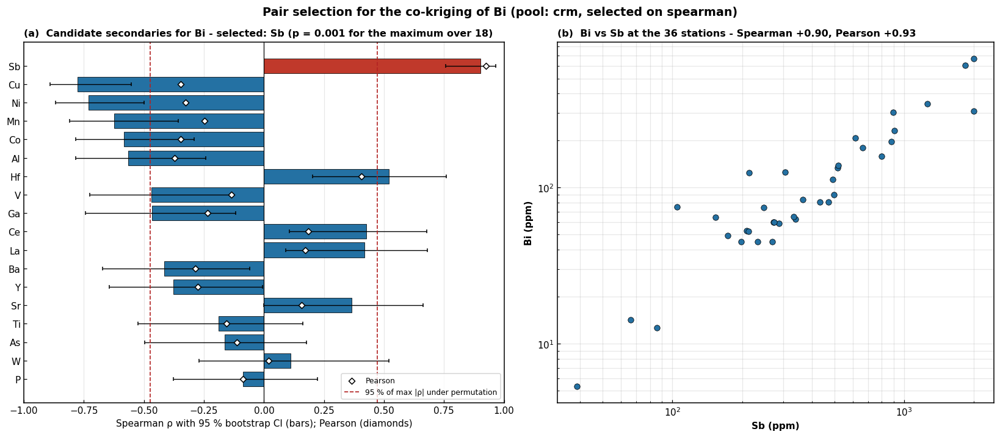

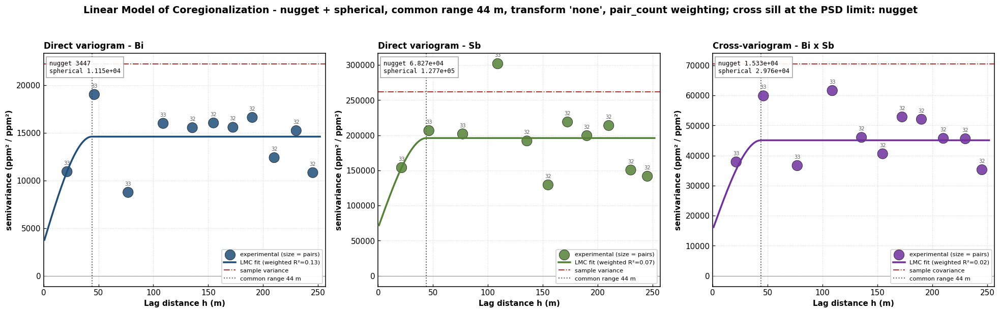

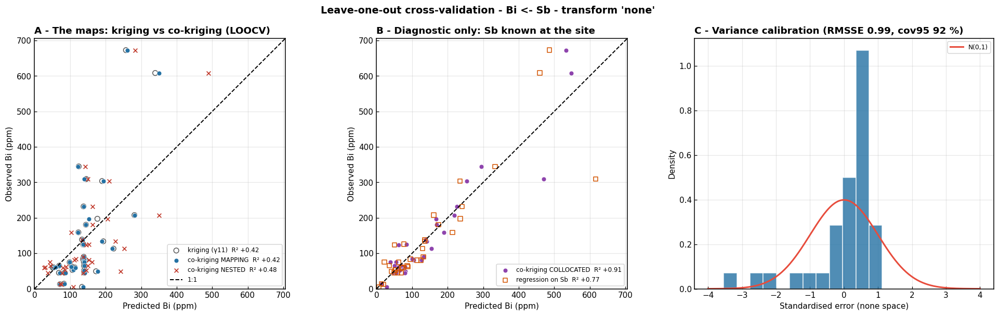

In [25]:
figure_pairs(VAR_NAME, outpath(VAR_NAME, f"CoK_{VAR_NAME}_pair_selection.png")); plt.show()
figure_lmc(VAR_NAME, outpath(VAR_NAME, f"CoK_{VAR_NAME}_LMC_variograms.png")); plt.show()
figure_cv(VAR_NAME, outpath(VAR_NAME, f"CoK_{VAR_NAME}_crossvalidation.png")); plt.show()

### 13.2 · The co-kriged grade map

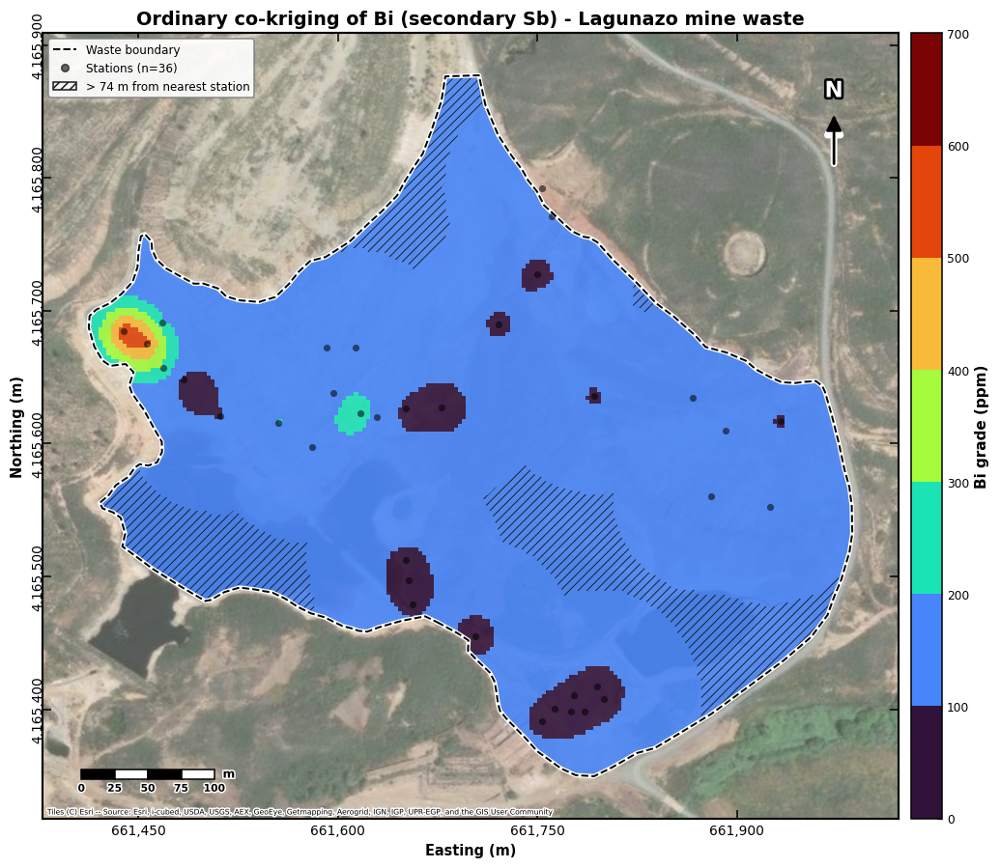

In [26]:
figure_grade_map(VAR_NAME, outpath(VAR_NAME, f"CoK_{VAR_NAME}_grade_map.png")); plt.show()

### 13.3 · Estimate and uncertainty

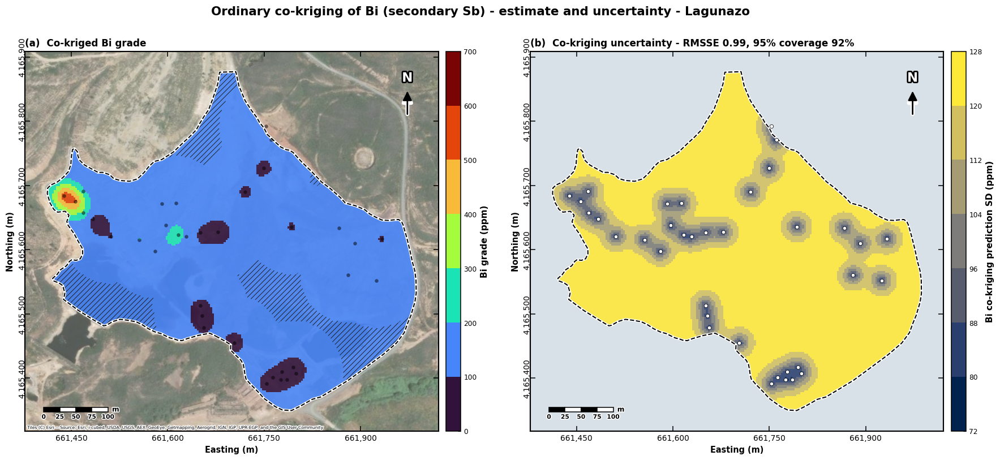

In [27]:
figure_grade_se(VAR_NAME, outpath(VAR_NAME, f"CoK_{VAR_NAME}_grade_and_SD.png")); plt.show()

### 13.4 · Kriging versus co-kriging, and what the covariate bought

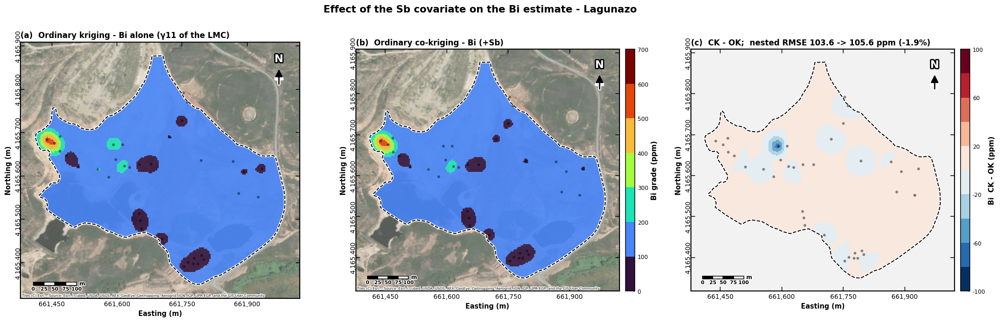

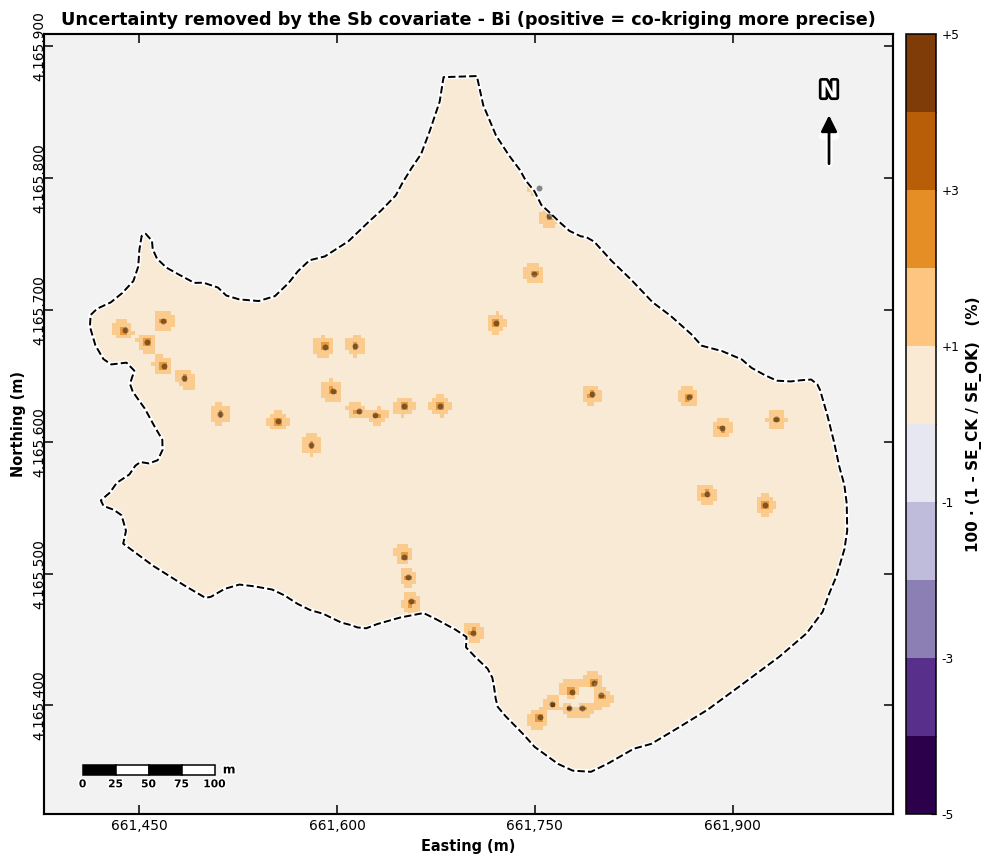

Detail figures saved -> results_CoK_ICP/Bi/


In [28]:
figure_ck_vs_ok(VAR_NAME, outpath(VAR_NAME, f"CoK_{VAR_NAME}_vs_OK_comparison.png")); plt.show()
figure_se_reduction(VAR_NAME, outpath(VAR_NAME, f"CoK_{VAR_NAME}_SE_reduction.png")); plt.show()
print(f"Detail figures saved -> {OUT_DIR}/{VAR_NAME}/")

## 14 · All Primaries - Figures, Rasters and Tables

Per primary, in `results_CoK_ICP/<element>/`: the LMC and cross-validation figures, and either the co-kriged grade
map, grade + uncertainty and CK-vs-OK figures (nested R² ≥ 0.10) or a posted-values map. Rasters (ESRI ASCII, 3 m
square cells, each with a `.prj` and a `_UNITS.txt`): co-kriged grade, paired kriged grade, prediction SD in grade
units, fit-space SE (log / nscore only) and the SE reduction in %. Rasters of primaries without skill carry
`_NO-SKILL` in the file name.

In [29]:
_CRS_WKT = pyproj.CRS(EPSG_UTM).to_wkt(version="WKT1_ESRI")
assert abs((xi[1] - xi[0]) - (yi[1] - yi[0])) < 1e-9, "grid cells must be square for ESRI ASCII (r1 fix K1)"

def write_esri_ascii(path, Z2D, note, nodata=-9999.0):
    arr = np.where(np.isfinite(Z2D), Z2D, nodata)[::-1, :]
    with open(path, "w") as fh:
        fh.write(f"ncols {arr.shape[1]}\nnrows {arr.shape[0]}\n")
        fh.write(f"xllcorner {xi.min() - GRID_DENSITY_M / 2:.3f}\nyllcorner {yi.min() - GRID_DENSITY_M / 2:.3f}\n")
        fh.write(f"cellsize {GRID_DENSITY_M:.4f}\nNODATA_value {nodata}\n")
        np.savetxt(fh, arr, fmt="%.6g")
    with open(path[:-4] + ".prj", "w") as fh:
        fh.write(_CRS_WKT)
    with open(path[:-4] + "_UNITS.txt", "w") as fh:
        fh.write(note + f"\nCRS: {EPSG_UTM}\ncellsize: {GRID_DENSITY_M} m (square)\nNODATA: {nodata}\n")
    return os.path.basename(path)

import gc

def _done(fig):
    """Free a figure immediately (the inline backend otherwise keeps every figure of a loop until the cell ends)."""
    fig.clf(); plt.close(fig)

RASTERS = []
_t0 = time.time()
_interactive = plt.isinteractive()
plt.ioff()
for el in FITTED:
    P, pk, g, N = RES[el], RES[el]["pick"], GRIDS[el], NESTED[el]
    u = unit_of(el); uu = u.replace("%", "pct"); sec = P["secondary"]
    if SAVE_ELEMENT_FIGURES and el != VAR_NAME:
        _done(figure_lmc(el, outpath(el, f"CoK_{el}_LMC_variograms.png")))
        _done(figure_cv(el, outpath(el, f"CoK_{el}_crossvalidation.png")))
        if el in SURF_ELS:
            _done(figure_grade_map(el, outpath(el, f"CoK_{el}_grade_map.png")))
            _done(figure_grade_se(el, outpath(el, f"CoK_{el}_grade_and_SD.png")))
            _done(figure_ck_vs_ok(el, outpath(el, f"CoK_{el}_vs_OK_comparison.png")))
        else:
            _done(figure_posted(el, outpath(el, f"CoK_{el}_posted_values_map.png")))
        gc.collect()
    tag = "" if el in SURF_ELS else "_NO-SKILL"
    base = f"{el} <- {sec}, transform '{pk['transform']}', LMC nugget+spherical range {pk['fit']['range_m']:.1f} m; " \
           f"nested-CV R2 {N['r2_ck']:.3f}" + (" - NO SKILL, descriptive only" if tag else "")
    RASTERS += [
        write_esri_ascii(outpath(el, f"CoK_{el}_cokriged_{uu}_UTM29N{tag}.asc"), g["CK"],
                         f"{el} ordinary co-kriged grade, {u}. {base}"),
        write_esri_ascii(outpath(el, f"CoK_{el}_kriged_{uu}_UTM29N{tag}.asc"), g["OK"],
                         f"{el} ordinary kriging (gamma_11 of the same LMC, global), {u} - the paired comparison."),
        write_esri_ascii(outpath(el, f"CoK_{el}_cokriging_sd_{uu}_UTM29N{tag}.asc"), g["SD_CK"],
                         f"{el} co-kriging prediction SD in {u} "
                         f"({'kriging SD' if pk['transform'] == 'none' else 'approximate, from the ' + pk['transform'] + ' back-transform'})."),
        write_esri_ascii(outpath(el, f"CoK_{el}_SE_reduction_pct_UTM29N{tag}.asc"), g["SERED"],
                         f"{el}: 100*(1 - SE_CK/SE_OK), percent, unit-free.")]
    if pk["transform"] != "none":
        RASTERS.append(write_esri_ascii(outpath(el, f"CoK_{el}_cokriging_se_{pk['transform']}space_UTM29N{tag}.asc"),
                                        g["SE_CK"], f"{el} co-kriging standard error in {pk['transform']} space - NOT {u}."))
    cv = pk["cv"]
    pd.DataFrame({"Station_samples": ST.loc[np.isfinite(ZST[el]), "Sample"].to_numpy(),
                  "X_utm": P["coords"][:, 0], "Y_utm": P["coords"][:, 1], f"{el}_obs_{uu}": P["z1"],
                  f"{sec}_obs_{unit_of(sec).replace('%', 'pct')}": P["z2"],
                  "kriging_pred": cv["kriging"]["pred"], "cokriging_mapping_pred": cv["mapping"]["pred"],
                  "cokriging_collocated_pred": cv["collocated"]["pred"], "regression_on_secondary_pred": cv["regression"]["pred"],
                  "nested_cokriging_pred": N["pred_ck"], "nested_kriging_pred": N["pred_ok"],
                  "mapping_std_error_fitspace": cv["mapping"]["zerr"],
                  "nested_fold_secondary": [p[0] for p in N["picks"]], "nested_fold_transform": [p[1] for p in N["picks"]]}
                 ).to_csv(outpath(el, f"CoK_{el}_crossvalidation_per_station.csv"), index=False)
    pk["vgm"].to_csv(outpath(el, f"CoK_{el}_experimental_variograms_{pk['transform']}.csv"), index=False)
    pd.DataFrame([dict(transform=t, structure=k, nugget=a["fit"]["coef"][k][0], spherical_sill=a["fit"]["coef"][k][1],
                       total_sill=sum(a["fit"]["coef"][k]), sample_var_or_cov=a["svar"][k], range_m=a["fit"]["range_m"],
                       on_bound=a["fit"]["on_bound"] or "-", weighted_fit_r2=a["fit"]["fit_r2"][k],
                       adopted=(a is pk)) for t, a in P["cands"].items() if a["status"] == "ok" for k in ("11", "22", "12")]
                 ).to_csv(outpath(el, f"CoK_{el}_LMC_coefficients.csv"), index=False)
    P["table"].to_csv(outpath(el, f"CoK_{el}_pair_candidates.csv"), index=False)
if _interactive:
    plt.ion()
print(f"Per-primary outputs for {len(FITTED)} primaries in {time.time() - _t0:.1f} s -> {OUT_DIR}/<element>/ "
      f"({len(RASTERS)} rasters)")

Per-primary outputs for 19 primaries in 370.0 s -> results_CoK_ICP/<element>/ (91 rasters)


## 15 · Atlas, Overview, Workbook and Manifest

The atlas shows the co-kriged surface where the nested R² ≥ 0.10 and the posted station values elsewhere, all in
station-percentile classes. The overview compares, per primary, the nested skill of co-kriging, kriging and IDW, and
what the covariate contributed.

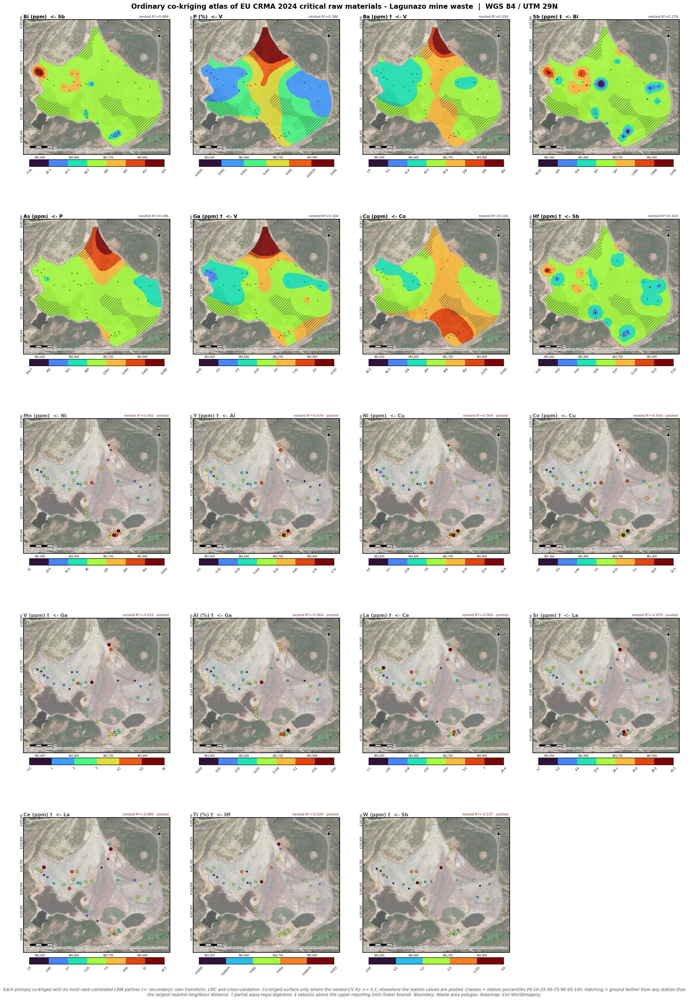

In [30]:
els = list(SUMMARY["Element"])
ncol = 4; nrow = int(math.ceil(len(els) / ncol))
asp = (ymax_u - ymin_u + 2 * pad_y) / (xmax_u - xmin_u + 2 * pad_x)
row_h = 5.0 * asp + 1.3; fig_h = row_h * nrow + 0.9
fig, axs = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, fig_h), gridspec_kw={"hspace": 0.36, "wspace": 0.12})
fig.subplots_adjust(top=1 - 0.75 / fig_h, bottom=1.1 / fig_h, left=0.03, right=0.99)
axs = np.atleast_2d(axs)
for ax, el in zip(axs.ravel(), els):
    P, g = RES[el], GRIDS[el]
    z1, xy = P["z1"], P["coords"]
    br = class_breaks([g["CK"]] if el in SURF_ELS else [z1], z1, "quantile")
    cm, nm = cmap_norm(br, GRADE_CMAP)
    add_basemap(ax)
    if el in SURF_ELS:
        draw_cells(ax, g["CK"], cm, nm)
        hatch_extrap(ax, g["EX"])
        ax.scatter(xy[:, 0], xy[:, 1], s=6, c="black", alpha=0.6, lw=0, zorder=11)
    else:
        ax.fill(px_utm, py_utm, fc="white", ec="none", alpha=0.18, zorder=1)
        cls = np.clip(np.digitize(z1, br[1:-1]), 0, len(br) - 2)
        o = np.argsort(z1)
        ax.scatter(xy[o, 0], xy[o, 1], s=22 * (0.55 + 0.3 * cls[o]), c=z1[o], cmap=cm, norm=nm, edgecolors="black",
                   linewidths=0.5, zorder=11)
    add_furniture(ax, label_axes=False, fs=0.55)
    ax.tick_params(labelsize=5.5)
    tag = (" †" if is_partial(el) else "") + (" ‡" if next(r for r in SCREEN if r["element"] == el)["n_above_UDL"] else "")
    ax.set_title(f"{el} ({unit_of(el)}){tag}  <- {P['secondary']}", fontsize=10.5, fontweight="bold", loc="left", pad=3,
                 color="black" if el in SURF_ELS else "#555")
    ax.text(0.99, 1.012, f"nested R²={NESTED[el]['r2_ck']:.3f}" + ("" if el in SURF_ELS else " - posted"),
            transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5, color="#333" if el in SURF_ELS else "#922b21")
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=nm, cmap=cm), ax=ax, orientation="horizontal", fraction=0.046,
                      pad=0.035, boundaries=br, ticks=br, spacing="uniform", format=mticker.FuncFormatter(fmt_tick))
    cb.ax.tick_params(labelsize=6, rotation=45)
for ax in axs.ravel()[len(els):]:
    ax.axis("off")
fig.suptitle("Ordinary co-kriging atlas of EU CRMA 2024 critical raw materials - Lagunazo mine waste  |  "
             "WGS 84 / UTM 29N", fontsize=15, fontweight="bold", y=1 - 0.25 / fig_h)
fig.text(0.5, 0.004, f"Each primary co-kriged with its most rank-correlated CRM partner (<- secondary): own transform, LMC and "
         f"cross-validation. Co-kriged surface only where the nested-CV R2 >= {MIN_R2_SURFACE:g}; elsewhere the station values "
         f"are posted. Classes = station percentiles P0-10-25-50-75-90-95-100. Hatching = ground farther from any station "
         f"than the largest nearest-neighbour distance. † partial aqua-regia digestion. ‡ value(s) above the upper "
         f"reporting limit (lower bound). Boundary: {BND_LABEL}. Basemap: Esri WorldImagery.", ha="center", va="bottom",
         fontsize=9, color="#555", style="italic", wrap=True)
fig.savefig(outpath("CoK_CRM_atlas_Lagunazo_ICP.png"), dpi=FIG_DPI, bbox_inches="tight")
fig.savefig(outpath("CoK_CRM_atlas_Lagunazo_ICP.pdf"), dpi=200, bbox_inches="tight")   # rasterised cells at 200 dpi
plt.show()

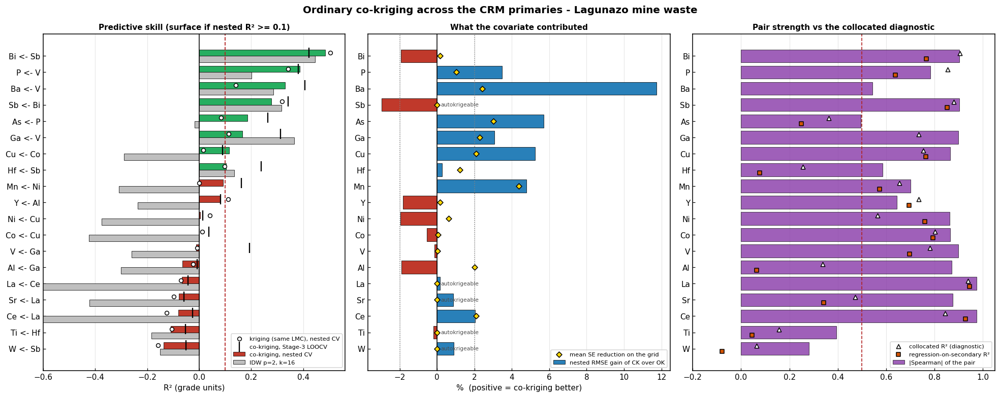

In [31]:
s = SUMMARY.sort_values("R2 CK nested")
fig, axes = plt.subplots(1, 3, figsize=(18, max(5.0, 0.38 * len(s))))
yy = np.arange(len(s))
ax = axes[0]
ax.barh(yy + 0.2, s["R2 CK nested"], height=0.4, color=np.where(s["R2 CK nested"] >= MIN_R2_SURFACE, "#27ae60", "#c0392b"),
        edgecolor="black", lw=0.5, label="co-kriging, nested CV")
ax.scatter(s["R2 OK nested"], yy + 0.2, marker="o", s=26, facecolors="white", edgecolors="black", zorder=5,
           label="kriging (same LMC), nested CV")
ax.scatter(s["R2 CK"], yy + 0.2, marker="|", s=160, color="black", zorder=5, label="co-kriging, Stage-3 LOOCV")
ax.barh(yy - 0.2, s["R2 IDW"], height=0.4, color="0.75", edgecolor="black", lw=0.5, label="IDW p=2, k=16")
ax.axvline(0, color="black", lw=1.0); ax.axvline(MIN_R2_SURFACE, color="firebrick", ls="--", lw=1.2)
ax.set_yticks(yy, [f"{e} <- {c}" for e, c in zip(s["Element"], s["Secondary"])]); ax.set_xlabel("R² (grade units)")
ax.set_xlim(max(-0.6, float(np.nanmin(s[["R2 CK nested", "R2 IDW", "R2 OK nested"]].to_numpy())) - 0.05), None)
ax.set_title(f"Predictive skill (surface if nested R² >= {MIN_R2_SURFACE:g})", fontsize=10, fontweight="bold")
ax.legend(fontsize=7.5, loc="lower right"); ax.grid(axis="x", alpha=0.3)
ax = axes[1]
ax.barh(yy, s["CK gain vs OK (nested) %"], color=np.where(s["CK gain vs OK (nested) %"] > 0, "#2980b9", "#c0392b"),
        edgecolor="black", lw=0.5, label="nested RMSE gain of CK over OK")
ax.scatter(s["Mean SE reduction %"], yy, marker="D", s=26, c="gold", edgecolors="black", zorder=5,
           label="mean SE reduction on the grid")
for i, a in enumerate(s["Autokrigeable"]):
    if a == "yes":
        ax.text(0.2, i, "autokrigeable", va="center", fontsize=7, color="0.3")
ax.axvline(0, color="black", lw=1.0)
for x_ in (-CK_GAIN_MIN_PCT, CK_GAIN_MIN_PCT):
    ax.axvline(x_, color="0.5", ls=":", lw=1)
ax.set_yticks(yy, s["Element"]); ax.set_xlabel("%  (positive = co-kriging better)")
ax.set_title("What the covariate contributed", fontsize=10, fontweight="bold")
ax.legend(fontsize=7.5, loc="lower right"); ax.grid(axis="x", alpha=0.3)
ax = axes[2]
ax.barh(yy, s["Spearman"].abs(), color="#8e44ad", edgecolor="black", lw=0.5, alpha=0.85, label="|Spearman| of the pair")
ax.scatter(s["R2 collocated"], yy + 0.18, marker="^", s=30, c="white", edgecolors="black", zorder=5,
           label="collocated R² (diagnostic)")
ax.scatter(s["R2 regression"], yy - 0.18, marker="s", s=24, c="#d35400", edgecolors="black", zorder=5,
           label="regression-on-secondary R²")
ax.axvline(WEAK_PAIR_ABS_RHO, color="firebrick", ls="--", lw=1.1)
ax.set_yticks(yy, s["Element"]); ax.set_xlim(-0.2, 1.05)
ax.set_title("Pair strength vs the collocated diagnostic", fontsize=10, fontweight="bold")
ax.legend(fontsize=7.5, loc="lower right"); ax.grid(axis="x", alpha=0.3)
fig.suptitle("Ordinary co-kriging across the CRM primaries - Lagunazo mine waste", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(outpath("CoK_overview_all_primaries.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

In [32]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

SCREEN_DF.to_csv(outpath("screening.csv"), index=False)
PAIRS_DF.to_csv(outpath("pair_selection.csv"), index=False)
TRIALS_DF.to_csv(outpath("transform_trials.csv"), index=False)
SUMMARY.to_csv(outpath("summary_all_primaries.csv"), index=False)
AUDIT_TBL.to_csv(outpath(f"audit_{VAR_NAME}.csv"), index=False)
pd.DataFrame(QC_LOG).to_csv(outpath("qc_log.csv"), index=False)
if MC_TABLE is not None:
    MC_TABLE.to_csv(outpath(f"audit_{VAR_NAME}_lognormal_montecarlo.csv"), index=False)

LMC_ALL = pd.DataFrame([dict(primary=el, secondary=RES[el]["secondary"], transform=RES[el]["pick"]["transform"],
                             structure=k, nugget=RES[el]["pick"]["fit"]["coef"][k][0],
                             spherical_sill=RES[el]["pick"]["fit"]["coef"][k][1],
                             range_m=RES[el]["pick"]["fit"]["range_m"], on_bound=RES[el]["pick"]["fit"]["on_bound"] or "-",
                             weighted_fit_r2=RES[el]["pick"]["fit"]["fit_r2"][k],
                             sample_var_or_cov=RES[el]["pick"]["svar"][k]) for el in FITTED for k in ("11", "22", "12")])
grid_tab = pd.DataFrame({"Easting_m": XG.ravel()[INSIDE], "Northing_m": YG.ravel()[INSIDE]})
for el in SURF_ELS:
    grid_tab[f"{el}_CoK_{unit_of(el)}"] = GRIDS[el]["CK"].ravel()[INSIDE]
    grid_tab[f"{el}_CoK_SD_{unit_of(el)}"] = GRIDS[el]["SD_CK"].ravel()[INSIDE]
    grid_tab[f"{el}_OK_{unit_of(el)}"] = GRIDS[el]["OK"].ravel()[INSIDE]

OUTPUT_XLS = outpath("CoK_ICP_Lagunazo_CRM_Analysis.xlsx")
sheets = [("CRM_Identification", CRM_TABLE), ("CRM_Elements", CRM_ELEMENTS), ("CRM_Not_Covered", CRM_NOT_COVERED),
          ("Digestion_Check", DIGESTION_CHECK), ("QC_Pulp_Duplicate", QC_DUP), ("QC_Standards", QC_STD),
          ("Sample_Reconciliation", SAMP.drop(columns=["_key"])), ("Screening", SCREEN_DF),
          ("Pair_Selection", PAIRS_DF), (f"Pair_Candidates_{VAR_NAME}", RES[VAR_NAME]["table"]),
          ("Transform_Trials", TRIALS_DF), ("LMC_Coefficients", LMC_ALL), ("Summary", SUMMARY),
          (f"Audit_{VAR_NAME}", AUDIT_TBL)]
if MC_TABLE is not None:
    sheets.append(("Audit_Lognormal_MC", MC_TABLE))
sheets += [("QC_Log", pd.DataFrame(QC_LOG)), ("Grid_Surfaces", grid_tab)]
with pd.ExcelWriter(OUTPUT_XLS, engine="openpyxl") as xw:
    for name, df_ in sheets:
        df_.to_excel(xw, sheet_name=name[:31], index=False)
    for ws in xw.book.worksheets:
        for c in ws[1]:
            c.fill = PatternFill("solid", fgColor="1A5276"); c.font = Font(bold=True, color="FFFFFF", size=10)
            c.alignment = Alignment(horizontal="center", wrap_text=True)
        for col in ws.iter_cols(min_row=1, max_row=min(ws.max_row, 200)):
            ws.column_dimensions[get_column_letter(col[0].column)].width = min(max(
                max(len(str(c.value)) if c.value is not None else 0 for c in col) + 2, 8), 40)
        ws.freeze_panes = "A2"

def _sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def _clean(v):
    if isinstance(v, (np.floating, float)):
        return None if not np.isfinite(v) else float(v)
    return v.item() if hasattr(v, "item") else v

MANIFEST = dict(
    notebook="CoK_ICP_Lagunazo_CRM.ipynb", run_started_utc=RUN_STARTED,
    run_finished_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
    environment=dict(python=platform.python_version(), platform=platform.platform(), numpy=np.__version__,
                     pandas=pd.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__,
                     pyproj=pyproj.__version__, shapely=getattr(shapely, "__version__", "not installed"),
                     contextily=getattr(ctx, "__version__", "not installed")),
    inputs={p: ({"sha256": _sha(p), "bytes": os.path.getsize(p)} if Path(p).exists() else "missing")
            for p in (ICP_XLSX, KMZ_FILE)},
    boundary=dict(label=BND_LABEL, polygons=int(N_POLY), interior_rings=int(N_HOLES)),
    grid=dict(ncols=int(NCOL), nrows=int(NROW), cellsize_m=GRID_DENSITY_M, cells_square=True,
              nodes_in_domain=int(INSIDE.sum()), xllcorner=float(xi.min() - GRID_DENSITY_M / 2),
              yllcorner=float(yi.min() - GRID_DENSITY_M / 2)),
    config={k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
            for k, v in sorted(globals().items()) if k.isupper() and k == k.strip("_")
            and isinstance(v, (int, float, str, bool, list, tuple, dict, type(None))) and len(str(v)) < 400},
    primaries=PRIMARIES, secondary_pool=POOL, failed=FAILED, surfaces=SURF_ELS, posted_values=POST_ELS,
    pairs={r["primary"]: r["secondary"] for r in PAIR_ROWS},
    results={r["Element"]: {k: _clean(v_) for k, v_ in r.items()} for r in SUMMARY.to_dict(orient="records")},
    qc_log=QC_LOG)
with open(outpath("run_manifest.json"), "w", encoding="utf-8") as fh:
    json.dump(MANIFEST, fh, indent=2, default=str)
print(f"Workbook -> {OUTPUT_XLS}\nManifest -> {outpath('run_manifest.json')}")

Workbook -> results_CoK_ICP\CoK_ICP_Lagunazo_CRM_Analysis.xlsx
Manifest -> results_CoK_ICP\run_manifest.json


## 16 · Summary

In [33]:
el = VAR_NAME
P, pk, N = RES[el], RES[el]["pick"], NESTED[el]
cv = pk["cv"]
print("=" * 86)
print(f"  ORDINARY CO-KRIGING COMPLETE - Lagunazo ICP (EU CRMA 2024)")
print("=" * 86)
print(f"  Samples / stations        : {int(LOCATED.sum())} located ({ST_REP['n_samples']} with AQ251) -> "
      f"{len(ST)} stations at {STATION_TOL_M:g} m; boundary = {BND_LABEL}")
print(f"  CRM identified            : " + ", ".join(CRM_ELEMENTS.loc[CRM_ELEMENTS['Status'] == 'identified', 'Element']))
print(f"  Primaries co-kriged       : {len(FITTED)}  (pool '{SECONDARY_POOL}', {len(POOL)} analytes)")
print(f"  Co-kriged surfaces        : " + (", ".join(f"{e} <- {RES[e]['secondary']} (nested R2 {NESTED[e]['r2_ck']:.2f})"
                                                  for e in SURF_ELS) or "none"))
print(f"  Posted values             : " + (", ".join(POST_ELS) or "none") + f"  (nested R2 < {MIN_R2_SURFACE:g})")
_g = SUMMARY["CK gain vs OK (nested) %"]
print(f"  Covariate contribution    : nested RMSE change CK vs OK median {_g.median():+.1f} % "
      f"(range {_g.min():+.1f} to {_g.max():+.1f} %); mean SE reduction on the grid "
      f"{SUMMARY['Mean SE reduction %'].median():.1f} % (median over primaries)")
print()
print(f"  DETAIL PRIMARY {el} <- {P['secondary']}   (transform '{pk['transform']}', common range "
      f"{pk['fit']['range_m']:.1f} m{', ON BOUND' if pk['fit']['on_bound'] else ''})")
print(f"  {'LOOCV predictor':<36}{'RMSE':>10}{'R2':>8}{'RMSSE':>8}{'cov95':>8}")
for key, label in (("kriging", "Ordinary kriging (same LMC)"), ("mapping", "Co-kriging (MAPPING = the maps)"),
                   ("collocated", "Co-kriging (collocated, diagnostic)"),
                   ("regression", f"Regression on {P['secondary']}")):
    s_ = cv[key]
    rm = f"{s_['rmsse']:.2f}" if np.isfinite(s_["rmsse"]) else "   -"
    cc = f"{s_['cov95']:.0f}" if np.isfinite(s_["cov95"]) else "   -"
    print(f"  {label:<36}{fmt_num(s_['rmse']):>10}{s_['r2']:>8.3f}{rm:>8}{cc:>8}")
print(f"  {'Co-kriging, NESTED (whole procedure)':<36}{fmt_num(N['rmse_ck']):>10}{N['r2_ck']:>8.3f}")
print(f"  {'Kriging, NESTED':<36}{fmt_num(N['rmse_ok']):>10}{N['r2_ok']:>8.3f}")
print()
print("  READING OF THE RESULT")
print(f"    Co-kriging changes the nested RMSE of {el} by {N['gain_pct']:+.1f} % against kriging with the same LMC.")
print(f"    Sampling is isotopic, so the secondary is absent at every grid node: near-equality is the correct answer.")
print(f"    The collocated R2 ({cv['collocated']['r2']:.2f}) is set beside regression on {P['secondary']} "
      f"({cv['regression']['r2']:.2f}): it describes the pair's correlation, not the maps,")
print(f"    and {el} and {P['secondary']} come from ONE aqua-regia digest, so no survey can densify the secondary alone.")
if N["r2_ck"] <= 0.30:
    print(f"    Nested R2 = {N['r2_ck']:+.2f}: a scoping-level Exploration Target (JORC/PERC terms), not a grade model.")
print(f"  Audit ({el})              : {int((AUDIT_TBL['Status'] == 'PASS').sum())} PASS / "
      f"{int((AUDIT_TBL['Status'] == 'WARN').sum())} WARN / {int((AUDIT_TBL['Status'] == 'INFO').sum())} INFO / 0 FAIL")
drops = [e for e in QC_LOG if e["level"] == "DROP"]; warns = [e for e in QC_LOG if e["level"] == "WARN"]
print(f"  Quality events            : {len(drops)} DROP, {len(warns)} WARN, {len(QC_LOG) - len(drops) - len(warns)} INFO")
print(f"  Outputs                   : {OUT_DIR}/ (per-primary folders, atlas, overview, workbook, manifest)")
print("=" * 86)
print("\nQuality log:")
qc_report()

  ORDINARY CO-KRIGING COMPLETE - Lagunazo ICP (EU CRMA 2024)
  Samples / stations        : 40 located (36 with AQ251) -> 36 stations at 5 m; boundary = Waste area polygon
  CRM identified            : Al, Sb, As, Ba, Be, Bi, B, Co, Cu, Ga, Ge, Hf, Y, La, Ce, Li, Mg, Mn, Ni, Nb, P, Pd, Pt, Sc, Si, Sr, Ti, W, V
  Primaries co-kriged       : 19  (pool 'crm', 19 analytes)
  Co-kriged surfaces        : Bi <- Sb (nested R2 0.48), P <- V (nested R2 0.39), Ba <- V (nested R2 0.33), Sb <- Bi (nested R2 0.28), As <- P (nested R2 0.19), Ga <- V (nested R2 0.17), Cu <- Co (nested R2 0.12), Hf <- Sb (nested R2 0.10)
  Posted values             : Mn, Y, Ni, Co, V, Al, La, Sr, Ce, Ti, W  (nested R2 < 0.1)
  Covariate contribution    : nested RMSE change CK vs OK median +0.3 % (range -3.0 to +11.7 %); mean SE reduction on the grid 0.6 % (median over primaries)

  DETAIL PRIMARY Bi <- Sb   (transform 'none', common range 44.1 m)
  LOOCV predictor                           RMSE      R2   RMSSE   cov95
 